# CamoAug with TAPL: Multi-Class Fraud Detection under Camouflage Drift

Experiment notebook for *A Novel Camouflage Augmentation with Trust-Aware Pseudo-Labeling Method for Enhancing Model
Robustness in Multi-Class Fraud Detection under Data Drift*. It runs the whole pipeline from the raw data to the final tables and figures:

data loading and quality checks → preprocessing and chronological split → exploratory and drift analysis →
CamoAug and TAPL → comparators → main experiment (10 seeds) → mechanism analysis → ablations → robustness and
simulated drift → sensitivity → leakage audit → export of tables and figures.

**Rules held throughout**
- No label of the April stream is used by any method, neither to choose a parameter, a threshold, a pseudo-label nor
  a retraining decision. Stream labels are used only for evaluation and for clearly marked descriptive analyses; the
  leakage audit at the end verifies this.
- All thresholds are calibrated on TRAIN and VALIDATION only, and all hyper-parameters are fixed in the configuration
  cell.
- All comparisons are paired by seed, with Holm correction inside each family of tests.
- The values reported in the manuscript appear only in the final check, as historical reference values next to the
  values of this run; they are never used in a computation.

**How to run.** Run all cells from top to bottom on a GPU. `QUICK_TEST = True` is only a fast smoke test of the code;
its numbers must not be reported. The main experiment is checkpointed after every seed, so an interrupted run resumes
where it stopped. Expected runtime on a Kaggle GPU: about 4 hours. Tables are written to `tables/` (CSV) and figures to
`figures/` (PNG 300 dpi and PDF).

## Environment and configuration

In [4]:
import time as _time_boot
NOTEBOOK_T0 = _time_boot.time()          # start marker for the total wall time
import os, subprocess, sys, time, json, glob, warnings, shutil, inspect, re, pickle, dataclasses
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ks_2samp, wilcoxon, friedmanchisquare, fisher_exact, spearmanr

try:
    import xgboost as xgb
except ImportError:                                   # pragma: no cover
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
    import xgboost as xgb

import sklearn
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (f1_score, precision_recall_fscore_support, average_precision_score,
                             balanced_accuracy_score, matthews_corrcoef, accuracy_score,
                             recall_score, log_loss)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 500)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| xgboost", xgb.__version__, "| scikit-learn", sklearn.__version__, "| scipy", __import__("scipy").__version__)

ENV = dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__, xgboost=xgb.__version__,
           scikit_learn=sklearn.__version__, scipy=__import__("scipy").__version__, matplotlib=matplotlib.__version__)

python 3.13.16 | numpy 2.1.3 | pandas 2.3.3 | xgboost 3.4.1 | scikit-learn 1.6.1 | scipy 1.16.3


### Configuration
Every hyper-parameter of every method is defined here and nowhere else.
`TAPL["rec_fpr"]` is the size `eps` of the Neyman-Pearson test **and** the false-positive budget `eps_0` of BLB:
both use the same value (5e-4), so they are one parameter in the code.

In [5]:
QUICK_TEST = False          # True: fast smoke test of the code, NOT for reporting

CFG = dict(
    target="fraud_type",
    time_col="timestamp",
    time_formats=["%m-%d-%y %H:%M", "%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M", "%m/%d/%Y %H:%M"],
    expected_classes=["legit", "identity_theft", "account_takeover",
                      "card_testing", "fraud_ring", "synthetic_identity"],
    # TRAIN 1 Jan - 20 Mar 2025, VALIDATION 21 - 31 Mar 2025, STREAM 1 - 29 Apr 2025 (end dates are exclusive)
    split=dict(train_start="2025-01-01", train_end="2025-03-21",
               val_end="2025-04-01", test_end="2025-04-30"),
    # Columns removed before the feature audit, with the reason
    exclude={
        "transaction_id": "identifier",
        "customer_id": "identifier",
        "merchant_id": "identifier",
        "device_id": "identifier",
        "timestamp": "used only for the chronological split",
        "day": "day-of-period counter: a time proxy that never repeats across splits",
        "label": "binary version of the target (direct leakage)",
        "financial_loss": "known only after the fraud outcome is known (post-event leakage)",
    },
    leak_balacc_threshold=0.99,   # single-feature balanced accuracy on VALIDATION >= this -> leakage
    time_proxy_ks=0.99,           # KS(train vs validation) >= this -> time proxy
    batch_size=5000,
    # Base model of every method
    xgb=dict(objective="multi:softprob", n_estimators=300, max_depth=6, learning_rate=0.05,
             subsample=0.8, colsample_bytree=0.8, eval_metric="mlogloss",
             tree_method="hist", n_jobs=-1),
    # CamoAug; also the shared synthetic budget of A2-A5
    camo=dict(rho=0.2, gamma=2.0, ratio=1.0, lam=0.5, n_donor=5, clip=0.95, n_rest=4000, n_probe=2000),
    final=dict(alpha=2.0, rho=0.2, e_min=0.5),
    # Augmentation comparators A2-A5
    aug=dict(smote_k=5, adasyn_k=5, mixup_alpha=0.4),
    # Shared retraining protocol: anchor beta, pseudo-label weight, cap factor eta, window, gate delta
    stream=dict(anchor_w=0.5, pl_weight=0.5, cap_factor=5.0, window=3, gate_delta=0.02),
    fixmatch_tau=0.95,
    freematch_ema=0.999,
    SEEDS=list(range(42, 52)),            # 10 seeds, 42-51
    margin=0.01,                          # F1 tolerance of the safety check in the rho / e_min selection procedure
    alpha_sig=0.05,
)

# TAPL hyper-parameters
TAPL = dict(
    veto_pct=95,       # tau_k: percentile of the strongest alternative class among correct class-k VALIDATION rows
    conf_q=10,         # T_k: percentile of the confidence of correct class-k VALIDATION rows
    conf_floor=0.50,   # lower bound of T_k
    rec_fpr=5e-4,      # eps of NP-Recovery = eps_0 of BLB
    w_recover=0.3,     # sample weight of recovered pseudo-labels
    blb_grid=tuple(np.round(np.arange(0.0, 4.01, 0.25), 2)), blb_sweeps=2, blb_margin=0.01,
)

# R4 (IW) and R5 (CT)
EXT = dict(iw_gamma=0.5, iw_clip=(0.1, 10.0), iw_sub=30000, iw_target_batches=3,
           ct_trees=60, ct_major_sub=30000)

# Seeds of every experiment (as reported in the article)
SEEDS = dict(main=CFG["SEEDS"],               # main experiment
             mechanism=CFG["SEEDS"][:5],      # extra mechanism runs
             rolling=CFG["SEEDS"][:5],        # rolling windows (drift severity)
             scenarios=CFG["SEEDS"],          # simulated drift scenarios
             sensitivity=CFG["SEEDS"][:3],    # one-at-a-time sensitivity
             selection=CFG["SEEDS"][:3],      # selection procedure for rho and e_min
             leakage=CFG["SEEDS"][:1])        # label-randomisation test

if QUICK_TEST:
    CFG["SEEDS"] = [42, 43]
    CFG["xgb"]["n_estimators"] = 40
    CFG["camo"]["n_probe"] = 300
    CFG["camo"]["n_rest"] = 800
    CFG["batch_size"] = 1500
    EXT["iw_sub"] = 5000; EXT["ct_trees"] = 20; EXT["ct_major_sub"] = 5000
    SEEDS = {k: CFG["SEEDS"][:1] if k in ("leakage",) else CFG["SEEDS"] for k in SEEDS}

try:
    import torch
    HAS_CUDA = torch.cuda.is_available()
except Exception:
    HAS_CUDA = shutil.which("nvidia-smi") is not None
if HAS_CUDA:
    CFG["xgb"]["device"] = "cuda"

OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
RUN_DIR = os.path.join(OUT_DIR, "run")              # intermediate files and checkpoints
TAB_DIR = os.path.join(OUT_DIR, "tables")           # publication tables (CSV)
FIG_DIR = os.path.join(OUT_DIR, "figures")          # publication figures (PNG 300 dpi + PDF)
for _d in (RUN_DIR, TAB_DIR, FIG_DIR):
    os.makedirs(_d, exist_ok=True)


def out_path(name): return os.path.join(RUN_DIR, name)


def save_table(df, name, index=False, show=True):
    """Write a publication table to tables/<name>.csv and print it."""
    df.to_csv(os.path.join(TAB_DIR, f"{name}.csv"), index=index)
    if show:
        print(f"[saved tables/{name}.csv]")
        print(df.to_string(index=index))


def save_fig(fig, name):
    """Write a publication figure as PNG (300 dpi) and PDF."""
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"), dpi=300, bbox_inches="tight")
    print(f"[saved figures/{name}.png and .pdf]")


plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
                     "figure.dpi": 110, "savefig.dpi": 300})

# ---- reproducibility: library versions and hardware of the reference run ----------------------------
EXPECTED_VERSIONS = dict(python="3.13", numpy="2.1.3", pandas="2.3.3", xgboost="3.4.1",
                         scikit_learn="1.6.1", scipy="1.16.3")
_bad = {k: (ENV[k], v) for k, v in EXPECTED_VERSIONS.items() if not str(ENV[k]).startswith(v)}
if _bad:
    print("WARNING: library versions differ from the reference run; results may differ slightly.")
    for k, (have, want) in _bad.items():
        print(f"   {k}: installed {have}, reference {want}")
    print("   To match: pip install " + " ".join(f"{k.replace('_', '-')}=={v}" for k, v in EXPECTED_VERSIONS.items()
                                                  if k != "python") + "  (then restart the kernel)")
else:
    print("Library versions match the reference run.")
try:
    GPU_NAME = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"], capture_output=True,
                              text=True, timeout=20).stdout.strip() or "none"
except Exception:
    GPU_NAME = "none"
ENV["gpu"] = GPU_NAME
print(f"GPU: {GPU_NAME}. XGBoost results are bit-identical only on the same GPU type and library versions; "
      f"on other hardware they can differ in the third or fourth decimal.")


def rhu(x, nd=0):
    """Round half up (away from zero), the rounding used for every reported number (Python's round() rounds to even)."""
    from decimal import Decimal, ROUND_HALF_UP
    if x is None or (isinstance(x, float) and not np.isfinite(x)):
        return x
    q = Decimal(1).scaleb(-nd)
    v = Decimal(repr(float(x))).quantize(q, rounding=ROUND_HALF_UP)
    return int(v) if nd == 0 else float(v)


def fmt_signed(x, nd=3):
    return f"{rhu(x, nd):+.{nd}f}"


with open(os.path.join(OUT_DIR, "env.json"), "w") as fh:
    json.dump(dict(ENV, cuda=bool(HAS_CUDA), quick_test=QUICK_TEST), fh, indent=2)
with open(os.path.join(OUT_DIR, "config.json"), "w") as fh:
    json.dump(dict(CFG=CFG, TAPL={k: (list(v) if isinstance(v, tuple) else v) for k, v in TAPL.items()},
                   EXT=EXT, SEEDS=SEEDS), fh, indent=2, default=str)

# Hyper-parameter summary, generated from the configuration above
T6 = pd.DataFrame([
    dict(component="XGBoost (all models)",
         hyperparameters=f"{CFG['xgb']['n_estimators']} trees, max depth {CFG['xgb']['max_depth']}, learning rate "
                         f"{CFG['xgb']['learning_rate']}, subsample {CFG['xgb']['subsample']}, colsample "
                         f"{CFG['xgb']['colsample_bytree']}, balanced class weights"),
    dict(component="CamoAug",
         hyperparameters=f"rho = {CFG['final']['rho']}, gamma = {CFG['camo']['gamma']}, n_donor = {CFG['camo']['n_donor']}, "
                         f"alpha = {CFG['final']['alpha']}, e_min = {CFG['final']['e_min']}, lambda = {CFG['camo']['lam']}, "
                         f"budget ratio {CFG['camo']['ratio']}, q clipped at {CFG['camo']['clip']}"),
    dict(component="TAPL filter and NP-Recovery",
         hyperparameters=f"T_k: {TAPL['conf_q']}th percentile (floor {TAPL['conf_floor']}); tau_k: {TAPL['veto_pct']}th "
                         f"percentile; NP size eps = {TAPL['rec_fpr']}; recovered weight {TAPL['w_recover']}"),
    dict(component="Retraining protocol",
         hyperparameters=f"anchor beta = {CFG['stream']['anchor_w']}, pseudo-label weight {CFG['stream']['pl_weight']}, "
                         f"window of {CFG['stream']['window']} batches, cap factor eta = {CFG['stream']['cap_factor']}, "
                         f"gate delta = {CFG['stream']['gate_delta']}"),
    dict(component="BLB",
         hyperparameters=f"eps_0 = {TAPL['rec_fpr']} (same parameter as the NP size), grid 0-{max(TAPL['blb_grid'])} in steps "
                         f"of 0.25, {TAPL['blb_sweeps']} sweeps, F1 margin {TAPL['blb_margin']}, reference = largest class"),
    dict(component="Comparators",
         hyperparameters=f"FixMatch tau = {CFG['fixmatch_tau']}; FreeMatch EMA {CFG['freematch_ema']}; IW exponent "
                         f"{EXT['iw_gamma']}, clip {list(EXT['iw_clip'])}; CT {EXT['ct_trees']} ExtraTrees; SMOTE/ADASYN "
                         f"k = {CFG['aug']['smote_k']}; Mixup alpha = {CFG['aug']['mixup_alpha']}"),
])
save_table(T6, "table6_hyperparameters")
print(f"\nCUDA: {HAS_CUDA} | seeds: {SEEDS} | QUICK_TEST = {QUICK_TEST}")
print("Environment:", ENV)

Library versions match the reference run.
GPU: Tesla T4
Tesla T4. XGBoost results are bit-identical only on the same GPU type and library versions; on other hardware they can differ in the third or fourth decimal.
[saved tables/table6_hyperparameters.csv]
                  component                                                                                                                      hyperparameters
       XGBoost (all models)                                     300 trees, max depth 6, learning rate 0.05, subsample 0.8, colsample 0.8, balanced class weights
                    CamoAug                     rho = 0.2, gamma = 2.0, n_donor = 5, alpha = 2.0, e_min = 0.5, lambda = 0.5, budget ratio 1.0, q clipped at 0.95
TAPL filter and NP-Recovery                                 T_k: 10th percentile (floor 0.5); tau_k: 95th percentile; NP size eps = 0.0005; recovered weight 0.3
        Retraining protocol                             anchor beta = 0.5, pseudo-label weight 0.5, 

### Dataset location
Set `DATA_PATH` to the CSV file or to a folder. If the file is not found, the usual input folders are searched for
`enterprise_fraud*.csv`.

In [6]:
# Public source: https://www.kaggle.com/datasets/mohamedadeldesak/enterprise-fraud-dataset
# The dataset is taken from the notebook inputs if it was added with "+ Add Input"; otherwise it is downloaded
# with kagglehub (needs internet). To make the run reproducible, pin the version that was used, for example
# KAGGLE_HANDLE = "mohamedadeldesak/enterprise-fraud-dataset/versions/1"
KAGGLE_HANDLE = "mohamedadeldesak/enterprise-fraud-dataset"
DATA_PATH = "/kaggle/input/datasets/mohamedadeldesak/enterprise-fraud-dataset"   # CSV file or dataset folder
NAME_PATTERN = "enterprise_fraud*.csv"
SEARCH_ROOTS = ["/kaggle/input/enterprise-fraud-dataset", "/kaggle/input", "/mnt/user-data/uploads", "."]


def first_csv(folder, pattern="*.csv"):
    hits = sorted(glob.glob(os.path.join(folder, "**", pattern), recursive=True))
    if len(hits) > 1:
        print("Several CSV files found; using the first:", hits)
    return hits[0] if hits else None


def locate_dataset():
    if DATA_PATH and os.path.isfile(DATA_PATH):
        return DATA_PATH
    if DATA_PATH and os.path.isdir(DATA_PATH) and first_csv(DATA_PATH):
        return first_csv(DATA_PATH)
    try:                                                         # download with kagglehub
        import kagglehub
        folder = kagglehub.dataset_download(KAGGLE_HANDLE)
        print("downloaded with kagglehub:", KAGGLE_HANDLE, "->", folder)
        if first_csv(folder):
            return first_csv(folder)
    except Exception as e:
        print(f"kagglehub download not available ({type(e).__name__}: {e}); searching local folders")
    for root in SEARCH_ROOTS:
        hit = first_csv(root, NAME_PATTERN)
        if hit:
            return hit
    raise FileNotFoundError("Dataset not found. Add the Kaggle dataset as input, enable internet, "
                            "or set DATA_PATH to the CSV file or its folder.")


DATA_FILE = locate_dataset()
raw = pd.read_csv(DATA_FILE)
print("dataset:", DATA_FILE, "| shape:", raw.shape)
raw.head(3)

dataset: /kaggle/input/datasets/mohamedadeldesak/enterprise-fraud-dataset/enterprise_fraud_dataset.csv | shape: (200000, 44)


,transaction_id,customer_id,merchant_id,timestamp,hour,day,weekday,is_weekend,is_night,customer_segment,avg_spend_profile,home_lat,home_lon,past_fraud_history,credit_score,account_age_days,merchant_category,merchant_risk_score,merchant_lat,merchant_lon,transaction_amount,txn_lat,txn_lon,distance_from_home_km,is_foreign,high_risk_country,device_type,channel,is_new_device,vpn_detected,tor_detected,device_id,transaction_velocity_1h,transaction_velocity_24h,transaction_velocity_7d,seconds_since_last_txn,avg_amount_30d,amount_deviation_ratio,merchant_ring_id,shared_device_count,customer_merchant_txn_count,label,fraud_type,financial_loss
0,TXN00000000,10401,1674,1-1-25 0:00,0,1,2,0,1,regular,356.8117,29.4608,35.3933,0,597,2534,retail,0.1965,30.4395,31.3056,306.7000,25.5640,34.4608,441.8300,1,0,desktop_chrome,online,0,0,0,e634769b1a49,1,6,15,99999.0000,362.8483,0.8429,-1,0,2,0,legit,0.0000
1,TXN00000001,7486,1139,1-1-25 0:01,0,1,2,0,1,dormant,284.0597,30.1414,31.1978,0,766,1126,electronics,0.2185,31.7429,33.7669,169.5200,31.1962,32.0564,143.1900,0,0,desktop_chrome,online,0,0,0,90b854d61e3a,0,9,22,1371350.4800,243.4204,0.6936,-1,0,3,0,legit,0.0000
2,TXN00000002,9687,1986,1-1-25 0:01,0,1,2,0,1,premium,961.9338,23.5271,33.9124,0,557,3723,retail,0.1870,29.5468,27.3158,1182.4500,22.8927,31.4876,256.6300,0,0,mobile_ios,online,0,0,0,ac51238a6a6f,3,5,25,382509.5766,812.7694,1.4531,-1,1,3,0,legit,0.0000


## Dataset and data quality
Missing values, duplicates, the time range, the column inventory and the class distribution with its imbalance ratio.

In [7]:
assert CFG["target"] in raw.columns and CFG["time_col"] in raw.columns


def parse_time(s):
    for fmt in CFG["time_formats"]:
        t = pd.to_datetime(s, format=fmt, errors="coerce")
        if t.notna().mean() > 0.999:
            return t, fmt
    print("WARNING: timestamps were parsed with pandas auto-detection; verify day/month order.")
    return pd.to_datetime(s, errors="coerce"), "auto"


ts, ts_fmt = parse_time(raw[CFG["time_col"]])
order = np.argsort(ts.values, kind="stable")
raw = raw.iloc[order].reset_index(drop=True)
ts = ts.iloc[order].reset_index(drop=True)

classes_found = sorted(raw[CFG["target"]].astype(str).unique())
missing_cls = set(CFG["expected_classes"]) - set(classes_found)
extra_cls = set(classes_found) - set(CFG["expected_classes"])
if missing_cls or extra_cls:
    print(f"WARNING: unexpected classes | missing: {missing_cls} | extra: {extra_cls}")

print(f"rows x columns: {raw.shape[0]:,} x {raw.shape[1]} | time format: {ts_fmt} | range: {ts.min()} -> {ts.max()}")

# --- column inventory --------------------------------------------------------------------------------
INV = pd.DataFrame([
    dict(column=c, dtype=str(raw[c].dtype),
         role=("target" if c == CFG["target"] else "excluded by rule" if c in CFG["exclude"] else "candidate predictor"),
         n_unique=int(raw[c].nunique()), missing=int(raw[c].isna().sum()))
    for c in raw.columns])
INV.to_csv(out_path("column_inventory.csv"), index=False)
print(f"{(INV.role == 'candidate predictor').sum()} candidate predictors, "
      f"{(INV.role == 'excluded by rule').sum()} columns excluded by rule, 1 target")

# --- data quality ------------------------------------------------------------------------------------
n_cells = int(raw.shape[0] * raw.shape[1])
QUAL = pd.DataFrame([
    dict(check="Total missing values", value=int(raw.isna().sum().sum())),
    dict(check="Duplicated rows", value=int(raw.duplicated().sum())),
    dict(check="Duplicated transaction_id",
         value=int(raw["transaction_id"].duplicated().sum()) if "transaction_id" in raw else -1),
    dict(check="Rows whose timestamp failed to parse", value=int(ts.isna().sum())),
    dict(check="Rows outside every split window",
         value=int((~(((ts >= pd.Timestamp(CFG['split']['train_start'])) &
                       (ts < pd.Timestamp(CFG['split']['test_end']))).values)).sum())),
])
save_table(QUAL, "data_quality")

# --- class distribution and imbalance ----------------------------------------------------------------
vc_all = raw[CFG["target"]].astype(str).value_counts()
vc_all = vc_all.reindex([c for c in CFG["expected_classes"] if c in vc_all.index] + sorted(extra_cls))
smallest = int(vc_all.min())
DIST = pd.DataFrame({"class": vc_all.index, "rows": vc_all.values,
                     "share_pct": (100 * vc_all / vc_all.sum()).round(2).values,
                     "ratio_to_smallest": (vc_all / smallest).round(1).values})
print()
save_table(DIST, "class_distribution")
print(f"\nImbalance ratio, largest to smallest class: {vc_all.max() / smallest:.1f} : 1. A model that always predicts "
      f"'{vc_all.idxmax()}' already reaches {100 * vc_all.max() / vc_all.sum():.2f}% accuracy, so accuracy is not used.")

rows x columns: 200,000 x 44 | time format: %m-%d-%y %H:%M | range: 2025-01-01 00:00:00 -> 2025-04-29 23:59:00
35 candidate predictors, 8 columns excluded by rule, 1 target
[saved tables/data_quality.csv]
                               check  value
                Total missing values      0
                     Duplicated rows      0
           Duplicated transaction_id      0
Rows whose timestamp failed to parse      0
     Rows outside every split window      0

[saved tables/class_distribution.csv]
             class   rows  share_pct  ratio_to_smallest
             legit 194437    97.2200           400.9000
    identity_theft   2065     1.0300             4.3000
  account_takeover   1260     0.6300             2.6000
      card_testing    977     0.4900             2.0000
        fraud_ring    776     0.3900             1.6000
synthetic_identity    485     0.2400             1.0000

Imbalance ratio, largest to smallest class: 400.9 : 1. A model that always predicts 'legit' already

## Preprocessing and chronological split

### Feature audit
Computed from TRAIN and VALIDATION only. A column is excluded when it is an identifier, a post-event quantity, a single
feature that almost perfectly separates the classes on VALIDATION (leakage), or a time proxy.

In [8]:
S_CFG = CFG["split"]
t_tr0, t_tr1, t_va1, t_te1 = (pd.Timestamp(S_CFG[k]) for k in ("train_start", "train_end", "val_end", "test_end"))
m_tr = ((ts >= t_tr0) & (ts < t_tr1)).values
m_va = ((ts >= t_tr1) & (ts < t_va1)).values
m_te = ((ts >= t_va1) & (ts < t_te1)).values
outside = int((~(m_tr | m_va | m_te)).sum())
if outside:
    print(f"WARNING: {outside} rows fall outside all splits.")
assert m_tr.sum() and m_va.sum() and m_te.sum(), "Empty split: check the dates in CFG['split']"

CLASSES = [c for c in CFG["expected_classes"] if c in classes_found] + sorted(extra_cls)
K = len(CLASSES)
cls2idx = {c: i for i, c in enumerate(CLASSES)}
y_all = raw[CFG["target"]].astype(str).map(cls2idx).to_numpy()
# The largest TRAIN class is found from the data (no class name in the code). It plays one role only: CamoAug and the
# Table-2 augmentations do not create synthetic rows for it (it is already abundant). TAPL has no special class.
MAJOR = int(np.argmax(np.bincount(y_all[m_tr], minlength=K)))
AUG_CLASSES = [k for k in range(K) if k != MAJOR]
print("Largest TRAIN class (not augmented):", CLASSES[MAJOR], "| augmented classes:", [CLASSES[k] for k in AUG_CLASSES])
TARGET_CLS = "identity_theft"
TARGET = cls2idx[TARGET_CLS]   # REPORTING ONLY: no method uses it

tr_df, va_df = raw[m_tr], raw[m_va]
ytr_all, yva_all = y_all[m_tr], y_all[m_va]

def quick_encode(s_tr, s_va):
    if pd.api.types.is_numeric_dtype(s_tr):
        med = s_tr.median()
        return (s_tr.fillna(med).values.astype(float)[:, None], s_va.fillna(med).values.astype(float)[:, None])
    cats = {v: i for i, v in enumerate(sorted(s_tr.astype(str).unique()))}
    f = lambda s: s.astype(str).map(cats).fillna(-1).values.astype(float)[:, None]
    return f(s_tr), f(s_va)

audit = []
for c in raw.columns:
    if c == CFG["target"]:
        continue
    s, s_tr = raw[c], tr_df[c]
    row = dict(feature=c, dtype=str(s.dtype), missing=int(s.isna().sum()),
               n_unique=int(s.nunique()), n_unique_train=int(s_tr.nunique()))
    if c in CFG["exclude"]:
        row.update(decision="exclude", kind="-", reason=CFG["exclude"][c]); audit.append(row); continue
    if s_tr.nunique(dropna=False) <= 1:
        row.update(decision="exclude", kind="-", reason="constant in TRAIN"); audit.append(row); continue
    is_num = pd.api.types.is_numeric_dtype(s)
    kind = "categorical" if not is_num else ("binary" if s_tr.nunique() <= 2 else "numeric")
    a, b = quick_encode(s_tr, va_df[c])
    tree = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=0).fit(a, ytr_all)
    bal = balanced_accuracy_score(yva_all, tree.predict(b))
    ks_tv = ks_2samp(a[:, 0], b[:, 0]).statistic
    row.update(single_feature_val_balacc=round(float(bal), 4), ks_train_vs_val=round(float(ks_tv), 4))
    if bal >= CFG["leak_balacc_threshold"]:
        row.update(decision="exclude", kind="-", reason=f"leakage: single-feature balanced accuracy {bal:.3f} on VALIDATION")
    elif ks_tv >= CFG["time_proxy_ks"]:
        row.update(decision="exclude", kind="-", reason=f"time proxy: KS(train, validation) = {ks_tv:.3f}")
    else:
        row.update(decision="use", kind=kind, reason="valid predictor, available at prediction time")
    audit.append(row)

feature_audit = pd.DataFrame(audit)
FEATURES = feature_audit.loc[feature_audit.decision == "use", "feature"].tolist()
CAT_COLS = feature_audit.loc[(feature_audit.decision == "use") & (feature_audit.kind == "categorical"), "feature"].tolist()
print(feature_audit[["feature", "dtype", "missing", "n_unique", "decision", "kind",
                     "single_feature_val_balacc", "ks_train_vs_val", "reason"]].to_string(index=False))
print(f"\n{len(FEATURES)} predictors used; categorical: {CAT_COLS}")
dropped = feature_audit[feature_audit.decision == "exclude"]
print(f"\n{len(dropped)} columns excluded:")
print(dropped[["feature", "reason"]].to_string(index=False))
feature_audit.to_csv(out_path("feature_audit.csv"), index=False)
print(f"\nHighest single-feature balanced accuracy on VALIDATION among the kept predictors: "
      f"{feature_audit.loc[feature_audit.decision == 'use', 'single_feature_val_balacc'].max():.3f}; "
      f"highest KS(TRAIN, VALIDATION): {feature_audit.loc[feature_audit.decision == 'use', 'ks_train_vs_val'].max():.3f}")

Largest TRAIN class (not augmented): legit | augmented classes: ['identity_theft', 'account_takeover', 'card_testing', 'fraud_ring', 'synthetic_identity']
                    feature   dtype  missing  n_unique decision        kind  single_feature_val_balacc  ks_train_vs_val                                                               reason
             transaction_id  object        0    200000  exclude           -                        NaN              NaN                                                           identifier
                customer_id   int64        0     12000  exclude           -                        NaN              NaN                                                           identifier
                merchant_id   int64        0      1500  exclude           -                        NaN              NaN                                                           identifier
                  timestamp  object        0    117842  exclude           -              

### Evidence for the columns excluded as post-event leakage
`label` equals `fraud_type != legit`, and `financial_loss` is positive exactly for fraudulent rows.

In [9]:
# =====================================================================================================
# Evidence for the two columns excluded as target leakage
# -----------------------------------------------------------------------------------------------------
# CFG["exclude"] removes `label` and `financial_loss` before the audit above ever measures them, so the
# thesis would otherwise be asserting a leak it never demonstrated. Both are measured here with the
# audit's own test, and with the test that matches what these columns actually encode. The two results
# differ in a way worth reporting, so the exclusion becomes a conclusion rather than a configuration.
# =====================================================================================================
print("=" * 110)
print("Evidence for the two columns excluded as target leakage")
print("=" * 110)

vc_all = raw[CFG["target"]].astype(str).value_counts()
is_fraud = (raw[CFG["target"]].astype(str) != vc_all.idxmax()).to_numpy().astype(int)
LEAK = []
for col in [c for c in ("label", "financial_loss") if c in raw.columns]:
    a, b = quick_encode(tr_df[col], va_df[col])
    # (1) the audit's own test: predict the 6-class target from this one column
    t_mc = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=0).fit(a, ytr_all)
    bal_mc = balanced_accuracy_score(yva_all, t_mc.predict(b))
    # (2) the test that matches what these columns actually encode: fraud versus not fraud
    t_bin = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=0).fit(a, is_fraud[m_tr])
    bal_bin = balanced_accuracy_score(is_fraud[m_va], t_bin.predict(b))
    s = raw[col]
    if col == "label":
        detail = (f"equals (fraud_type != {vc_all.idxmax()}) on "
                  f"{100 * float((s.astype(float).astype(int) == is_fraud).mean()):.4f}% of rows")
    else:
        detail = (f"> 0 on {100 * float((s[is_fraud == 1] > 0).mean()):.2f}% of fraud rows and "
                  f"{100 * float((s[is_fraud == 0] > 0).mean()):.2f}% of legit rows")
    LEAK.append(dict(column=col,
                     balacc_6class=round(float(bal_mc), 4),
                     balacc_fraud_vs_legit=round(float(bal_bin), 4),
                     verdict="LEAKS the fraud indicator" if bal_bin >= CFG["leak_balacc_threshold"]
                             else "does not leak",
                     evidence=detail))
LK = pd.DataFrame(LEAK)
LK.to_csv(out_path("leakage_evidence.csv"), index=False)
print(LK.to_string(index=False))
kept_max = feature_audit.loc[feature_audit.decision == "use", "single_feature_val_balacc"].max() \
    if "single_feature_val_balacc" in feature_audit else float("nan")
print(f"""
       Read the two columns together. On the six-class target each column scores only about 1/K, because
       a fraud/not-fraud indicator cannot say WHICH fraud it is; the audit's depth-4 multiclass tree
       (threshold {CFG['leak_balacc_threshold']}) therefore would NOT have flagged them. On the fraud-versus-legit
       question they are perfect. That is why they are removed under rule (ii), information that only
       exists after the case has been investigated, and not under rule (iii), the single-feature test.
       Rule (iii) still earns its place: it guards the {len(FEATURES)} predictors that were kept, whose highest
       single-feature balanced accuracy is {kept_max:.4f}.""")

Evidence for the two columns excluded as target leakage
        column  balacc_6class  balacc_fraud_vs_legit                   verdict                                             evidence
         label         0.3333                 1.0000 LEAKS the fraud indicator    equals (fraud_type != legit) on 100.0000% of rows
financial_loss         0.5386                 1.0000 LEAKS the fraud indicator > 0 on 100.00% of fraud rows and 0.00% of legit rows

       Read the two columns together. On the six-class target each column scores only about 1/K, because
       a fraud/not-fraud indicator cannot say WHICH fraud it is; the audit's depth-4 multiclass tree
       (threshold 0.99) therefore would NOT have flagged them. On the fraud-versus-legit
       question they are perfect. That is why they are removed under rule (ii), information that only
       exists after the case has been investigated, and not under rule (iii), the single-feature test.
       Rule (iii) still earns its place: it gua

### Temporal integrity
The three periods must be strictly ordered in time and must not share transactions.

In [10]:
t_max_tr, t_min_va, t_max_va, t_min_te = ts[m_tr].max(), ts[m_va].min(), ts[m_va].max(), ts[m_te].min()
checks = [("max(TRAIN time) < min(VALIDATION time)", t_max_tr < t_min_va),
          ("max(VALIDATION time) < min(STREAM time)", t_max_va < t_min_te)]
if "transaction_id" in raw:
    ids = raw["transaction_id"].astype(str)
    checks += [("no transaction_id shared by TRAIN and STREAM", not set(ids[m_tr]) & set(ids[m_te])),
               ("no transaction_id shared by VALIDATION and STREAM", not set(ids[m_va]) & set(ids[m_te]))]
for name, ok in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(ok for _, ok in checks), "temporal integrity violated"
print(f"TRAIN {ts[m_tr].min()} -> {t_max_tr} | VALIDATION {t_min_va} -> {t_max_va} | STREAM {t_min_te} -> {ts[m_te].max()}")

PASS  max(TRAIN time) < min(VALIDATION time)
PASS  max(VALIDATION time) < min(STREAM time)
PASS  no transaction_id shared by TRAIN and STREAM
PASS  no transaction_id shared by VALIDATION and STREAM
TRAIN 2025-01-01 00:00:00 -> 2025-03-20 23:59:00 | VALIDATION 2025-03-21 00:00:00 -> 2025-03-31 23:59:00 | STREAM 2025-04-01 00:01:00 -> 2025-04-29 23:59:00


### Preprocessing, split and stream batches
Preprocessing is fitted on TRAIN only: median imputation for numeric columns and ordinal codes for categorical columns
(categories unseen in TRAIN receive the code -1). The April stream is cut into consecutive batches of 5,000 rows.
`yte` exists only for evaluation and for clearly marked descriptive analyses; no method receives it.

In [11]:
class Preprocessor:
    def fit(self, df):
        self.cols = list(FEATURES)
        self.cat = [c for c in self.cols if c in CAT_COLS]
        self.med = {c: float(df[c].median()) for c in self.cols if c not in self.cat}
        self.maps = {c: {v: i for i, v in enumerate(sorted(df[c].astype(str).fillna("__NA__").unique()))}
                     for c in self.cat}
        return self

    def transform(self, df):
        out = np.empty((len(df), len(self.cols)), float)
        for j, c in enumerate(self.cols):
            if c in self.cat:
                out[:, j] = df[c].astype(str).fillna("__NA__").map(self.maps[c]).fillna(-1).values
            else:
                out[:, j] = df[c].astype(float).fillna(self.med[c]).values
        return out


def make_batches(n, size):
    """Consecutive, time-ordered index batches of `size` rows (the last one may be shorter)."""
    return [np.arange(i * size, min((i + 1) * size, n)) for i in range(int(np.ceil(n / size)))]


@dataclass
class Split:
    name: str
    Xtr: np.ndarray; ytr: np.ndarray
    Xva: np.ndarray; yva: np.ndarray
    Xte: np.ndarray; yte: np.ndarray          # yte: evaluation / post-hoc diagnostics ONLY
    batches: list
    t_te: pd.Series
    N_class: np.ndarray
    rows_by_class: dict
    mu: np.ndarray; sd: np.ndarray
    d: int
    bounds: tuple


def build_split(name, train_start, train_end, val_end, test_end):
    t0, t1, t2, t3 = (pd.Timestamp(x) for x in (train_start, train_end, val_end, test_end))
    mtr = ((ts >= t0) & (ts < t1)).values
    mva = ((ts >= t1) & (ts < t2)).values
    mte = ((ts >= t2) & (ts < t3)).values
    assert mtr.sum() and mva.sum() and mte.sum(), f"empty split for {name}"
    prep = Preprocessor().fit(raw[mtr])
    X_all = prep.transform(raw)
    Xtr, ytr = X_all[mtr], y_all[mtr]
    N_class = np.bincount(ytr, minlength=K)
    return Split(name=name, Xtr=Xtr, ytr=ytr, Xva=X_all[mva], yva=y_all[mva], Xte=X_all[mte], yte=y_all[mte],
                 batches=make_batches(int(mte.sum()), CFG["batch_size"]),
                 t_te=ts[mte].reset_index(drop=True), N_class=N_class,
                 rows_by_class={c: np.where(ytr == c)[0] for c in range(K)},
                 mu=Xtr.mean(0), sd=Xtr.std(0) + 1e-9, d=X_all.shape[1],
                 bounds=(str(t0.date()), str(t1.date()), str(t2.date()), str(t3.date())))


S_MAIN = build_split("April", S_CFG["train_start"], S_CFG["train_end"], S_CFG["val_end"], S_CFG["test_end"])
S = S_MAIN

split_summary = pd.DataFrame([
    dict(split=n, rows=len(yy), **{c: int((yy == cls2idx[c]).sum()) for c in CLASSES})
    for n, yy in [("TRAIN", S.ytr), ("VALIDATION", S.yva), ("STREAM (April)", S.yte)]])
print(split_summary.to_string(index=False))
print(f"\nd = {S.d} features | stream: {len(S.batches)} batches of {CFG['batch_size']} rows "
      f"(last batch {len(S.batches[-1])} rows) | largest class: {CLASSES[MAJOR]} | target class (reporting only): {TARGET_CLS}")

batch_info = pd.DataFrame([
    dict(batch=i + 1, start=str(S.t_te.iloc[b[0]]), end=str(S.t_te.iloc[b[-1]]), rows=len(b),
         **{c: int((S.yte[b] == cls2idx[c]).sum()) for c in CLASSES})
    for i, b in enumerate(S.batches)])
print("\nStream batches (class counts are shown for description only; methods never see them):")
print(batch_info.to_string(index=False))

# Chronological split summary
_per = {"TRAIN": "1 Jan - 20 Mar", "VALIDATION": "21 - 31 Mar", "STREAM (April)": "1 - 29 Apr"}
_role = {"TRAIN": "fitting, KS, CamoAug", "VALIDATION": "all calibration",
         "STREAM (April)": f"evaluation ({len(S.batches)} batches)"}
T4 = split_summary.copy()
T4.insert(1, "period_2025", T4["split"].map(_per))
T4["role"] = T4["split"].map(_role)
print()
save_table(T4, "table4_chronological_split")

         split   rows  legit  identity_theft  account_takeover  card_testing  fraud_ring  synthetic_identity
         TRAIN 132710 129410             985               854           638         516                 307
    VALIDATION  18527  18077             123               111            96          74                  46
STREAM (April)  48763  46950             957               295           243         186                 132

d = 35 features | stream: 10 batches of 5000 rows (last batch 3763 rows) | largest class: legit | target class (reporting only): identity_theft

Stream batches (class counts are shown for description only; methods never see them):
 batch               start                 end  rows  legit  identity_theft  account_takeover  card_testing  fraud_ring  synthetic_identity
     1 2025-04-01 00:01:00 2025-04-03 22:48:00  5000   4868              50                27            21          20                  14
     2 2025-04-03 22:48:00 2025-04-06 23:56:00  5000

### Candidate predictors by information type and unseen categories
The 35 predictors are grouped by information type. The cell checks that it covers exactly the 35 predictors kept by the audit,
that no VALIDATION or stream category is unseen in TRAIN, and that the matrices used by the models are reproduced by
the TRAIN-only preprocessing.

In [12]:
TABLE2_GROUPS = {
    "Time of transaction": ["hour", "weekday", "is_weekend", "is_night"],
    "Customer profile": ["customer_segment", "avg_spend_profile", "home_lat", "home_lon", "past_fraud_history",
                         "credit_score", "account_age_days"],
    "Merchant": ["merchant_category", "merchant_risk_score", "merchant_lat", "merchant_lon"],
    "Transaction and location": ["transaction_amount", "txn_lat", "txn_lon", "distance_from_home_km", "is_foreign",
                                 "high_risk_country"],
    "Device and channel": ["device_type", "channel", "is_new_device", "vpn_detected", "tor_detected"],
    "Behavioural velocity": ["transaction_velocity_1h", "transaction_velocity_24h", "transaction_velocity_7d",
                             "seconds_since_last_txn", "avg_amount_30d", "amount_deviation_ratio"],
    "Relational / network": ["merchant_ring_id", "shared_device_count", "customer_merchant_txn_count"],
}
_grouped = [c for v in TABLE2_GROUPS.values() for c in v]
_missing = sorted(set(FEATURES) - set(_grouped)); _extra = sorted(set(_grouped) - set(FEATURES))
print(f"Grouping covers {len(set(_grouped) & set(FEATURES))} of {len(FEATURES)} predictors"
      + (f" | NOT GROUPED: {_missing}" if _missing else "") + (f" | NOT A PREDICTOR: {_extra}" if _extra else ""))
T2 = pd.DataFrame([dict(group=g, n=len([c for c in cols if c in FEATURES]),
                        columns=", ".join(c + (" (cat.)" if c in CAT_COLS else "") for c in cols if c in FEATURES))
                   for g, cols in TABLE2_GROUPS.items()])
save_table(T2, "table2_candidate_predictors")

prep_doc = Preprocessor().fit(raw[m_tr])
UNS = []
for col in prep_doc.cat:
    seen = set(prep_doc.maps[col])
    for part, mask in [("VALIDATION", m_va), ("STREAM", m_te)]:
        vals = raw.loc[mask, col].astype(str)
        unseen = sorted(set(vals.unique()) - seen)
        UNS.append(dict(feature=col, split=part, n_unseen_categories=len(unseen),
                        rows_coded_minus1=int(vals.isin(unseen).sum())))
print("\nCategories unseen in TRAIN (coded -1):")
print(pd.DataFrame(UNS).to_string(index=False))

ok_all = True
for part, mask, X_ref in [("TRAIN", m_tr, S.Xtr), ("VALIDATION", m_va, S.Xva), ("STREAM", m_te, S.Xte)]:
    same = np.allclose(prep_doc.transform(raw[mask]), X_ref, equal_nan=True)
    ok_all &= same
    print(f"{'PASS' if same else 'FAIL'}  {part}: reproduced from the TRAIN-fitted preprocessor alone")
assert ok_all, "the matrices used by the models are not reproducible from a TRAIN-only fit"

Grouping covers 35 of 35 predictors
[saved tables/table2_candidate_predictors.csv]
                   group  n                                                                                                                                    columns
     Time of transaction  4                                                                                                        hour, weekday, is_weekend, is_night
        Customer profile  7                         customer_segment (cat.), avg_spend_profile, home_lat, home_lon, past_fraud_history, credit_score, account_age_days
                Merchant  4                                                                  merchant_category (cat.), merchant_risk_score, merchant_lat, merchant_lon
Transaction and location  6                                                 transaction_amount, txn_lat, txn_lon, distance_from_home_km, is_foreign, high_risk_country
      Device and channel  5                                                       

## Exploratory data analysis

### Class markers on TRAIN
Mean of the strongest markers per class on TRAIN (binary columns read as a share).

In [13]:
MARKERS = [c for c in ["transaction_amount", "amount_deviation_ratio", "distance_from_home_km",
                       "transaction_velocity_1h", "seconds_since_last_txn", "account_age_days",
                       "is_new_device", "high_risk_country", "is_foreign", "vpn_detected",
                       "shared_device_count", "credit_score"] if c in raw.columns]
PCM = raw.loc[m_tr].groupby(CFG["target"])[MARKERS].mean().T
PCM = PCM[[c for c in CFG["expected_classes"] if c in PCM.columns]]
save_table(PCM.round(3), "eda_per_class_means_train", index=True)

[saved tables/eda_per_class_means_train.csv]
fraud_type                    legit  identity_theft  account_takeover  card_testing  fraud_ring  synthetic_identity
transaction_amount         344.0860       1522.9780          988.9620        7.8800    814.7090           1160.0370
amount_deviation_ratio       1.1440          5.0690            3.3930        0.0470      2.5820              3.9410
distance_from_home_km      263.5160       2783.4480          267.7050      259.3280    261.0630            256.5130
transaction_velocity_1h      1.1990          2.4040            2.5780       15.6600      2.4670              2.3490
seconds_since_last_txn  549329.6180     574900.2150           30.7770   564158.0980 567073.4070         553426.2440
account_age_days          2014.7940       2036.5780           23.7370     2015.8530   2102.2310              9.5340
is_new_device                0.1200          1.0000            1.0000        0.1270      0.1320              0.1340
high_risk_country          

### Discriminative power of the features
`D_cj` is the two-sample Kolmogorov-Smirnov statistic between class *c* and all other classes on TRAIN. The same
function is used by CamoAug. For speed, the other classes are subsampled to `n_rest` rows per call. The
descriptive analyses of this section use the fixed seed 0; CamoAug recomputes `D_cj` with the seed of each run.
The heatmap shows the union of the four strongest features of every class.

[saved tables/figure3_ks_class_vs_rest_train.csv]
                    amount_deviation_ratio  is_new_device  transaction_velocity_1h  account_age_days  distance_from_home_km  high_risk_country  seconds_since_last_txn  transaction_velocity_24h  transaction_amount  shared_device_count  credit_score
legit                               0.5530         0.4950                   0.3680            0.3470                 0.2900             0.2780                  0.2590                    0.1940              0.3320               0.1560        0.0380
identity_theft                      0.8120         0.8720                   0.2120            0.0260                 0.9640             0.9260                  0.0390                    0.0200              0.5490               0.0130        0.0410
account_takeover                    0.6860         0.8790                   0.2380            0.9880                 0.0170             0.0100                  1.0000                    0.0400              

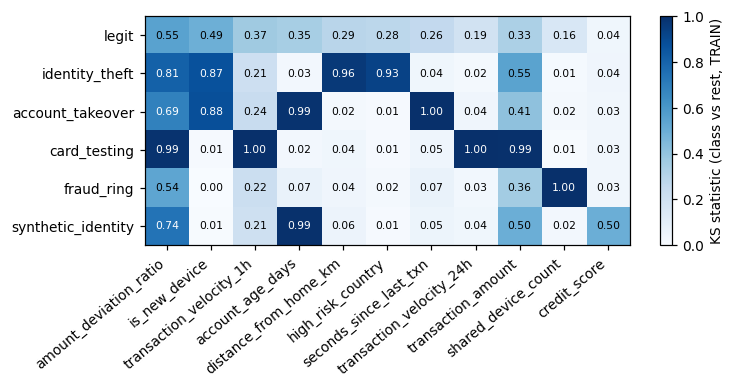

In [14]:
def ks_power(S, c, seed, n_rest=None):
    """D_cj: per-feature KS statistic, class c versus all other classes (TRAIN only)."""
    n_rest = n_rest or CFG["camo"]["n_rest"]
    rng = np.random.default_rng(seed)
    idx_c = np.where(S.ytr == c)[0]
    idx_r = np.where(S.ytr != c)[0]
    if len(idx_r) > n_rest:
        idx_r = rng.choice(idx_r, n_rest, replace=False)
    Xc, Xr = S.Xtr[idx_c], S.Xtr[idx_r]
    return np.array([stats.ks_2samp(Xc[:, j], Xr[:, j]).statistic for j in range(S.d)])


KS_DIAG = {c: ks_power(S, c, 0) for c in range(K)}          # seed 0; descriptive analyses only, never used by a method

top4 = []
for c in range(K):
    for j in np.argsort(-KS_DIAG[c])[:4]:
        if j not in top4:
            top4.append(int(j))
KSM = pd.DataFrame([KS_DIAG[c][top4] for c in range(K)], index=CLASSES, columns=[FEATURES[j] for j in top4])
save_table(KSM.round(3), "figure3_ks_class_vs_rest_train", index=True)

fig, ax = plt.subplots(figsize=(max(7, 0.55 * len(top4)), 3.6))
im = ax.imshow(KSM.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(top4))); ax.set_xticklabels(KSM.columns, rotation=40, ha="right")
ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES)
for i in range(K):
    for j in range(len(top4)):
        v = KSM.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else "black")
plt.colorbar(im, ax=ax, label="KS statistic (class vs rest, TRAIN)")
plt.tight_layout(); save_fig(fig, "figure3_ks_discriminative_power"); plt.show()

### Class distribution and prior shift
(a) Class distribution of the whole dataset (log scale); (b) share of each fraud class in the three chronological
splits. The split shares use the labels of each period for description only.

[saved tables/figure2b_class_share_per_split_pct.csv]
                     TRAIN  VALIDATION  STREAM
legit              97.5130     97.5710 96.2820
identity_theft      0.7420      0.6640  1.9630
account_takeover    0.6440      0.5990  0.6050
card_testing        0.4810      0.5180  0.4980
fraud_ring          0.3890      0.3990  0.3810
synthetic_identity  0.2310      0.2480  0.2710

Prior shift of identity_theft: 0.742% (TRAIN), 0.664% (VALIDATION), 1.963% (STREAM) -> 2.6-fold
Largest change of any other fraud class between TRAIN and STREAM: 0.039 percentage points
[saved figures/figure2_class_distribution.png and .pdf]


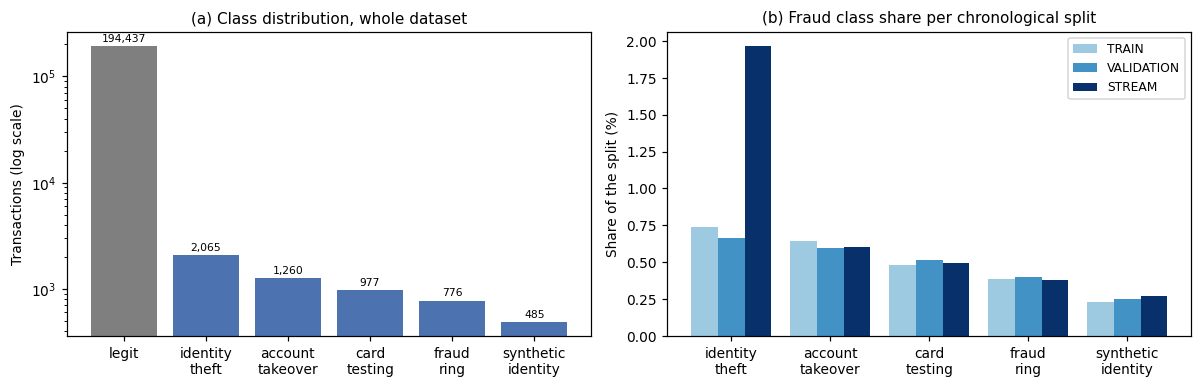

In [15]:
SPLIT_SHARE = pd.DataFrame({n: [100 * float((yy == cls2idx[c]).mean()) for c in CLASSES]
                            for n, yy in [("TRAIN", S.ytr), ("VALIDATION", S.yva), ("STREAM", S.yte)]},
                           index=CLASSES)
save_table(SPLIT_SHARE.round(3), "figure2b_class_share_per_split_pct", index=True)
_it = CLASSES.index("identity_theft") if "identity_theft" in CLASSES else None
if _it is not None:
    r_ = SPLIT_SHARE.loc["identity_theft"]
    print(f"\nPrior shift of identity_theft: {r_['TRAIN']:.3f}% (TRAIN), {r_['VALIDATION']:.3f}% (VALIDATION), "
          f"{r_['STREAM']:.3f}% (STREAM) -> {r_['STREAM'] / r_['TRAIN']:.1f}-fold")
    others = SPLIT_SHARE.drop(index=["identity_theft", CLASSES[MAJOR]])
    print(f"Largest change of any other fraud class between TRAIN and STREAM: "
          f"{(others['STREAM'] - others['TRAIN']).abs().max():.3f} percentage points")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
counts = DIST.set_index("class")["rows"].reindex(CLASSES)
bars = ax.bar(range(K), counts.values, color=["#7f7f7f"] + ["#4c72b0"] * (K - 1))
ax.set_yscale("log"); ax.set_xticks(range(K)); ax.set_xticklabels([c.replace("_", "\n") for c in CLASSES])
ax.set_ylabel("Transactions (log scale)"); ax.set_title("(a) Class distribution, whole dataset")
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v * 1.1, f"{int(v):,}", ha="center", fontsize=7)
ax = axes[1]
fr = [c for c in CLASSES if c != CLASSES[MAJOR]]
w = 0.27
for i, (n, col) in enumerate([("TRAIN", "#9ecae1"), ("VALIDATION", "#4292c6"), ("STREAM", "#08306b")]):
    ax.bar(np.arange(len(fr)) + (i - 1) * w, SPLIT_SHARE.loc[fr, n].values, w, label=n, color=col)
ax.set_xticks(range(len(fr))); ax.set_xticklabels([c.replace("_", "\n") for c in fr])
ax.set_ylabel("Share of the split (%)"); ax.set_title("(b) Fraud class share per chronological split"); ax.legend()
plt.tight_layout(); save_fig(fig, "figure2_class_distribution"); plt.show()

### Class-conditional drift
Descriptive analysis with the labels of every period (no method uses it).

* **Per-class drift.** For every class, the mean KS statistic between its TRAIN rows and its STREAM rows over its five
  most discriminative features (KS ranking above).
* **Per-feature tests.** For every class and every predictor, a two-sample KS test between TRAIN and STREAM rows of the
  class; Bonferroni correction over the 35 predictors.
* **Weekly signature flags.** Weekly share of `identity_theft` transactions that carry each TRAIN marker
  (`high_risk_country = 1`, `is_new_device = 1`, `is_foreign = 1`); dashed lines mark the split boundaries.

[saved tables/figure4b_class_conditional_drift.csv]
               cls  rows_train  rows_stream                                                                                                 top5_features  mean_ks_train_vs_stream
             legit      129410        46950          amount_deviation_ratio, is_new_device, transaction_velocity_1h, account_age_days, transaction_amount                   0.0027
    identity_theft         985          957                   distance_from_home_km, high_risk_country, is_new_device, amount_deviation_ratio, is_foreign                   0.3661
  account_takeover         854          295                 seconds_since_last_txn, account_age_days, is_new_device, amount_deviation_ratio, vpn_detected                   0.0381
      card_testing         638          243 transaction_velocity_24h, transaction_velocity_1h, transaction_amount, amount_deviation_ratio, avg_amount_30d                   0.0551
        fraud_ring         516          186          

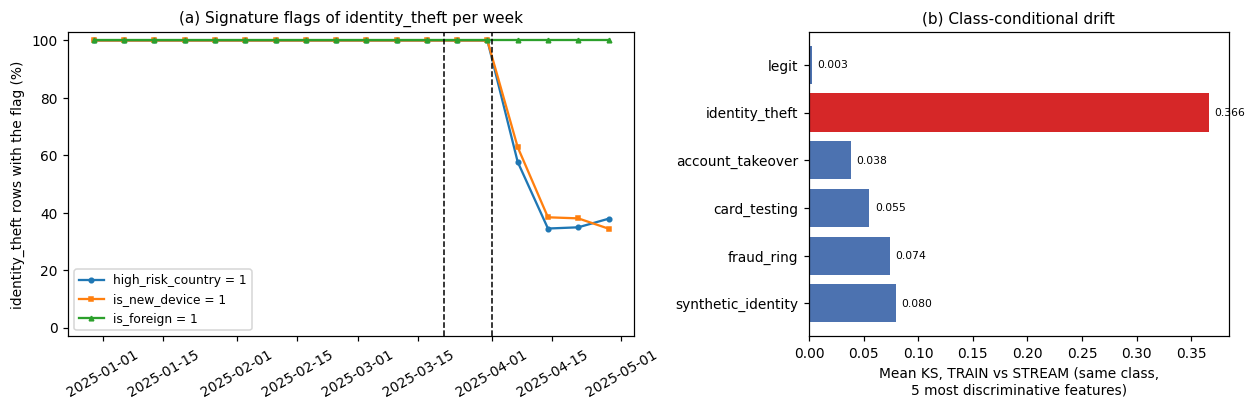

In [16]:
DRIFT_ROWS, FEAT_TESTS = [], []
for c in range(K):
    tr_c, te_c = S.Xtr[S.ytr == c], S.Xte[S.yte == c]
    if len(tr_c) < 5 or len(te_c) < 5:
        continue
    top5 = np.argsort(-KS_DIAG[c])[:5]
    DRIFT_ROWS.append(dict(cls=CLASSES[c], rows_train=len(tr_c), rows_stream=len(te_c),
                           top5_features=", ".join(FEATURES[j] for j in top5),
                           mean_ks_train_vs_stream=float(np.mean([ks_2samp(tr_c[:, j], te_c[:, j]).statistic for j in top5]))))
    for j in range(S.d):
        r_ = ks_2samp(tr_c[:, j], te_c[:, j])
        FEAT_TESTS.append(dict(cls=CLASSES[c], feature=FEATURES[j], ks=float(r_.statistic), p=float(r_.pvalue),
                               p_bonferroni=float(min(1.0, r_.pvalue * S.d))))
DRIFT = pd.DataFrame(DRIFT_ROWS)
FT = pd.DataFrame(FEAT_TESTS)
save_table(DRIFT.round(4), "figure4b_class_conditional_drift")
SIG = FT[FT["p_bonferroni"] < CFG["alpha_sig"]].sort_values(["cls", "ks"], ascending=[True, False])
FT.to_csv(out_path("drift_feature_tests_train_vs_stream.csv"), index=False)
print("\nFeatures whose TRAIN and STREAM distributions differ within a class (Bonferroni over "
      f"{S.d} predictors, alpha {CFG['alpha_sig']}):")
print(SIG.to_string(index=False) if len(SIG) else "  none")
print("\nClasses with no significant feature after Bonferroni:",
      sorted(set(CLASSES) - set(SIG["cls"])) or "none")

# --- figure: signature flags and class-conditional drift -----------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axes[0]
it_mask = (raw[CFG["target"]].astype(str) == "identity_theft").values
wk = ts.dt.to_period("W").dt.start_time
for f, lab, mk in [("high_risk_country", "high_risk_country = 1", "o"), ("is_new_device", "is_new_device = 1", "s"),
                   ("is_foreign", "is_foreign = 1", "^")]:
    if f in raw.columns:
        g = pd.DataFrame({"wk": wk[it_mask].values, "v": (raw.loc[it_mask, f].values == 1)}).groupby("wk")["v"].mean()
        ax.plot(g.index, 100 * g.values, marker=mk, ms=3, label=lab)
for key in ("train_end", "val_end"):
    ax.axvline(pd.Timestamp(CFG["split"][key]), color="k", ls="--", lw=1)
ax.set_ylabel("identity_theft rows with the flag (%)"); ax.set_ylim(-3, 103)
ax.set_title("(a) Signature flags of identity_theft per week"); ax.legend(loc="lower left")
ax.tick_params(axis="x", rotation=30)
ax = axes[1]
d_ = DRIFT.set_index("cls").reindex([c for c in CLASSES if c in set(DRIFT["cls"])])
cols = ["#d62728" if v == d_["mean_ks_train_vs_stream"].max() else "#4c72b0" for v in d_["mean_ks_train_vs_stream"]]
ax.barh(range(len(d_)), d_["mean_ks_train_vs_stream"].values, color=cols)
ax.set_yticks(range(len(d_))); ax.set_yticklabels(d_.index); ax.invert_yaxis()
for i, v in enumerate(d_["mean_ks_train_vs_stream"].values):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=7)
ax.set_xlabel("Mean KS, TRAIN vs STREAM (same class,\n5 most discriminative features)")
ax.set_title("(b) Class-conditional drift")
plt.tight_layout(); save_fig(fig, "figure4_drift"); plt.show()

### Camouflage analysis
Descriptive analysis with stream labels (no method uses it).

* **Markers of class c:** its five strongest TRAIN features (KS ranking above) and the value a class-*c* row
  normally takes (modal value of a binary marker, central 80% of a continuous one).
* **Camouflage score:** the KS-weighted share of those markers that a row has lost. A row is *camouflaged* when the
  score is at least 0.5.

The flags `IS_CAMO` defined here are also used by the mechanism analysis and by the drift simulator.

In [17]:
MARKER_M = 5          # number of TRAIN markers that define a class
CAMO_CUT = 0.5        # a row is camouflaged when it has lost at least this KS-weighted share of them
EXTRA = {}            # headline numbers collected for the final check

_b0, _b1, _b2, _b3 = (pd.Timestamp(x) for x in S.bounds)
MASK_TR = ((ts >= _b0) & (ts < _b1)).values
MASK_VA = ((ts >= _b1) & (ts < _b2)).values
MASK_TE = ((ts >= _b2) & (ts < _b3)).values
assert MASK_TR.sum() == len(S.ytr) and MASK_TE.sum() == len(S.yte), "split masks do not match S"
TRAIN_RAW = raw.loc[MASK_TR].reset_index(drop=True)
STREAM_RAW = raw.loc[MASK_TE].reset_index(drop=True)
STREAM_TS = ts[MASK_TE].reset_index(drop=True)
BATCH_OF = np.zeros(len(S.yte), int)
for _i, _b in enumerate(S.batches):
    BATCH_OF[_b] = _i + 1


def marker_profile(c, m=MARKER_M):
    """The m strongest TRAIN markers of class c, with the value range that class-c rows normally occupy."""
    rows = S.Xtr[S.ytr == c]
    prof = []
    for j in np.argsort(-KS_DIAG[c])[:m]:
        v = rows[:, j]
        uniq = np.unique(S.Xtr[:, j])
        if len(uniq) <= 2:                                   # binary marker -> the value class c almost always takes
            vals, cnt = np.unique(v, return_counts=True)
            mode = float(vals[np.argmax(cnt)])
            prof.append(dict(j=int(j), feature=FEATURES[j], ks=float(KS_DIAG[c][j]), kind="value",
                             lo=mode, hi=mode, share=float((v == mode).mean())))
        else:                                                # continuous marker -> its central 80% on TRAIN
            lo, hi = np.percentile(v, [10, 90])
            prof.append(dict(j=int(j), feature=FEATURES[j], ks=float(KS_DIAG[c][j]), kind="range",
                             lo=float(lo), hi=float(hi), share=0.8))
    return prof


MARKER_PROF = {c: marker_profile(c) for c in range(K)}


def marker_kept(X, c):
    """Boolean matrix (rows x markers): does each row still carry each marker of class c?"""
    prof = MARKER_PROF[c]
    out = np.empty((len(X), len(prof)), bool)
    for i, p in enumerate(prof):
        v = X[:, p["j"]]
        out[:, i] = (v == p["lo"]) if p["kind"] == "value" else ((v >= p["lo"]) & (v <= p["hi"]))
    return out


def camouflage_score(X, c):
    """KS-weighted share of the class-c markers that a row has LOST (0 = fully typical, 1 = nothing left)."""
    prof = MARKER_PROF[c]
    w = np.array([p["ks"] for p in prof]); w = w / w.sum()
    return (~marker_kept(X, c)) @ w


print("=" * 110)
print("Class markers and camouflage score (post-hoc diagnostics)")
print("=" * 110)
rows = []
for c in range(K):
    for p in MARKER_PROF[c]:
        rows.append(dict(cls=CLASSES[c], feature=p["feature"], ks_train=round(p["ks"], 4), kind=p["kind"],
                         typical=(f"= {p['lo']:.3g}" if p["kind"] == "value" else f"{p['lo']:.4g} .. {p['hi']:.4g}"),
                         share_in_train=round(p["share"], 3)))
MARKERS_TBL = pd.DataFrame(rows)
print("\nThe %d strongest TRAIN markers of every class (KS of class c against all other classes):" % MARKER_M)
print(MARKERS_TBL.to_string(index=False))
MARKERS_TBL.to_csv(out_path("x18_class_markers.csv"), index=False)

# ---- how many rows of each class are camouflaged, in each split --------------------------------------
camo_rows = []
for c in range(K):
    for split, Xs, ys in [("TRAIN", S.Xtr, S.ytr), ("VALIDATION", S.Xva, S.yva), ("STREAM", S.Xte, S.yte)]:
        m = ys == c
        if not m.any():
            continue
        sc = camouflage_score(Xs[m], c)
        camo_rows.append(dict(cls=CLASSES[c], split=split, rows=int(m.sum()), mean_camouflage=float(sc.mean()),
                              share_camouflaged=float((sc >= CAMO_CUT).mean()),
                              n_camouflaged=int((sc >= CAMO_CUT).sum())))
CAMO_SPLIT = pd.DataFrame(camo_rows)
print("\nCamouflage score by class and split (share_camouflaged = rows that lost >= %.0f%% of their marker weight)"
      % (100 * CAMO_CUT))
print(CAMO_SPLIT.round(4).to_string(index=False))
CAMO_SPLIT.to_csv(out_path("x18_camouflage_by_split.csv"), index=False)

# ---- per-row flags on the stream ---------------------------------------------------------------------
CAMO_SCORE = np.zeros(len(S.yte))
for c in range(K):
    m = S.yte == c
    if m.any():
        CAMO_SCORE[m] = camouflage_score(S.Xte[m], c)
IS_CAMO = CAMO_SCORE >= CAMO_CUT

# ---- when does the camouflaged subpopulation appear? -------------------------------------------------
per_batch = []
for c in range(K):
    for bi in range(1, len(S.batches) + 1):
        m = (S.yte == c) & (BATCH_OF == bi)
        if m.sum():
            per_batch.append(dict(cls=CLASSES[c], batch=bi, rows=int(m.sum()),
                                  share_camouflaged=float(IS_CAMO[m].mean())))
CAMO_BATCH = pd.DataFrame(per_batch)
print("\nShare of camouflaged rows per class and stream batch")
print(CAMO_BATCH.pivot(index="cls", columns="batch", values="share_camouflaged").round(3).to_string())
CAMO_BATCH.to_csv(out_path("x18_camouflage_per_batch.csv"), index=False)

base_rate = {}
for c in range(K):
    _sub = CAMO_SPLIT[(CAMO_SPLIT["cls"] == CLASSES[c]) & (CAMO_SPLIT["split"] == "TRAIN")]
    if len(_sub):
        base_rate[CLASSES[c]] = float(_sub["share_camouflaged"].iloc[0])
onset = []
for c in range(K):
    g = CAMO_BATCH[CAMO_BATCH["cls"] == CLASSES[c]]
    thr = max(2 * base_rate.get(CLASSES[c], 0.0), 0.15)
    hit = g[(g["share_camouflaged"] >= thr) & (g["rows"] >= 5)]
    onset.append(dict(cls=CLASSES[c], train_base_rate=round(base_rate.get(CLASSES[c], np.nan), 4),
                      trigger=round(thr, 4),
                      onset_batch=int(hit["batch"].iloc[0]) if len(hit) else -1,
                      onset_time=str(STREAM_TS[BATCH_OF == hit["batch"].iloc[0]].min()) if len(hit) else "-",
                      stream_share=round(float(g["share_camouflaged"].mean()), 4)))
ONSET = pd.DataFrame(onset)
print("\nData-driven onset of camouflage (first batch whose camouflaged share is at least twice the TRAIN rate)")
print(ONSET.to_string(index=False))
ONSET.to_csv(out_path("x18_camouflage_onset.csv"), index=False)

# ---- what the camouflaged subpopulation of each class looks like -------------------------------------
PROFILE_COLS = [f for f in ["high_risk_country", "is_new_device", "is_foreign", "vpn_detected",
                            "distance_from_home_km", "transaction_amount", "amount_deviation_ratio",
                            "account_age_days", "credit_score", "shared_device_count",
                            "seconds_since_last_txn", "transaction_velocity_1h"] if f in STREAM_RAW.columns]
prof_rows = []
for c in range(K):
    m_tr_c = (S.ytr == c)
    m_st_c = (S.yte == c)
    groups = [("TRAIN", TRAIN_RAW[m_tr_c]),
              ("STREAM, classic", STREAM_RAW[m_st_c & ~IS_CAMO]),
              ("STREAM, camouflaged", STREAM_RAW[m_st_c & IS_CAMO])]
    for gname, gdf in groups:
        if not len(gdf):
            continue
        prof_rows.append(dict(cls=CLASSES[c], group=gname, rows=len(gdf),
                              **{f: round(float(gdf[f].mean()), 4) for f in PROFILE_COLS}))
maj = CLASSES[MAJOR]
prof_rows.append(dict(cls=maj, group="TRAIN (reference)", rows=int((S.ytr == MAJOR).sum()),
                      **{f: round(float(TRAIN_RAW[S.ytr == MAJOR][f].mean()), 4) for f in PROFILE_COLS}))
SUBPOP = pd.DataFrame(prof_rows)
print("\nFeature profile of the classic and the camouflaged subpopulation of every class")
print(SUBPOP.to_string(index=False))
SUBPOP.to_csv(out_path("x18_subpopulation_profile.csv"), index=False)

# ---- residual signal: what still separates the camouflaged rows from the majority class --------------
res_rows = []
maj_tr = S.Xtr[S.ytr == MAJOR]
for c in range(K):
    m = (S.yte == c) & IS_CAMO
    if m.sum() < 5:
        continue
    Xc = S.Xte[m]
    ks = np.array([stats.ks_2samp(Xc[:, j], maj_tr[:, j]).statistic for j in range(S.d)])
    top = np.argsort(-ks)[:3]
    res_rows.append(dict(cls=CLASSES[c], rows=int(m.sum()),
                         residual_signal=", ".join(f"{FEATURES[j]} (KS {ks[j]:.2f})" for j in top),
                         max_ks=round(float(ks.max()), 4), mean_top3_ks=round(float(ks[top].mean()), 4)))
RESID = pd.DataFrame(res_rows)
print("\nResidual signal of the camouflaged rows: strongest KS against the TRAIN rows of the largest class")
print(RESID.to_string(index=False) if len(RESID) else "  (no class has enough camouflaged rows)")
if len(RESID):
    RESID.to_csv(out_path("x18_residual_signal.csv"), index=False)

EXTRA["camouflaged_target_rows"] = int((IS_CAMO & (S.yte == TARGET)).sum())
EXTRA["camouflaged_target_share"] = float(IS_CAMO[S.yte == TARGET].mean()) if (S.yte == TARGET).any() else np.nan
print(f"\n{TARGET_CLS}: {EXTRA['camouflaged_target_rows']} of {int((S.yte == TARGET).sum())} stream rows are camouflaged "
      f"({100 * EXTRA['camouflaged_target_share']:.1f}%).")

# identity_theft sub-populations compared with legit (descriptive)
_cols3 = {"high_risk_country": ("High-risk country (%)", 100), "is_new_device": ("New device (%)", 100),
          "is_foreign": ("Foreign (%)", 100), "distance_from_home_km": ("Mean distance (km)", 1),
          "transaction_amount": ("Mean amount", 1), "amount_deviation_ratio": ("Mean amount deviation ratio", 1)}
_sub = SUBPOP[(SUBPOP["cls"] == TARGET_CLS) | ((SUBPOP["cls"] == CLASSES[MAJOR]) & (SUBPOP["group"] == "TRAIN (reference)"))]
T3 = pd.DataFrame([dict(group=f"{r.cls}, {r.group}", rows=int(r.rows),
                        **{lab: round(float(getattr(r, f)) * mult, 2) for f, (lab, mult) in _cols3.items()})
                   for r in _sub.itertuples()])
print()
save_table(T3, "table3_identity_theft_subpopulations")

Class markers and camouflage score (post-hoc diagnostics)

The 5 strongest TRAIN markers of every class (KS of class c against all other classes):
               cls                  feature  ks_train  kind           typical  share_in_train
             legit   amount_deviation_ratio    0.5528 range   0.5182 .. 1.939          0.8000
             legit            is_new_device    0.4949 value               = 0          0.8800
             legit  transaction_velocity_1h    0.3681 range            0 .. 3          0.8000
             legit         account_age_days    0.3471 range       415 .. 3613          0.8000
             legit       transaction_amount    0.3317 range    67.79 .. 730.9          0.8000
    identity_theft    distance_from_home_km    0.9639 range       985 .. 4558          0.8000
    identity_theft        high_risk_country    0.9265 value               = 1          1.0000
    identity_theft            is_new_device    0.8725 value               = 1          1.0000
    ide

### Is the camouflage shift specific to one class?
(a) Share of camouflaged rows in TRAIN versus STREAM for every class: Fisher exact test, Holm over the six classes.
(b) The single-marker definition `high_risk_country = 0` versus the camouflage score: row counts, first timestamps and
overlap. Descriptive analysis with stream labels.

In [18]:
def holm(pvals):
    p = np.asarray(pvals, float); n = len(p)
    order = np.argsort(p); adj = np.empty(n); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (n - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def run_camouflage_shift_test():
    if not os.path.exists(out_path("x18_camouflage_by_split.csv")):
        print("Run the camouflage analysis first."); return None
    CB = pd.read_csv(out_path("x18_camouflage_by_split.csv"))
    rows32 = []
    for c in CLASSES:
        t = CB[CB["cls"] == c].set_index("split")
        a, b = t.loc["TRAIN"], t.loc["STREAM"]
        tab = [[int(a["n_camouflaged"]), int(a["rows"] - a["n_camouflaged"])],
               [int(b["n_camouflaged"]), int(b["rows"] - b["n_camouflaged"])]]
        odds, p = fisher_exact(tab)
        rows32.append(dict(cls=c, train_camouflaged=tab[0][0], train_rows=int(a["rows"]), train_share=a["share_camouflaged"],
                           stream_camouflaged=tab[1][0], stream_rows=int(b["rows"]), stream_share=b["share_camouflaged"],
                           share_change=b["share_camouflaged"] - a["share_camouflaged"], odds_ratio=odds, p=p))
    T32 = pd.DataFrame(rows32)
    T32["p_holm"] = holm(T32["p"].values)
    T32["drift_after_holm"] = T32["p_holm"] < CFG["alpha_sig"]
    print(T32.round(4).to_string(index=False))
    T32.to_csv(out_path("x32_camouflage_shift_test.csv"), index=False)
    return T32


T32 = run_camouflage_shift_test()


def reconcile_camouflage_definitions():
    it = CLASSES.index("identity_theft")
    m_it = np.asarray(S.yte == it)
    ts_st = pd.to_datetime(pd.Series(np.asarray(STREAM_TS)))
    hrc_tr = TRAIN_RAW.loc[np.asarray(S.ytr == it), "high_risk_country"]
    rule = m_it & (np.asarray(STREAM_RAW["high_risk_country"]) == 0)
    score = m_it & np.asarray(IS_CAMO)
    out = []
    for name, mask in [("high_risk_country = 0", rule), ("camouflage score (IS_CAMO)", score),
                       ("both", rule & score), ("rule only", rule & ~score), ("score only", score & ~rule)]:
        out.append(dict(definition=name, rows=int(mask.sum()),
                        share_of_identity_theft=round(float(mask.sum() / max(m_it.sum(), 1)), 4),
                        first_time=str(ts_st[mask].min()) if mask.any() else "-"))
    T = pd.DataFrame(out)
    print(f"\n(b) identity_theft in the stream: {int(m_it.sum())} rows; share of high_risk_country = 1 in TRAIN: "
          f"{float((hrc_tr == 1).mean()):.4f}")
    print(T.to_string(index=False))
    T.to_csv(out_path("x32_camouflage_definitions.csv"), index=False)
    return T


T32_DEF = reconcile_camouflage_definitions()

               cls  train_camouflaged  train_rows  train_share  stream_camouflaged  stream_rows  stream_share  share_change  odds_ratio      p  p_holm  drift_after_holm
             legit               5540      129410       0.0428                1999        46950        0.0426       -0.0002      1.0057 0.8417  1.0000             False
    identity_theft                  0         985       0.0000                 476          957        0.4974        0.4974      0.0000 0.0000  0.0000              True
  account_takeover                 30         854       0.0351                   8          295        0.0271       -0.0080      1.3061 0.5762  1.0000             False
      card_testing                 38         638       0.0596                  26          243        0.1070        0.0474      0.5286 0.0197  0.0889             False
        fraud_ring                  7         516       0.0136                   6          186        0.0323        0.0187      0.4126 0.1174  0.3523     

## Base model and evaluation utilities
Every model is a multi-class XGBoost (300 trees, depth 6, learning rate 0.05, row and column subsampling 0.8) with
balanced class weights. **A1** is this model trained on TRAIN without augmentation. Evaluation metrics: per-class
precision, recall, F1 and AP; macro-F1, weighted-F1, MCC, balanced accuracy, G-mean, log-loss, Brier score and ECE.

In [19]:
def fit_xgb(X, y, w, seed):
    t0 = time.time()
    m = xgb.XGBClassifier(**CFG["xgb"], random_state=seed)
    m.fit(X, y, sample_weight=w)
    return m, time.time() - t0


def class_weights(y, extra_mult=None):
    """'Balanced' class weights, optionally multiplied by per-sample weights."""
    w = compute_sample_weight("balanced", y)
    return w * extra_mult if extra_mult is not None else w


def per_class_f1(y, P):
    return f1_score(y, P.argmax(1), average=None, labels=range(K), zero_division=0)


def macro_f1(y, P):
    return float(per_class_f1(y, P).mean())


def expected_calibration_error(y_true, P, n_bins=15):
    """Top-label ECE (Guo et al., 2017)."""
    conf, pred = P.max(1), P.argmax(1)
    acc = (pred == y_true).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(ece)


def evaluate_stream(S, P, scores_valid=True):
    """Metrics on the whole April stream. Labels are used here and only here (evaluation).
    scores_valid=False for non-probabilistic outputs (hard decision rules): ranking and
    calibration metrics are then reported as NaN."""
    y = S.yte
    pred = P.argmax(1)
    pr, rc, f1c, _ = precision_recall_fscore_support(y, pred, labels=range(K), zero_division=0)
    rec_c = recall_score(y, pred, average=None, labels=range(K), zero_division=0)
    overall = dict(
        macro_f1=float(f1c.mean()),
        weighted_f1=f1_score(y, pred, average="weighted"),
        mcc=matthews_corrcoef(y, pred),
        balanced_acc=balanced_accuracy_score(y, pred),
        g_mean=float(np.exp(np.mean(np.log(np.clip(rec_c, 1e-12, None))))),
        accuracy=accuracy_score(y, pred))
    ap = np.full(K, np.nan)
    if scores_valid:
        Pn = np.clip(P, 1e-12, 1)
        Pn = Pn / Pn.sum(1, keepdims=True)
        ap = np.array([average_precision_score((y == c).astype(int), P[:, c]) for c in range(K)])
        overall.update(log_loss=log_loss(y, Pn, labels=list(range(K))),
                       brier=float(np.mean(np.sum((Pn - np.eye(K)[y]) ** 2, axis=1))),
                       ece=expected_calibration_error(y, P))
    else:
        overall.update(log_loss=np.nan, brier=np.nan, ece=np.nan)
    return overall, pr, rc, f1c, ap, pred


def per_batch_f1(S, pred):
    rows = []
    for bi, b in enumerate(S.batches):
        f1b = f1_score(S.yte[b], pred[b], average=None, labels=range(K), zero_division=0)
        for c in range(K):
            rows.append((bi + 1, CLASSES[c], f1b[c]))
    return rows

## CamoAug: class-targeted camouflage augmentation

For every augmented class *c* (every class except the largest TRAIN class), synthetic samples are created by replacing
a random subset of the features of a real class-*c* sample with the values of a donor from another class.

* **KS-guided replacement probability:** `q_cj = min(rho * D_cj^gamma / mean_j(D_cj^gamma), 0.95)`.
* **Worst-of-n donors:** five candidates with different donors (same mask); the one with the lowest A1 probability of
  class *c* is kept. The donor class is drawn uniformly among the other classes.
* **Fragility allocation:** `frag_c` is the mean A1 probability of class *c* on 2,000 camouflaged probe samples;
  the budget of class *c* is proportional to `frag_c^(-alpha)`, with a minimum of 20; the total equals the number of
  minority-class TRAIN rows.
* **Evidence filter and weight:** `e = 1 - sum(D_cj over replaced features) / sum_j D_cj`; samples with
  `e < e_min` are dropped and the others receive weight `lambda * e`.

The ablation switches are arguments of `train_camoaug`: `gamma=0` (C1), `n_donor=1` (C2), `alpha=0` (C3),
`evidence_weight=False` (C4), `e_min=0` (C5).

In [20]:
CAT_IDX = np.array([FEATURES.index(c) for c in CAT_COLS], int)     # categorical columns (ordinal codes)


def gen_class(S, plain, Dc, c, n, p, rng):
    """n camouflaged samples of class c. Returns (X_tilde, evidence e, plain-model probability of class c)."""
    g = p["gamma"]
    q = np.clip(p["rho"] * Dc ** g / (np.mean(Dc ** g) + 1e-12), 0, p["clip"])
    src = S.Xtr[rng.choice(S.rows_by_class[c], n)]
    M = rng.random((n, S.d)) < q
    pool = [k for k in range(K) if k != c]
    best, best_p = None, None
    for _ in range(int(p["n_donor"])):
        donor_cls = rng.choice(pool, n)
        don = np.empty((n, S.d))
        for k in np.unique(donor_cls):
            i = np.where(donor_cls == k)[0]
            don[i] = S.Xtr[rng.choice(S.rows_by_class[k], len(i))]
        xa = np.where(M, don, src)
        pc = plain.predict_proba(xa)[:, c]
        if best is None:
            best, best_p = xa.copy(), pc
        else:
            upd = pc < best_p
            best[upd] = xa[upd]
            best_p = np.minimum(best_p, pc)
    e = 1.0 - (M * Dc).sum(1) / (Dc.sum() + 1e-12)
    return best, e, best_p


def total_budget(S):
    return int(sum(max(20, round(CFG["camo"]["ratio"] * S.N_class[c])) for c in AUG_CLASSES))


def alloc_fragility(frag, total, alpha):
    inv = np.array([frag[c] ** (-alpha) for c in AUG_CLASSES])
    share = inv / inv.sum()
    return {c: max(20, int(round(share[i] * total))) for i, c in enumerate(AUG_CLASSES)}


def fragility_scores(S, plain, KS, seed, p):
    rng = np.random.default_rng(seed + 500)
    return {c: max(float(gen_class(S, plain, KS[c], c, p["n_probe"], p, rng)[2].mean()), 1e-6) for c in AUG_CLASSES}


def train_plain(S, seed):
    """A1: cost-sensitive XGBoost on TRAIN, no augmentation."""
    return fit_xgb(S.Xtr, S.ytr, class_weights(S.ytr), seed)[0]


def fit_augmented(S, Xs, ys, ws, seed):
    """Every augmented model (comparators and CamoAug ablations) is trained the same way: TRAIN + synthetic rows, balanced class
    weights multiplied by the synthetic-sample weight."""
    X = np.vstack([S.Xtr, Xs]); y = np.concatenate([S.ytr, ys])
    w = class_weights(y, np.concatenate([np.ones(len(S.ytr)), ws]))
    return fit_xgb(X, y, w, seed)[0]


def train_camoaug(S, seed, alpha, rho, e_min, plain, KS, gamma=None, n_donor=None, evidence_weight=True):
    """Stage 1 -> static model f0. Keyword overrides implement the CamoAug ablations."""
    p = dict(CFG["camo"], rho=rho)
    if gamma is not None: p["gamma"] = gamma
    if n_donor is not None: p["n_donor"] = n_donor
    frag = fragility_scores(S, plain, KS, seed, p)
    budget = alloc_fragility(frag, total_budget(S), alpha)
    rng = np.random.default_rng(seed + 1000)
    Xs, ys, ws = [], [], []
    for c, n in budget.items():
        X_, e_, _ = gen_class(S, plain, KS[c], c, n, p, rng)
        keep = e_ >= e_min if e_min > 0 else np.ones(len(e_), bool)
        Xs.append(X_[keep]); ys.append(np.full(int(keep.sum()), c))
        ws.append(p["lam"] * e_[keep] if evidence_weight else np.full(int(keep.sum()), p["lam"]))
    Xs, ys, ws = np.vstack(Xs), np.concatenate(ys), np.concatenate(ws)
    f0 = fit_augmented(S, Xs, ys, ws, seed)
    return dict(f0=f0, frag=frag, budget=budget, n_synthetic=len(ys), mean_weight=float(ws.mean()))

## TAPL: trust-aware pseudo-labeling

TAPL is class-symmetric: every quantity is computed in the same way for every class (verified by the leakage audit).
For every class *k*, from the static model f0 on VALIDATION:

* **Class threshold:** `T_k = max(0.5, 10th percentile of P0(k|x))` over correctly predicted class-*k* rows.
* **Veto:** `tau_k` = 95th percentile of the strongest alternative class over the same rows.
* **NP-Recovery:** `theta_k` = `(1 - eps)` quantile of `P0(k|x)` over VALIDATION rows not of class *k*. A
  stream row whose strongest alternative class `c*` (under f0) scores at least `theta_{c*}` is relabelled to `c*`
  with weight 0.3.
* **Budgeted logit bias:** `argmax_k [log P_k + b_k]`; each `b_c` is raised along the grid while the
  one-vs-rest false-positive rate of every class stays within `max(FPR_k(f0), eps_0)` and no class loses more than
  0.01 F1 on VALIDATION. The largest class fixes the gauge (`b = 0`).

**Retraining engine, shared by every pseudo-labelling method.** For each batch: predict with the anchor
blend `0.5 P_f0 + 0.5 P_model`; choose pseudo-labels with a filter; cap them per class; retrain a
candidate on TRAIN plus the pseudo-labels of the last three batches; reject the candidate if any class loses more than
0.02 F1 on VALIDATION (evaluated on the anchor-blended prediction). The last batch is only predicted.
**No function in this section receives the stream labels.**

In [21]:
def apply_bias(P, b):
    Q = P * np.exp(b)
    return Q / Q.sum(1, keepdims=True)


def fpr_per_class(y, pred):
    """One-vs-rest false-positive rate of every class: share of rows NOT of class c that are predicted c."""
    return np.array([float((pred == c)[y != c].mean()) if (y != c).any() else 0.0 for c in range(K)])


def calibrate_blb(yv, Pv, n_class, eps0=None, params=TAPL):
    """Budgeted logit bias (Neyman-Pearson principle, no simulated drift). VALIDATION labels only."""
    eps0 = params["rec_fpr"] if eps0 is None else eps0
    gauge = int(np.argmax(n_class)); free = [c for c in range(K) if c != gauge]
    ref_f1 = f1_score(yv, Pv.argmax(1), average=None, labels=range(K), zero_division=0)
    budget = np.maximum(fpr_per_class(yv, Pv.argmax(1)), eps0)
    b = np.zeros(K)
    for _ in range(params["blb_sweeps"]):
        for c in free:
            best = 0.0
            for g in params["blb_grid"]:
                bb = b.copy(); bb[c] = g
                pred = apply_bias(Pv, bb).argmax(1)
                if (fpr_per_class(yv, pred) > budget + 1e-12).any(): break
                if (f1_score(yv, pred, average=None, labels=range(K), zero_division=0) < ref_f1 - params["blb_margin"]).any(): break
                best = g
            b[c] = best
    return b


def calibrate_tapl(S, f0, params=TAPL):
    """All quantities of TAPL, from VALIDATION labels and the anchor f0 only."""
    P0v = f0.predict_proba(S.Xva); pv = P0v.argmax(1)
    tau = np.full(K, np.inf); T = np.full(K, params["conf_floor"]); theta = np.full(K, np.inf)
    for k in range(K):
        m = (pv == k) & (S.yva == k)
        if m.sum() >= 5:
            tau[k] = np.percentile(np.delete(P0v[m], k, axis=1).max(1), params["veto_pct"])
            T[k] = max(params["conf_floor"], float(np.percentile(P0v[m, k], params["conf_q"])))
        null = P0v[S.yva != k][:, k]                      # one-vs-rest null set of class k
        if len(null):
            theta[k] = float(np.quantile(null, 1 - params["rec_fpr"]))
    return dict(tau=tau, T=T, theta=theta, bias=calibrate_blb(S.yva, P0v, S.N_class, params["rec_fpr"], params))

In [22]:
@dataclass
class StreamResult:
    P: np.ndarray
    log: list
    n_retrain: int = 0
    n_skipped: int = 0


def run_stream(S, f0, seed, filter_fn, *, use_anchor=True, use_gate=True, use_cap=True, window=None):
    st = CFG["stream"]
    beta, cap_f = st["anchor_w"], st["cap_factor"]
    window = st["window"] if window is None else window
    model = f0
    rng = np.random.default_rng(seed + 55)
    P_all = np.zeros((len(S.Xte), K))
    hist, log = [], []
    n_ret = n_skip = 0
    Pv0 = f0.predict_proba(S.Xva)
    f1_ref = f1_score(S.yva, Pv0.argmax(1), average=None, labels=range(K), zero_division=0)
    for bi, b in enumerate(S.batches):
        Xb = S.Xte[b]
        P0 = f0.predict_proba(Xb)
        Pm = P0 if model is f0 else model.predict_proba(Xb)
        P = beta * P0 + (1 - beta) * Pm if use_anchor else Pm
        P_all[b] = P
        if bi == len(S.batches) - 1:
            break                                              # last batch: predict only
        pred = P.argmax(1)
        ok, y_pl, w_pl = filter_fn(Xb, P, P0, Pm, pred)
        sel = []
        for c in range(K):
            idx = np.where((y_pl == c) & ok)[0]
            cap = int(np.ceil(S.N_class[c] / S.N_class.sum() * len(b) * cap_f)) if use_cap else len(idx)
            sel.append(rng.choice(idx, cap, replace=False) if len(idx) > cap else idx)
        sel = np.concatenate(sel).astype(int)
        hist.append((Xb[sel], y_pl[sel], w_pl[sel]))
        entry = dict(batch=bi + 1, test_idx=b[sel], y_pl=y_pl[sel], n_batch=len(b), n_pass=int(ok.sum()))
        H = hist[-window:] if window else hist
        Xp = np.vstack([h[0] for h in H]); yp = np.concatenate([h[1] for h in H]); wp = np.concatenate([h[2] for h in H])
        y_full = np.concatenate([S.ytr, yp])
        cand, _ = fit_xgb(np.vstack([S.Xtr, Xp]), y_full,
                          class_weights(y_full, np.concatenate([np.ones(len(S.ytr)), wp])), seed)
        if use_gate:
            Pc = cand.predict_proba(S.Xva)
            Pv = beta * Pv0 + (1 - beta) * Pc if use_anchor else Pc
            if (f1_score(S.yva, Pv.argmax(1), average=None, labels=range(K), zero_division=0) < f1_ref - st["gate_delta"]).any():
                hist.pop(); n_skip += 1
                entry["retrained"] = False; log.append(entry)
                continue
        model = cand; n_ret += 1
        entry["retrained"] = True; log.append(entry)
    return StreamResult(P_all, log, n_ret, n_skip)


# ---------------- R6: TAPL filter (with ablation switches) ----------------
def make_tapl_filter(cal, use_veto=True, use_recovery=True, use_classthr=True, params=TAPL):
    """TAPL: per-class threshold T_k + per-class veto tau_k + one-vs-rest NP-Recovery. Class-symmetric."""
    def f(Xb, P, P0, Pm, pred):
        n = len(pred); ar = np.arange(n)
        ok = P[ar, pred] >= cal["T"][pred] if use_classthr else np.ones(n, bool)
        if use_veto:
            Pa = P.copy(); Pa[ar, pred] = -1.0
            ok &= Pa.max(1) < cal["tau"][pred]                          # no strong alternative class
        y_pl = pred.copy(); w_pl = np.full(n, CFG["stream"]["pl_weight"])
        if use_recovery:
            Q = P0.copy(); Q[ar, pred] = -1.0
            cs = Q.argmax(1)                                            # strongest alternative class (anchor f0)
            rec = Q[ar, cs] >= cal["theta"][cs]
            y_pl[rec] = cs[rec]; w_pl[rec] = params["w_recover"]; ok[rec] = True
        return ok, y_pl, w_pl
    return f


def run_tapl(S, f0, seed, cal, use_veto=True, use_recovery=True, use_classthr=True,
             use_anchor=True, use_gate=True, use_cap=True, params=TAPL):
    """Stages 2-4 of CamoAug with TAPL. Stage 5 (BLB) is applied to the returned probabilities."""
    flt = make_tapl_filter(cal, use_veto, use_recovery, use_classthr, params)
    return run_stream(S, f0, seed, flt, use_anchor=use_anchor, use_gate=use_gate, use_cap=use_cap)

## Comparators

**Augmentations A2-A5 (static).** Only the augmented classes receive synthetic rows; class *c* receives `N_c` rows (the
budget CamoAug requests); synthetic rows get weight `lambda = 0.5` (Mixup: the weight is split between the two labels
of the soft label); categorical columns are never interpolated (the value of one parent is copied).

**Retraining methods R1-R5.** All start from the same f0 and use the same anchor, window, cap and gate as TAPL; only
the selection of pseudo-labels differs. R4 (IW) uses no pseudo-labels: TRAIN is re-weighted by a cross-fitted
domain-classifier density ratio estimated from the features of the last three stream batches. R5 (CT) keeps a
pseudo-label only when f0, the retrained XGBoost and an ExtraTrees model agree and the confidence passes `T_k`.

In [23]:
def _copy_categorical(Xn, A, B, take_b):
    """Categorical columns: copy the value of parent A or B (never an interpolated code)."""
    if len(CAT_IDX):
        Xn[:, CAT_IDX] = np.where(take_b[:, None], B[:, CAT_IDX], A[:, CAT_IDX])
    return Xn


def _std(S, X):
    return np.nan_to_num((X - S.mu) / S.sd)


def smote_class(S, c, n, rng, k=None, weights=None):
    """SMOTE (Chawla et al., 2002): x + u (x_nn - x), x_nn one of the k nearest same-class neighbours.
    `weights` (ADASYN) sets how often each seed sample is used."""
    k = k or CFG["aug"]["smote_k"]
    idx = S.rows_by_class[c]
    Xc = S.Xtr[idx]
    kk = min(k, len(idx) - 1)
    nn = NearestNeighbors(n_neighbors=kk + 1).fit(_std(S, Xc)).kneighbors(_std(S, Xc), return_distance=False)[:, 1:]
    i = rng.choice(len(idx), n, p=weights) if weights is not None else rng.integers(0, len(idx), n)
    j = nn[i, rng.integers(0, kk, n)]
    u = rng.random((n, 1))
    A, B = Xc[i], Xc[j]
    return _copy_categorical(A + u * (B - A), A, B, u[:, 0] > 0.5)


def adasyn_weights(S, c, k=None, sub=50000, seed=0):
    """ADASYN (He et al., 2008): r_i = share of the k nearest TRAIN neighbours of sample i that are not of class c."""
    k = k or CFG["aug"]["adasyn_k"]
    rng = np.random.default_rng(seed + 7)
    ref = np.arange(len(S.Xtr)) if len(S.Xtr) <= sub else np.union1d(rng.choice(len(S.Xtr), sub, replace=False), S.rows_by_class[c])
    idx = S.rows_by_class[c]
    nn = NearestNeighbors(n_neighbors=k + 1).fit(_std(S, S.Xtr[ref])).kneighbors(_std(S, S.Xtr[idx]), return_distance=False)
    lab = S.ytr[ref][nn]
    self_hit = ref[nn] == idx[:, None]
    r = ((lab != c) & ~self_hit).sum(1) / k
    if r.sum() == 0:                                   # class perfectly separated: ADASYN reduces to SMOTE
        return None
    return r / r.sum()


def mixup_class(S, c, n, rng):
    """Mixup (Zhang et al., 2018): x = l x_A + (1 - l) x_B, L ~ Beta(a, a), with x_A of class c and x_B a random TRAIN row.
    The soft label l * e_c + (1 - l) * e_yB is represented exactly for a tree model by TWO weighted rows with the same x:
    (x, c, l) and (x, y_B, 1 - l); the cross-entropy of the pair equals the soft-label cross-entropy."""
    a = CFG["aug"]["mixup_alpha"]
    A = S.Xtr[rng.choice(S.rows_by_class[c], n)]
    jb = rng.integers(0, len(S.Xtr), n); B = S.Xtr[jb]
    l = rng.beta(a, a, n)[:, None]
    Xm = _copy_categorical(l * A + (1 - l) * B, A, B, l[:, 0] < 0.5)
    return np.vstack([Xm, Xm]), np.r_[np.full(n, c), S.ytr[jb]], np.r_[l[:, 0], 1 - l[:, 0]]


def scarf_class(S, c, n, rng, rho=None):
    """SCARF-style corruption (Bahri et al., 2022): every feature is replaced with probability rho (uniform) by its
    value in a random TRAIN row (the empirical marginal). No KS guidance, no donor selection, no weighting."""
    rho = CFG["final"]["rho"] if rho is None else rho
    A = S.Xtr[rng.choice(S.rows_by_class[c], n)]
    Dm = S.Xtr[rng.integers(0, len(S.Xtr), (n, S.d)), np.arange(S.d)[None, :]]   # independent row per feature
    M = rng.random((n, S.d)) < rho
    return np.where(M, Dm, A)


def train_augmentation(S, seed, kind):
    """Augmentation comparators. Returns the trained static model and the number of synthetic rows."""
    rng = np.random.default_rng(seed + 3000)
    lam = CFG["camo"]["lam"]
    Xs, ys, ws = [], [], []
    for c in AUG_CLASSES:
        n = max(20, int(round(CFG["camo"]["ratio"] * S.N_class[c])))
        if kind == "SMOTE":
            X_, w_ = smote_class(S, c, n, rng), np.full(n, lam)
        elif kind == "ADASYN":
            X_, w_ = smote_class(S, c, n, rng, k=CFG["aug"]["adasyn_k"], weights=adasyn_weights(S, c, seed=seed)), np.full(n, lam)
        elif kind == "Mixup":
            X_, y_, l_ = mixup_class(S, c, n, rng); w_ = lam * l_
        elif kind == "SCARF":
            X_, w_ = scarf_class(S, c, n, rng), np.full(n, lam)
        else:
            raise ValueError(kind)
        Xs.append(X_); ys.append(y_ if kind == "Mixup" else np.full(n, c)); ws.append(w_)
    Xs, ys, ws = np.vstack(Xs), np.concatenate(ys), np.concatenate(ws)
    return fit_augmented(S, Xs, ys, ws, seed), int(round(ws.sum() / lam))     # effective number of synthetic samples


print("CamoAug and the Table-2 augmentations defined. Augmented classes:", [CLASSES[c] for c in AUG_CLASSES])

CamoAug and the Table-2 augmentations defined. Augmented classes: ['identity_theft', 'account_takeover', 'card_testing', 'fraud_ring', 'synthetic_identity']


In [24]:
# ---------------- R1: naive self-training ----------------
def naive_filter(Xb, P, P0, Pm, pred):
    n = len(pred)
    return np.ones(n, bool), pred.copy(), np.full(n, CFG["stream"]["pl_weight"])


# ---------------- R2: FixMatch-style fixed threshold ----------------
def make_fixmatch_filter(tau):
    def f(Xb, P, P0, Pm, pred):
        n = len(pred)
        return P.max(1) >= tau, pred.copy(), np.full(n, CFG["stream"]["pl_weight"])
    return f


# ---------------- R3: FreeMatch-style self-adaptive thresholds ----------------
def make_freematch_filter(ema=None):
    """Self-adaptive thresholding of FreeMatch (Wang et al., ICLR 2023), applied per stream batch.
    Global threshold  tau_t   = EMA of the mean max-probability of the unlabeled rows;
    class-wise state  p_t(c)  = EMA of the mean probability of class c;
    class threshold   tau_t(c) = p_t(c) / max_c p_t(c) * tau_t   (MaxNorm).
    The EMA is defined per sample (momentum `ema`), so a batch of n rows moves the state by a factor ema^n.
    Initial state 1/K, as in the paper. A row is kept when its confidence >= tau_t(predicted class)."""
    ema = CFG["freematch_ema"] if ema is None else ema
    state = dict(tau=1.0 / K, p=np.full(K, 1.0 / K), history=[])

    def f(Xb, P, P0, Pm, pred):
        n = len(pred)
        m = ema ** n
        state["tau"] = m * state["tau"] + (1 - m) * float(P.max(1).mean())
        state["p"] = m * state["p"] + (1 - m) * P.mean(0)
        thr = state["p"] / state["p"].max() * state["tau"]
        state["history"].append(thr.copy())
        return P.max(1) >= thr[pred], pred.copy(), np.full(n, CFG["stream"]["pl_weight"])
    f.state = state
    return f

In [25]:
def iw_weights(S, sub, T, seed):
    Xs = S.Xtr[sub]
    Xd = np.vstack([Xs, T])
    yd = np.r_[np.zeros(len(Xs)), np.ones(len(T))]
    wd = np.r_[np.full(len(Xs), 0.5 / len(Xs)), np.full(len(T), 0.5 / len(T))] * len(Xd)   # equal domain priors
    rest = np.setdiff1d(np.arange(len(S.Xtr)), sub)
    p = np.zeros(len(S.Xtr)); cnt = np.zeros(len(S.Xtr))
    for tr, te in KFold(2, shuffle=True, random_state=seed).split(Xd):
        m = xgb.XGBClassifier(n_estimators=60, max_depth=4, learning_rate=0.1, tree_method="hist",
                              n_jobs=-1, random_state=seed).fit(Xd[tr], yd[tr], sample_weight=wd[tr])
        te_s = te[te < len(Xs)]
        p[sub[te_s]] += m.predict_proba(Xd[te_s])[:, 1]; cnt[sub[te_s]] += 1
        p[rest] += m.predict_proba(S.Xtr[rest])[:, 1]; cnt[rest] += 1
    p = np.clip(p / np.maximum(cnt, 1), 1e-3, 1 - 1e-3)
    w = np.clip((p / (1 - p)) ** EXT["iw_gamma"], *EXT["iw_clip"])
    return w / w.mean()


def run_iw(S, f0, seed):
    st = CFG["stream"]; beta = st["anchor_w"]
    model = f0
    rng = np.random.default_rng(seed + 77)
    sub = rng.choice(len(S.Xtr), min(EXT["iw_sub"], len(S.Xtr)), replace=False)
    Pv0 = f0.predict_proba(S.Xva)
    f1_ref = f1_score(S.yva, Pv0.argmax(1), average=None, labels=range(K), zero_division=0)
    P_all = np.zeros((len(S.Xte), K)); n_ret = n_skip = 0
    for bi, b in enumerate(S.batches):
        Xb = S.Xte[b]
        P0 = f0.predict_proba(Xb)
        Pm = P0 if model is f0 else model.predict_proba(Xb)
        P_all[b] = beta * P0 + (1 - beta) * Pm
        if bi == len(S.batches) - 1:
            break
        tb = np.concatenate(S.batches[max(0, bi - EXT["iw_target_batches"] + 1): bi + 1])
        w = iw_weights(S, sub, S.Xte[tb], seed)                  # stream FEATURES only
        cand, _ = fit_xgb(S.Xtr, S.ytr, class_weights(S.ytr, w), seed)
        Pv = beta * Pv0 + (1 - beta) * cand.predict_proba(S.Xva)
        if (f1_score(S.yva, Pv.argmax(1), average=None, labels=range(K), zero_division=0) < f1_ref - st["gate_delta"]).any():
            n_skip += 1
            continue
        model = cand; n_ret += 1
    return StreamResult(P_all, [], n_ret, n_skip)

In [26]:
def run_ct(S, f0, seed, cal):
    st = CFG["stream"]; cap_f = st["cap_factor"]
    rng = np.random.default_rng(seed + 99)
    big = np.where(S.ytr == int(np.argmax(S.N_class)))[0]
    rest = np.where(S.ytr != int(np.argmax(S.N_class)))[0]
    sub = np.concatenate([rest, rng.choice(big, min(EXT["ct_major_sub"], len(big)), replace=False)])   # speed only

    def fit_et(Xp=None, yp=None, wp=None):
        X, y, m = S.Xtr[sub], S.ytr[sub], np.ones(len(sub))
        if Xp is not None and len(yp):
            X, y, m = np.vstack([X, Xp]), np.r_[y, yp], np.r_[m, wp]
        e = ExtraTreesClassifier(n_estimators=EXT["ct_trees"], min_samples_leaf=2, n_jobs=-1, random_state=seed)
        return e.fit(X, y, sample_weight=class_weights(y, m))

    ens = lambda Xx, xm, em: (f0.predict_proba(Xx) + xm.predict_proba(Xx) + em.predict_proba(Xx)) / 3
    et, xg = fit_et(), f0
    f1_ref = f1_score(S.yva, ens(S.Xva, xg, et).argmax(1), average=None, labels=range(K), zero_division=0)
    hist, P_all, log = [], np.zeros((len(S.Xte), K)), []
    n_ret = n_skip = 0
    for bi, b in enumerate(S.batches):
        Xb = S.Xte[b]
        P0 = f0.predict_proba(Xb)
        Px = P0 if xg is f0 else xg.predict_proba(Xb)
        Pe = et.predict_proba(Xb)
        P = (P0 + Px + Pe) / 3
        P_all[b] = P
        if bi == len(S.batches) - 1:
            break
        pred = P.argmax(1); n = len(pred); ar = np.arange(n)
        ok = ((P0.argmax(1) == pred) & (Px.argmax(1) == pred) & (Pe.argmax(1) == pred)
              & (P[ar, pred] >= cal["T"][pred]))
        sel = []
        for c in range(K):
            idx = np.where((pred == c) & ok)[0]
            cap = int(np.ceil(S.N_class[c] / S.N_class.sum() * len(b) * cap_f))
            sel.append(rng.choice(idx, cap, replace=False) if len(idx) > cap else idx)
        sel = np.concatenate(sel).astype(int)
        hist.append((Xb[sel], pred[sel], np.full(len(sel), st["pl_weight"])))
        entry = dict(batch=bi + 1, test_idx=b[sel], y_pl=pred[sel], n_batch=n, n_pass=int(ok.sum()))
        H = hist[-st["window"]:]
        Xp = np.vstack([h[0] for h in H]); yp = np.concatenate([h[1] for h in H]); wp = np.concatenate([h[2] for h in H])
        y_full = np.r_[S.ytr, yp]
        cx, _ = fit_xgb(np.vstack([S.Xtr, Xp]), y_full, class_weights(y_full, np.r_[np.ones(len(S.ytr)), wp]), seed)
        ce = fit_et(Xp, yp, wp)
        if (f1_score(S.yva, ens(S.Xva, cx, ce).argmax(1), average=None, labels=range(K), zero_division=0) < f1_ref - st["gate_delta"]).any():
            hist.pop(); n_skip += 1
            entry["retrained"] = False; log.append(entry)
            continue
        xg, et = cx, ce
        n_ret += 1
        entry["retrained"] = True; log.append(entry)
    return StreamResult(P_all, log, n_ret, n_skip)


print("All methods defined.")

All methods defined.


In [27]:
# Methods compared
T5 = pd.DataFrame([
    ("R0", "CamoAug (static f0)", "Never retrained; reference of the retraining family"),
    ("R1", "Naive self-training", "All predictions used as pseudo-labels"),
    ("R2", "FixMatch-style", f"Fixed confidence threshold {CFG['fixmatch_tau']}"),
    ("R3", "FreeMatch-style", f"Self-adaptive global and class-wise thresholds (EMA {CFG['freematch_ema']})"),
    ("R4", "IW", "No pseudo-labels; TRAIN re-weighted by a covariate-shift density ratio"),
    ("R5", "CT", "XGBoost + ExtraTrees + f0 must agree and pass T_k"),
    ("R6", "CamoAug with TAPL", "TAPL filter + NP-Recovery, then BLB"),
    ("A1", "No augmentation", "Balanced class weights only"),
    ("A2", "SMOTE", f"Interpolation with one of {CFG['aug']['smote_k']} same-class neighbours"),
    ("A3", "Mixup", f"Convex combination, l ~ Beta({CFG['aug']['mixup_alpha']}, {CFG['aug']['mixup_alpha']}), soft label"),
    ("A4", "SCARF-style swap", f"Each feature replaced with probability {CFG['final']['rho']} by its value in a random TRAIN row"),
    ("A5", "ADASYN", "SMOTE with more seeds where neighbours belong to other classes"),
    ("A6", "CamoAug", "KS-guided camouflage augmentation (this work)"),
    ("T1-T8", "TAPL ablations", "Without veto, NP-Recovery, BLB, anchor, gate or cap; BLB only; without T_k"),
    ("C1-C5", "CamoAug ablations", "Uniform q (gamma = 0), single donor, equal allocation, constant weight, e_min = 0"),
], columns=["id", "method", "mechanism"])
save_table(T5, "table5_methods")

[saved tables/table5_methods.csv]
   id              method                                                                         mechanism
   R0 CamoAug (static f0)                               Never retrained; reference of the retraining family
   R1 Naive self-training                                             All predictions used as pseudo-labels
   R2      FixMatch-style                                                   Fixed confidence threshold 0.95
   R3     FreeMatch-style                        Self-adaptive global and class-wise thresholds (EMA 0.999)
   R4                  IW            No pseudo-labels; TRAIN re-weighted by a covariate-shift density ratio
   R5                  CT                                 XGBoost + ExtraTrees + f0 must agree and pass T_k
   R6   CamoAug with TAPL                                               TAPL filter + NP-Recovery, then BLB
   A1     No augmentation                                                       Balanced class weights

## Main experiment

For every seed: train A1 and CamoAug f0, the augmentations A2-A5 and the CamoAug ablations C1-C5 (static), calibrate
TAPL on VALIDATION, then run every retraining method R1-R6 and every TAPL ablation T1-T8 on the April stream.
Nothing in `run_seed` passes the stream labels to a method; they are used only inside `record` (evaluation).

Rows that are identical by definition are recorded under each table's name (A6 = R0 = C0 = f0, T0 = R6).
Runtime: about 7 minutes per seed on a GPU; results are checkpointed after every seed.

In [28]:
M = dict(
    R0="R0 CamoAug (static f0)", R1="R1 Naive self-training", R2="R2 FixMatch-style",
    R3="R3 FreeMatch-style", R4="R4 IW", R5="R5 CT", R6="R6 CamoAug with TAPL",
    A1="A1 No augmentation", A2="A2 SMOTE", A3="A3 Mixup", A4="A4 SCARF-style swap", A5="A5 ADASYN", A6="A6 CamoAug",
    T0="T0 Full method (R6)", T1="T1 without veto", T2="T2 without NP-Recovery", T3="T3 without BLB",
    T4="T4 without anchor blend", T5="T5 without gate", T6="T6 without cap",
    T7="T7 BLB only (no retraining)", T8="T8 without class thresholds T_k",
    C0="C0 CamoAug (full)", C1="C1 uniform q (no KS guidance)", C2="C2 single donor (no worst-of-n)",
    C3="C3 equal allocation (no fragility)", C4="C4 constant weight", C5="C5 no evidence filter",
)
# Families of hypotheses (Holm correction inside each family)
TABLES = {
    "Retraining": dict(title="Retraining methods", kind="comparison", ref=M["R0"], proposed=M["R6"],
                    methods=[M[k] for k in ["R0", "R1", "R2", "R3", "R4", "R5", "R6"]]),
    "Augmentation": dict(title="Augmentation methods (static)", kind="comparison", ref=M["A1"], proposed=M["A6"],
                     methods=[M[k] for k in ["A1", "A2", "A3", "A4", "A5", "A6"]]),
    "CamoAug ablation": dict(title="CamoAug ablation (reference = full CamoAug)", kind="ablation", ref=M["C0"],
                     proposed=M["C0"], methods=[M[f"C{i}"] for i in range(6)]),
    "TAPL ablation": dict(title="TAPL ablation (reference = full method)", kind="ablation", ref=M["T0"],
                     proposed=M["T0"], methods=[M[f"T{i}"] for i in range(9)]),
}
TARGET_NAME = TARGET_CLS
RESULTS, PERBATCH, PLQ, CALIB = [], [], [], []
PRED_STORE = {}             # (method, seed) -> predicted classes (mechanism analysis, leakage audit)


def record(name, seed, P, res=None, secs=np.nan, extra=None):
    """Evaluate predictions P on the stream (stream labels are used HERE only) and store everything."""
    overall, pr, rc, f1c, ap, pred = evaluate_stream(S, P, True)
    row = dict(method=name, seed=seed, **overall, n_retrain=res.n_retrain if res else 0,
               n_skipped=res.n_skipped if res else 0, seconds=secs, **(extra or {}))
    for c in range(K):
        row[f"f1_{CLASSES[c]}"] = f1c[c]; row[f"prec_{CLASSES[c]}"] = pr[c]
        row[f"rec_{CLASSES[c]}"] = rc[c]; row[f"ap_{CLASSES[c]}"] = ap[c]
    RESULTS.append(row)
    for bi, cname, v in per_batch_f1(S, pred):
        PERBATCH.append(dict(method=name, seed=seed, batch=bi, cls=cname, f1=v))
    PRED_STORE[(name, seed)] = pred.astype(np.int8)
    if res is not None and res.log:                           # post-hoc pseudo-label quality
        for e in res.log:
            y_true = S.yte[e["test_idx"]]
            ok = y_true == e["y_pl"]
            for c in [None] + list(range(K)):
                m = np.ones(len(ok), bool) if c is None else e["y_pl"] == c
                PLQ.append(dict(method=name, seed=seed, batch=e["batch"], cls="all" if c is None else CLASSES[c],
                                n_selected=int(m.sum()), n_correct=int(ok[m].sum()),
                                retrained=e.get("retrained", True)))


def timed(fn, *a, **k):
    t0 = time.time(); out = fn(*a, **k); return out, time.time() - t0


def build_static(S, seed):
    """A1, KS statistics and CamoAug f0 for one seed (TRAIN only)."""
    fin = CFG["final"]
    plain = train_plain(S, seed)
    KS = {c: ks_power(S, c, seed) for c in AUG_CLASSES}
    fb = train_camoaug(S, seed, fin["alpha"], fin["rho"], fin["e_min"], plain, KS)
    return plain, KS, fb


def run_seed(seed):
    t_seed = time.time()
    fin = CFG["final"]
    (plain, KS, fb), secs = timed(build_static, S, seed)
    f0 = fb["f0"]
    P_plain, P_f0 = plain.predict_proba(S.Xte), f0.predict_proba(S.Xte)
    syn = dict(n_synthetic=fb["n_synthetic"])
    record(M["A1"], seed, P_plain, extra=dict(n_synthetic=0))
    for key in ("R0", "A6", "C0"):
        record(M[key], seed, P_f0, secs=secs, extra=syn)

    # ---- augmentations A2-A5 (static) ----
    for key, kind in [("A2", "SMOTE"), ("A3", "Mixup"), ("A4", "SCARF"), ("A5", "ADASYN")]:
        (mdl, n_syn), secs = timed(train_augmentation, S, seed, kind)
        record(M[key], seed, mdl.predict_proba(S.Xte), secs=secs, extra=dict(n_synthetic=n_syn))

    # ---- CamoAug ablations C1-C5 (static) ----
    abl = {"C1": dict(gamma=0.0), "C2": dict(n_donor=1), "C3": dict(alpha=0.0),
           "C4": dict(evidence_weight=False), "C5": dict(e_min=0.0)}
    for key, kw in abl.items():
        a = dict(alpha=fin["alpha"], rho=fin["rho"], e_min=fin["e_min"]); a.update({k: v for k, v in kw.items() if k in a})
        extra_kw = {k: v for k, v in kw.items() if k not in a}
        fa, secs = timed(train_camoaug, S, seed, a["alpha"], a["rho"], a["e_min"], plain, KS, **extra_kw)
        record(M[key], seed, fa["f0"].predict_proba(S.Xte), secs=secs, extra=dict(n_synthetic=fa["n_synthetic"]))

    # ---- calibration of TAPL: VALIDATION labels only ----
    cal = calibrate_tapl(S, f0)
    CALIB.append(dict(seed=seed, n_synthetic=fb["n_synthetic"],
                      **{f"budget_{CLASSES[c]}": n for c, n in fb["budget"].items()},
                      **{f"T_{CLASSES[c]}": cal["T"][c] for c in range(K)},
                      **{f"tau_{CLASSES[c]}": cal["tau"][c] for c in range(K)},
                      **{f"theta_{CLASSES[c]}": cal["theta"][c] for c in range(K)},
                      **{f"b_{CLASSES[c]}": cal["bias"][c] for c in range(K)}))

    # ---- retraining methods R1-R6 (same f0, same protocol) ----
    for key, flt in [("R1", naive_filter), ("R2", make_fixmatch_filter(CFG["fixmatch_tau"])),
                     ("R3", make_freematch_filter())]:
        res, secs = timed(run_stream, S, f0, seed, flt)
        record(M[key], seed, res.P, res=res, secs=secs)
        if key == "R3":
            CALIB[-1].update({f"freematch_final_thr_{CLASSES[c]}": flt.state["history"][-1][c] for c in range(K)})
    res, secs = timed(run_iw, S, f0, seed);      record(M["R4"], seed, res.P, res=res, secs=secs)
    res, secs = timed(run_ct, S, f0, seed, cal); record(M["R5"], seed, res.P, res=res, secs=secs)
    res_t, secs_t = timed(run_tapl, S, f0, seed, cal)
    P_tapl = apply_bias(res_t.P, cal["bias"])
    record(M["R6"], seed, P_tapl, res=res_t, secs=secs_t)

    # ---- TAPL ablations T1-T8 ----
    record(M["T0"], seed, P_tapl, res=res_t, secs=secs_t)
    record(M["T3"], seed, res_t.P, res=res_t, secs=secs_t)                 # same run, BLB not applied
    record(M["T7"], seed, apply_bias(P_f0, cal["bias"]))                   # BLB on the static f0
    for key, kw in [("T1", dict(use_veto=False)), ("T2", dict(use_recovery=False)), ("T4", dict(use_anchor=False)),
                    ("T5", dict(use_gate=False)), ("T6", dict(use_cap=False)), ("T8", dict(use_classthr=False))]:
        r, secs = timed(run_tapl, S, f0, seed, cal, **kw)
        record(M[key], seed, apply_bias(r.P, cal["bias"]), res=r, secs=secs)
    print(f"  seed {seed} finished in {time.time() - t_seed:.0f}s")


CKPT = out_path("main_checkpoint.pkl")
CKPT_KEY = dict(quick=QUICK_TEST, trees=CFG["xgb"]["n_estimators"], batch=CFG["batch_size"], methods=sorted(M))
done_seeds = set()
if os.path.exists(CKPT):
    with open(CKPT, "rb") as fh:
        saved = pickle.load(fh)
    if saved.get("key") == CKPT_KEY:
        RESULTS, PERBATCH, PLQ, CALIB, PRED_STORE = (saved[k] for k in ("RESULTS", "PERBATCH", "PLQ", "CALIB", "PRED_STORE"))
        done_seeds = {r["seed"] for r in RESULTS}
        print("Resuming; seeds already done:", sorted(done_seeds))
    else:
        print("Checkpoint belongs to another configuration; starting from scratch.")

t_all = time.time()
for sd in SEEDS["main"]:
    if sd in done_seeds:
        continue
    print(f"Seed {sd} ...")
    run_seed(sd)
    with open(CKPT, "wb") as fh:
        pickle.dump(dict(key=CKPT_KEY, RESULTS=RESULTS, PERBATCH=PERBATCH, PLQ=PLQ, CALIB=CALIB, PRED_STORE=PRED_STORE), fh)
print(f"Main experiment done in {(time.time() - t_all) / 60:.1f} min")

R = pd.DataFrame(RESULTS)
PB = pd.DataFrame(PERBATCH)
PQ = pd.DataFrame(PLQ)
CAL = pd.DataFrame(CALIB)
R.to_csv(out_path("results_per_seed.csv"), index=False)
PB.to_csv(out_path("results_per_batch.csv"), index=False)
CAL.to_csv(out_path("calibration_per_seed.csv"), index=False)
METHODS = list(dict.fromkeys(R["method"]))
print(f"{len(METHODS)} method rows x {R['seed'].nunique()} seeds = {len(R)} runs")

Seed 42 ...
  seed 42 finished in 436s
Seed 43 ...
  seed 43 finished in 436s
Seed 44 ...
  seed 44 finished in 437s
Seed 45 ...
  seed 45 finished in 438s
Seed 46 ...
  seed 46 finished in 438s
Seed 47 ...
  seed 47 finished in 434s
Seed 48 ...
  seed 50 finished in 441s
Seed 51 ...
  seed 51 finished in 439s
Main experiment done in 73.1 min
28 method rows x 10 seeds = 280 runs


### What was calibrated (TRAIN and VALIDATION only)
CamoAug budgets per class, TAPL thresholds `T_k`, vetoes `tau_k`, NP-Recovery thresholds `theta_k`, BLB biases `b_k`
and the final FreeMatch-style thresholds, per seed. Nothing here depends on April labels.

In [29]:
print(CAL.set_index("seed").T.round(4).to_string())
_b = [f"budget_{c}" for c in CLASSES if f"budget_{c}" in CAL]
print("\nMean CamoAug budget per class:", CAL[_b].mean().round(1).to_dict())
print("Mean synthetic rows kept after the evidence filter:", round(CAL["n_synthetic"].mean(), 1))
print(f"Mean NP threshold theta of {TARGET_CLS} (f0): {CAL[f'theta_{TARGET_CLS}'].mean():.4f}")
print(f"Seeds whose calibrated BLB bias of {TARGET_CLS} is 0: {int((CAL[f'b_{TARGET_CLS}'] == 0).sum())}")
print("Seeds whose BLB bias reached the upper end of the grid (per class):",
      {c: int((CAL[f"b_{c}"] >= max(TAPL["blb_grid"])).sum()) for c in CLASSES})

seed                                          42        43        44        45        46        47        48        49        50        51
n_synthetic                             109.0000  107.0000   85.0000  121.0000  110.0000  117.0000  113.0000  124.0000   93.0000  108.0000
budget_identity_theft                  3120.0000 3260.0000 3222.0000 3166.0000 3136.0000 3078.0000 3269.0000 2452.0000 3188.0000 3173.0000
budget_account_takeover                 134.0000   36.0000   65.0000   68.0000  116.0000  172.0000   24.0000  689.0000   69.0000   99.0000
budget_card_testing                      20.0000   20.0000   20.0000   20.0000   20.0000   20.0000   20.0000   39.0000   20.0000   20.0000
budget_fraud_ring                        20.0000   20.0000   20.0000   20.0000   20.0000   20.0000   20.0000   20.0000   20.0000   20.0000
budget_synthetic_identity                35.0000   20.0000   20.0000   54.0000   35.0000   29.0000   20.0000  111.0000   35.0000   20.0000
T_legit                    

### Statistical tests
All tests are paired by seed. Each group of methods is its own family of hypotheses (Holm correction inside the family).

| Test | Question | Used in |
|---|---|---|
| Friedman + Nemenyi critical difference | Do the methods differ at all? | retraining, augmentation |
| One-sided paired Wilcoxon, Holm | Is method X better than the reference / is the proposed method better than X? | retraining, augmentation |
| Two-sided paired Wilcoxon, Holm | Does removing the component change the result? | ablations |
| Seed bootstrap 95% CI of the mean difference (10,000 resamples); wins / ties / losses | Size and stability of the effect | all |

With 10 seeds the smallest one-sided Wilcoxon p is 2^-10 = 0.00098.

In [30]:
CL_F1 = [f"f1_{c}" for c in CLASSES]
OVERALL = ["macro_f1", "weighted_f1", "mcc", "balanced_acc", "g_mean", "accuracy", "log_loss", "brier", "ece"]
TGT = f"f1_{TARGET_CLS}"


def wide(metric, methods=None):
    W = R.pivot(index="seed", columns="method", values=metric)
    return W[methods] if methods is not None else W


def paired_wilcoxon(a, b, alt="greater", shift=0.0):
    d = np.asarray(a, float) - np.asarray(b, float) + shift
    if np.allclose(d, 0):
        return 1.0
    try:
        return float(wilcoxon(d, alternative=alt, zero_method="wilcox").pvalue)
    except ValueError:
        return 1.0


def rank_biserial(d):
    d = np.asarray(d, float); d = d[d != 0]
    if len(d) == 0: return 0.0
    r = stats.rankdata(np.abs(d))
    return float((r[d > 0].sum() - r[d < 0].sum()) / r.sum())


def cliffs_delta(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return float((np.sum(a[:, None] > b[None, :]) - np.sum(a[:, None] < b[None, :])) / (len(a) * len(b)))


def boot_ci(d, n_boot=10000, seed=0):
    d = np.asarray(d, float)
    if len(d) < 2: return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    m = d[rng.integers(0, len(d), (n_boot, len(d)))].mean(1)
    return tuple(np.percentile(m, [2.5, 97.5]))


def holm(pvals):
    p = np.asarray(pvals, float); n = len(p)
    order = np.argsort(p); adj = np.empty(n); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (n - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def ci95(x):
    x = np.asarray(x, float)
    if len(x) < 2: return (np.nan, np.nan)
    h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return (x.mean() - h, x.mean() + h)


def pair_rows(pairs, metric, alt):
    """pairs: list of (label, a_method, b_method). Tests a - b."""
    Wm = wide(metric)
    rows = []
    for lab, ma, mb in pairs:
        a, b = Wm[ma].values, Wm[mb].values; d = a - b
        lo, hi = boot_ci(d)
        rows.append(dict(comparison=lab, mean_diff=d.mean(), ci95_lo=lo, ci95_hi=hi, sd_diff=d.std(ddof=1) if len(d) > 1 else np.nan,
                         p=paired_wilcoxon(a, b, alt=alt), rank_biserial=rank_biserial(d), cliffs_delta=cliffs_delta(a, b),
                         wins=int((d > 1e-12).sum()), ties=int((np.abs(d) <= 1e-12).sum()), losses=int((d < -1e-12).sum())))
    T = pd.DataFrame(rows)
    T["p_holm"] = holm(T["p"].values)
    T["significant"] = T["p_holm"] < CFG["alpha_sig"]
    return T


def friedman_nemenyi(methods, metric):
    W = wide(metric, methods).dropna(axis=1)
    if W.shape[0] < 3 or W.shape[1] < 3:
        print(f"  Friedman on {metric}: not enough seeds/methods"); return None
    st, p = friedmanchisquare(*[W[c].values for c in W.columns])
    ranks = W.rank(axis=1, ascending=False).mean()
    k, n = W.shape[1], W.shape[0]
    q = stats.studentized_range.ppf(1 - CFG["alpha_sig"], k, np.inf) / np.sqrt(2)
    cd = q * np.sqrt(k * (k + 1) / (6 * n))
    print(f"  Friedman on {metric}: chi2 = {st:.2f}, p = {p:.3g} (k = {k}, n = {n}); Nemenyi CD (alpha 0.05) = {cd:.2f}")
    rk = ranks.sort_values()
    print("  mean rank (1 = best): " + " | ".join(f"{m} = {v:.2f}" for m, v in rk.items()))
    diff_pairs = [(a, b) for i, a in enumerate(rk.index) for b in rk.index[i + 1:] if rk[b] - rk[a] > cd]
    print("  pairs whose rank difference exceeds CD: " + ("; ".join(f"{a} > {b}" for a, b in diff_pairs) if diff_pairs else "none"))
    return dict(chi2=st, p=p, cd=cd, ranks=rk)


def describe_table(tag):
    spec = TABLES[tag]; ms = [m for m in spec["methods"] if m in METHODS]
    print("=" * 110); print(f"{tag}: {spec['title']}"); print("=" * 110)
    rows = []
    for m in ms:
        d = R[R["method"] == m]; row = {"method": m}
        for c in OVERALL + [TGT]:
            row[c] = d[c].mean()
        row["macro_f1_sd"] = d["macro_f1"].std(ddof=1); lo, hi = ci95(d["macro_f1"]); row["macro_f1_ci95"] = f"[{lo:.4f}, {hi:.4f}]"
        row[TGT + "_sd"] = d[TGT].std(ddof=1)
        if "n_synthetic" in d and d["n_synthetic"].notna().any(): row["n_synthetic"] = d["n_synthetic"].mean()
        row["n_retrain"] = d["n_retrain"].mean(); row["n_skipped"] = d["n_skipped"].mean(); row["sec"] = d["seconds"].mean()
        rows.append(row)
    T = pd.DataFrame(rows)
    print("\nOverall metrics (mean over seeds)")
    print(T.round(4).to_string(index=False))
    T.to_csv(out_path(f"{tag.replace(' ', '_').lower()}_overall.csv"), index=False)

    Tc = R[R["method"].isin(ms)].groupby("method", sort=False)[CL_F1].agg(["mean", "std"])
    Tm = R[R["method"].isin(ms)].groupby("method", sort=False)[CL_F1].mean().reindex(ms)
    print("\nPer-class F1 (mean over seeds)")
    print(Tm.round(4).to_string())
    print("\nPer-class F1 (sd over seeds)")
    print(Tc.xs("std", axis=1, level=1).reindex(ms).round(4).to_string())
    Tm.to_csv(out_path(f"{tag.replace(' ', '_').lower()}_per_class_f1.csv"))

    print(f"\nTarget class '{TARGET_CLS}': precision / recall / F1 / AP (mean +- sd)")
    rr = []
    for m in ms:
        d = R[R["method"] == m]
        rr.append({"method": m, **{k: f"{d[f'{k}_{TARGET_CLS}'].mean():.4f} +- {d[f'{k}_{TARGET_CLS}'].std(ddof=1):.4f}"
                                   for k in ("prec", "rec", "f1", "ap")}})
    print(pd.DataFrame(rr).to_string(index=False))

    print("\nPer-seed macro-F1"); print(wide("macro_f1", ms).round(4).to_string())
    print(f"\nPer-seed {TGT}"); print(wide(TGT, ms).round(4).to_string())

    print("\nOmnibus tests")
    for metric in ["macro_f1", TGT]:
        friedman_nemenyi(ms, metric)
    return ms


TEST_OUT = {}
for tag, spec in TABLES.items():
    ms = describe_table(tag)
    ref, prop = spec["ref"], spec["proposed"]
    others = [m for m in ms if m != ref]
    if spec["kind"] == "comparison":
        pairs_ref = [(f"{m} vs {ref}", m, ref) for m in others]
        pairs_prop = [(f"{prop} vs {m}", prop, m) for m in ms if m != prop]
        for metric in ["macro_f1", TGT]:
            T = pair_rows(pairs_ref, metric, "greater")
            print(f"\n[{tag}] One-sided Wilcoxon, H1: method > reference '{ref}', metric {metric}, Holm over {len(T)} comparisons")
            print(T.round(4).to_string(index=False)); T.to_csv(out_path(f"{tag.replace(' ', '_').lower()}_vs_ref_{metric}.csv"), index=False)
            TEST_OUT[(tag, "vs_ref", metric)] = T
            T = pair_rows(pairs_prop, metric, "greater")
            print(f"\n[{tag}] One-sided Wilcoxon, H1: proposed '{prop}' > competitor, metric {metric}, Holm over {len(T)} comparisons")
            print(T.round(4).to_string(index=False)); T.to_csv(out_path(f"{tag.replace(' ', '_').lower()}_proposed_vs_{metric}.csv"), index=False)
            TEST_OUT[(tag, "prop_vs", metric)] = T
        D = pd.DataFrame({b: [wide(f"f1_{c}")[a].mean() - wide(f"f1_{c}")[b].mean() for c in CLASSES]
                          for _, a, b in pairs_prop}, index=CLASSES).T
        print(f"\n[{tag}] Per-class mean F1 difference, proposed minus each competitor (positive = proposed better)")
        print(D.round(4).to_string())
    else:
        pairs_abl = [(f"{m} minus full", m, ref) for m in others]
        for metric in ["macro_f1"] + CL_F1:
            T = pair_rows(pairs_abl, metric, "two-sided")
            print(f"\n[{tag}] Two-sided Wilcoxon, ablated minus full, metric {metric}, Holm over {len(T)} variants "
                  "(negative mean_diff = the component helps)")
            print(T.round(4).to_string(index=False))
            T.to_csv(out_path(f"{tag.replace(' ', '_').lower()}_{metric}.csv"), index=False)
            TEST_OUT[(tag, "ablation", metric)] = T
        D = pd.DataFrame({m: [wide(f"f1_{c}")[m].mean() - wide(f"f1_{c}")[ref].mean() for c in CLASSES] + [
            wide("macro_f1")[m].mean() - wide("macro_f1")[ref].mean()] for m in others}, index=CLASSES + ["macro_f1"]).T
        print(f"\n[{tag}] Summary: mean F1 change when the component is removed (negative = the component helps)")
        print(D.round(4).to_string())
        TEST_OUT[(tag, "ablation_summary")] = D

Retraining: Retraining methods

Overall metrics (mean over seeds)
                method  macro_f1  weighted_f1    mcc  balanced_acc  g_mean  accuracy  log_loss  brier    ece  f1_identity_theft  macro_f1_sd    macro_f1_ci95  f1_identity_theft_sd  n_synthetic  n_retrain  n_skipped     sec
R0 CamoAug (static f0)    0.9457       0.9916 0.8880        0.9379  0.9268    0.9923    0.0332 0.0129 0.0055             0.7839       0.0053 [0.9418, 0.9495]                0.0306     108.7000     0.0000     0.0000  7.8669
R1 Naive self-training    0.9256       0.9878 0.8431        0.9136  0.8877    0.9894    0.0393 0.0158 0.0079             0.6652       0.0079 [0.9199, 0.9312]                0.0465          NaN     8.6000     0.4000 30.9973
     R2 FixMatch-style    0.9162       0.9861 0.8238        0.9031  0.8689    0.9882    0.0408 0.0166 0.0087             0.6096       0.0015 [0.9152, 0.9173]                0.0100          NaN     9.0000     0.0000 30.6748
    R3 FreeMatch-style    0.9305       0.9

### Comparison with the retraining methods and with A1
The table reports mean +- sd over seeds and, for R6 against each method, the mean difference with its 95% bootstrap CI,
the seeds won / tied / lost by R6 and the Holm-adjusted one-sided p-value (Holm over the six comparisons). The
comparison of R6 and R0 with A1 is its own family (Holm over two comparisons).

In [31]:
E2E_PAIRS = [(f"{M['R6']} vs {M['A1']}", M["R6"], M["A1"]), (f"{M['R0']} vs {M['A1']}", M["R0"], M["A1"])]
E2E_PAIRS = [p_ for p_ in E2E_PAIRS if p_[1] in METHODS and p_[2] in METHODS]
for metric in ["macro_f1", TGT]:
    T = pair_rows(E2E_PAIRS, metric, "greater")
    print(f"One-sided Wilcoxon, H1: method > {M['A1']}, metric {metric}, Holm over {len(T)}")
    print(T.round(4).to_string(index=False))
    TEST_OUT[("E2E", metric)] = T
D_E2E = pd.DataFrame({a: [wide(f"f1_{c}")[a].mean() - wide(f"f1_{c}")[b].mean() for c in CLASSES]
                      for _, a, b in E2E_PAIRS}, index=CLASSES).T
print(f"\nPer-class mean F1 difference vs {M['A1']}")
print(D_E2E.round(4).to_string())



def fmt_ms(m, col):
    d = R[R["method"] == m][col]
    return f"{d.mean():.4f} +- {d.std(ddof=1):.4f}"


def fmt_delta(T, lab):
    r_ = T.set_index("comparison").loc[lab]
    return (f"{r_['mean_diff']:+.4f} [{r_['ci95_lo']:.4f}, {r_['ci95_hi']:.4f}] "
            f"{int(r_['wins'])}/{int(r_['ties'])}/{int(r_['losses'])}; {r_['p_holm']:.3f}")


rows7 = []
for key in ["A1", "R0", "R1", "R2", "R3", "R4", "R5", "R6"]:
    m = M[key]
    row = {"Method": m, "Macro-F1": fmt_ms(m, "macro_f1"), f"F1 {TARGET_CLS}": fmt_ms(m, TGT)}
    if key not in ("A1", "R6"):
        lab = f"{M['R6']} vs {m}"
        row["Delta Macro-F1 (R6 - method)"] = fmt_delta(TEST_OUT[("Retraining", "prop_vs", "macro_f1")], lab)
        row[f"Delta F1 {TARGET_CLS} (R6 - method)"] = fmt_delta(TEST_OUT[("Retraining", "prop_vs", TGT)], lab)
    else:
        row["Delta Macro-F1 (R6 - method)"] = row[f"Delta F1 {TARGET_CLS} (R6 - method)"] = "-"
    rows7.append(row)
T7 = pd.DataFrame(rows7)
print()
save_table(T7, "table7_retraining_methods")
_e2e = {metric: TEST_OUT[("E2E", metric)].set_index("comparison").loc[f"{M['R6']} vs {M['A1']}"] for metric in ["macro_f1", TGT]}
print(f"\nR6 against A1: macro-F1 {_e2e['macro_f1']['mean_diff']:+.4f} "
      f"({int(_e2e['macro_f1']['wins'])}/{int(_e2e['macro_f1']['ties'])}/{int(_e2e['macro_f1']['losses'])}, "
      f"p_Holm = {_e2e['macro_f1']['p_holm']:.4f}); F1 {TARGET_CLS} {_e2e[TGT]['mean_diff']:+.4f} "
      f"({int(_e2e[TGT]['wins'])}/{int(_e2e[TGT]['ties'])}/{int(_e2e[TGT]['losses'])}, p_Holm = {_e2e[TGT]['p_holm']:.4f})")

One-sided Wilcoxon, H1: method > A1 No augmentation, metric macro_f1, Holm over 2
                                  comparison  mean_diff  ci95_lo  ci95_hi  sd_diff      p  rank_biserial  cliffs_delta  wins  ties  losses  p_holm  significant
  R6 CamoAug with TAPL vs A1 No augmentation     0.0429   0.0391   0.0460   0.0060 0.0010         1.0000        1.0000    10     0       0  0.0020         True
R0 CamoAug (static f0) vs A1 No augmentation     0.0346   0.0311   0.0378   0.0058 0.0010         1.0000        1.0000    10     0       0  0.0020         True
One-sided Wilcoxon, H1: method > A1 No augmentation, metric f1_identity_theft, Holm over 2
                                  comparison  mean_diff  ci95_lo  ci95_hi  sd_diff      p  rank_biserial  cliffs_delta  wins  ties  losses  p_holm  significant
  R6 CamoAug with TAPL vs A1 No augmentation     0.2735   0.2507   0.2921   0.0354 0.0010         1.0000        1.0000    10     0       0  0.0020         True
R0 CamoAug (static f0) vs A

### Other metrics, operational counts and the cost in other classes
MCC, balanced accuracy, G-mean and the calibration metrics; exact counts of detected and missed fraud and of false
alarms over the April stream (mean over seeds); per-class F1 change of R6 versus R0.

In [32]:
OTHER = R[R["method"].isin(TABLES["Retraining"]["methods"] + [M["A1"]])].groupby("method", sort=False)[
    ["mcc", "balanced_acc", "g_mean", "weighted_f1", "log_loss", "brier", "ece"]].mean()
save_table(OTHER.round(4), "results_other_metrics", index=True)

SEEDS_DONE = sorted({sd for (_, sd) in PRED_STORE})
KEY_METHODS = [M[k] for k in ["A1", "R0", "R1", "R2", "R3", "R4", "R5", "R6"]]


def pred_of(method, seed):
    """Predicted class of every stream row, as stored during the main run."""
    return PRED_STORE[(method, seed)].astype(int)


FRAUD = [c for c in range(K) if c != MAJOR]
ops = []
for m in KEY_METHODS:
    for sd in SEEDS_DONE:
        p = pred_of(m, sd)
        r = dict(method=m, seed=sd)
        for c in range(K):
            tc, pc = S.yte == c, p == c
            r[f"tp_{CLASSES[c]}"] = int((tc & pc).sum()); r[f"fp_{CLASSES[c]}"] = int((~tc & pc).sum())
        is_ft, is_fp = np.isin(S.yte, FRAUD), np.isin(p, FRAUD)
        r["fraud_caught_any_type"] = int((is_ft & is_fp).sum())
        r["false_alarms_on_legit"] = int((~is_ft & is_fp).sum())
        ops.append(r)
OPS = pd.DataFrame(ops)
OPS.to_csv(out_path("operational_counts_per_seed.csv"), index=False)
OPS_MEAN = OPS.drop(columns="seed").groupby("method", sort=False).mean()
save_table(OPS_MEAN[[f"tp_{TARGET_CLS}", f"fp_{TARGET_CLS}", "tp_synthetic_identity", "fp_synthetic_identity",
                     "fraud_caught_any_type", "false_alarms_on_legit"]].round(1), "results_operational_counts", index=True)
d_tp = OPS_MEAN.loc[M["R6"], "fraud_caught_any_type"] - OPS_MEAN.loc[M["A1"], "fraud_caught_any_type"]
d_fp = OPS_MEAN.loc[M["R6"], "false_alarms_on_legit"] - OPS_MEAN.loc[M["A1"], "false_alarms_on_legit"]
print(f"\nR6 versus A1: {d_tp:+.1f} fraudulent transactions detected, {d_fp:+.1f} false alarms on legit "
      f"out of {len(S.yte):,} transactions.")
EXTRA.update(e2e_extra_fraud=float(d_tp), e2e_extra_false_alarms=float(d_fp),
             tp_target_R6=float(OPS_MEAN.loc[M["R6"], f"tp_{TARGET_CLS}"]),
             tp_target_R0=float(OPS_MEAN.loc[M["R0"], f"tp_{TARGET_CLS}"]),
             fp_target_R6=float(OPS_MEAN.loc[M["R6"], f"fp_{TARGET_CLS}"]))

DCLS = pd.DataFrame({c: [R[R.method == M["R0"]][f"f1_{c}"].mean(), R[R.method == M["R6"]][f"f1_{c}"].mean()]
                     for c in CLASSES}, index=["R0", "R6"]).T
DCLS["R6_minus_R0"] = DCLS["R6"] - DCLS["R0"]
save_table(DCLS.round(4), "results_per_class_f1_R6_vs_R0", index=True)

[saved tables/results_other_metrics.csv]
                          mcc  balanced_acc  g_mean  weighted_f1  log_loss  brier    ece
method                                                                                  
A1 No augmentation     0.8148        0.8974  0.8586       0.9853    0.1139 0.0242 0.0118
R0 CamoAug (static f0) 0.8880        0.9379  0.9268       0.9916    0.0332 0.0129 0.0055
R1 Naive self-training 0.8431        0.9136  0.8877       0.9878    0.0393 0.0158 0.0079
R2 FixMatch-style      0.8238        0.9031  0.8689       0.9861    0.0408 0.0166 0.0087
R3 FreeMatch-style     0.8544        0.9196  0.8982       0.9888    0.0378 0.0150 0.0072
R4 IW                  0.8232        0.9031  0.8686       0.9861    0.0408 0.0167 0.0087
R5 CT                  0.8163        0.8983  0.8595       0.9854    0.0544 0.0186 0.0076
R6 CamoAug with TAPL   0.9164        0.9563  0.9512       0.9938    0.0273 0.0100 0.0021
[saved tables/results_operational_counts.csv]
                       

### Per-batch F1 of identity_theft
The advantage of R6 over R0 in each batch is correlated with the share of camouflaged `identity_theft` rows of that
batch; Spearman correlation over the batches.

[saved tables/figure6_per_batch_f1_identity_theft.csv]
batch                      1      2      3      4      5      6      7      8      9      10
method                                                                                      
R0 CamoAug (static f0) 0.9862 0.9970 0.9841 0.8250 0.7850 0.6908 0.7389 0.7297 0.7426 0.6739
R1 Naive self-training 0.9862 1.0000 0.9884 0.6733 0.5508 0.4949 0.5867 0.6131 0.6374 0.5786
R2 FixMatch-style      0.9862 1.0000 0.9855 0.6738 0.5246 0.4294 0.4982 0.5288 0.5273 0.4444
R3 FreeMatch-style     0.9862 1.0000 0.9870 0.6743 0.5559 0.5035 0.6201 0.6700 0.7223 0.6707
R4 IW                  0.9862 1.0000 0.9855 0.6706 0.5237 0.4284 0.4919 0.5261 0.5274 0.4456
R5 CT                  0.9852 1.0000 1.0000 0.6484 0.5123 0.4000 0.4779 0.4706 0.4417 0.4320
R6 CamoAug with TAPL   0.9776 0.9990 0.9827 0.7833 0.8539 0.8350 0.8531 0.8232 0.8460 0.7958
[saved figures/figure6_per_batch_f1.png and .pdf]


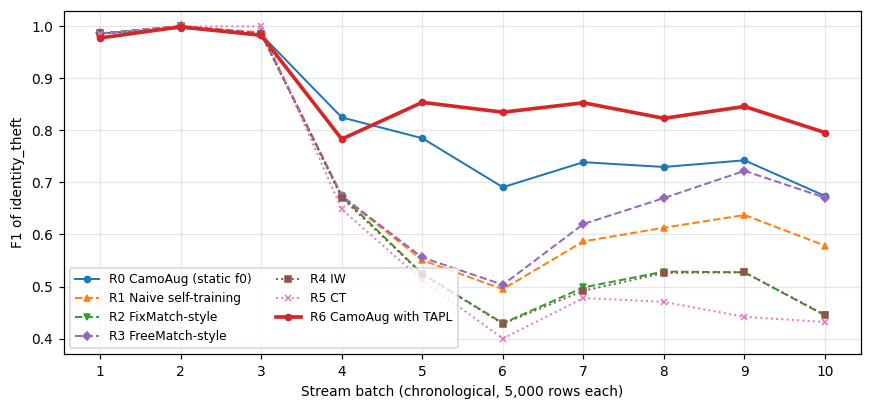

[saved tables/results_batch_camouflage_vs_gap.csv]
       share_camouflaged  gap_R6_minus_R0
batch                                    
1                 0.0000          -0.0086
2                 0.0000           0.0020
3                 0.0000          -0.0014
4                 0.4062          -0.0417
5                 0.5000           0.0689
6                 0.7045           0.1442
7                 0.5769           0.1142
8                 0.5812           0.0935
9                 0.6220           0.1035
10                0.6122           0.1218
Spearman(camouflaged share, R6 - R0 advantage) = 0.853 (p = 0.0017, n = 10 batches)


In [33]:
ms7 = TABLES["Retraining"]["methods"]
PB7 = PB[(PB["method"].isin(ms7)) & (PB["cls"] == TARGET_CLS)].groupby(["method", "batch"])["f1"].mean().unstack("batch")
save_table(PB7.reindex(ms7).round(4), "figure6_per_batch_f1_identity_theft", index=True)

fig, ax = plt.subplots(figsize=(8, 3.8))
styles = {M["R0"]: ("#1f77b4", "o", "-"), M["R1"]: ("#ff7f0e", "^", "--"), M["R2"]: ("#2ca02c", "v", "--"),
          M["R3"]: ("#9467bd", "D", "--"), M["R4"]: ("#8c564b", "s", ":"), M["R5"]: ("#e377c2", "x", ":"),
          M["R6"]: ("#d62728", "o", "-")}
for m in ms7:
    col, mk, ls = styles[m]
    ax.plot(PB7.columns, PB7.loc[m].values, marker=mk, ms=4, ls=ls, color=col,
            lw=2.4 if m == M["R6"] else 1.3, label=m)
ax.set_xlabel(f"Stream batch (chronological, {CFG['batch_size']:,} rows each)"); ax.set_ylabel(f"F1 of {TARGET_CLS}")
ax.set_xticks(list(PB7.columns)); ax.grid(alpha=0.3); ax.legend(ncol=2, loc="lower left")
plt.tight_layout(); save_fig(fig, "figure6_per_batch_f1"); plt.show()

gap = (PB7.loc[M["R6"]] - PB7.loc[M["R0"]]).rename("gap_R6_minus_R0")
cam = CAMO_BATCH[CAMO_BATCH.cls == TARGET_CLS].set_index("batch")["share_camouflaged"]
JB = pd.concat([cam, gap], axis=1).dropna()
save_table(JB.round(4), "results_batch_camouflage_vs_gap", index=True)
if len(JB) >= 4 and JB["share_camouflaged"].nunique() > 1:
    rho, p = spearmanr(JB["share_camouflaged"], JB["gap_R6_minus_R0"])
    print(f"Spearman(camouflaged share, R6 - R0 advantage) = {rho:.3f} (p = {p:.4f}, n = {len(JB)} batches)")
    EXTRA["rho_batch_camouflage_vs_gap"] = float(rho)

### Day-block bootstrap over the April stream
Whole days of the stream are resampled with replacement (2,000 resamples). For every resample the F1-score of
`identity_theft` and the macro-F1 are computed for every seed from the stored predictions, and the difference between
two methods is averaged over the seeds. The interval therefore reflects both the seeds and the transactions.


In [34]:
def f1_from_counts(y, p, idx):
    """Per-class F1 on the rows idx (fast confusion counts)."""
    cm = np.bincount(y[idx] * K + p[idx], minlength=K * K).reshape(K, K)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    return np.divide(2 * tp, den, out=np.zeros(K), where=den > 0)


_day = STREAM_TS.dt.floor("D").values
_days = np.unique(_day)
_rows_of_day = [np.where(_day == d)[0] for d in _days]
N_BOOT_DAY = 2000
_t = CLASSES.index(TARGET_CLS)
_pairs = [(M["R6"], M["R0"]), (M["R6"], M["A1"]), (M["R0"], M["A1"])]
_rng = np.random.default_rng(2026)
_draws = {p: {"f1_target": [], "macro_f1": []} for p in _pairs}
for _ in range(N_BOOT_DAY):
    idx = np.concatenate([_rows_of_day[j] for j in _rng.integers(0, len(_days), len(_days))])
    for (ma, mb) in _pairs:
        dt_, dm_ = [], []
        for sd in SEEDS_DONE:
            fa = f1_from_counts(S.yte, PRED_STORE[(ma, sd)].astype(int), idx)
            fb_ = f1_from_counts(S.yte, PRED_STORE[(mb, sd)].astype(int), idx)
            dt_.append(fa[_t] - fb_[_t]); dm_.append(fa.mean() - fb_.mean())
        _draws[(ma, mb)]["f1_target"].append(np.mean(dt_)); _draws[(ma, mb)]["macro_f1"].append(np.mean(dm_))
_all = np.arange(len(S.yte))
_bt = []
for (ma, mb), d in _draws.items():
    for metric, vals in d.items():
        vals = np.asarray(vals)
        point = np.mean([(f1_from_counts(S.yte, PRED_STORE[(ma, sd)].astype(int), _all)[_t]
                          - f1_from_counts(S.yte, PRED_STORE[(mb, sd)].astype(int), _all)[_t]) if metric == "f1_target" else
                         (f1_from_counts(S.yte, PRED_STORE[(ma, sd)].astype(int), _all).mean()
                          - f1_from_counts(S.yte, PRED_STORE[(mb, sd)].astype(int), _all).mean()) for sd in SEEDS_DONE])
        _bt.append(dict(comparison=f"{ma} vs {mb}", metric=f"F1 {TARGET_CLS}" if metric == "f1_target" else "macro-F1",
                        mean_diff=point, ci95_lo=float(np.percentile(vals, 2.5)), ci95_hi=float(np.percentile(vals, 97.5)),
                        share_resamples_above_0=float((vals > 0).mean())))
DAY_BOOT = pd.DataFrame(_bt)
save_table(DAY_BOOT.round(4), "results_day_block_bootstrap")
print(f"\nStream days: {len(_days)} | resamples: {N_BOOT_DAY} | seeds per resample: {len(SEEDS_DONE)}")


[saved tables/results_day_block_bootstrap.csv]
                                    comparison            metric  mean_diff  ci95_lo  ci95_hi  share_resamples_above_0
R6 CamoAug with TAPL vs R0 CamoAug (static f0) F1 identity_theft     0.0720   0.0472   0.0937                   1.0000
R6 CamoAug with TAPL vs R0 CamoAug (static f0)          macro-F1     0.0083   0.0033   0.0131                   0.9980
    R6 CamoAug with TAPL vs A1 No augmentation F1 identity_theft     0.2735   0.2101   0.3273                   1.0000
    R6 CamoAug with TAPL vs A1 No augmentation          macro-F1     0.0429   0.0316   0.0529                   1.0000
  R0 CamoAug (static f0) vs A1 No augmentation F1 identity_theft     0.2015   0.1569   0.2422                   1.0000
  R0 CamoAug (static f0) vs A1 No augmentation          macro-F1     0.0346   0.0267   0.0421                   1.0000

Stream days: 29 | resamples: 2000 | seeds per resample: 10


### Static models of every seed
The static models are rebuilt from the same seeds (TRAIN only) to obtain their stream probabilities. Their predictions
are compared with the stored predictions of the main experiment to confirm that the rebuild is identical.


In [35]:
STATIC_P = {}                 # seed -> stream and VALIDATION probabilities of A1 and f0
_rebuild = []
for sd in SEEDS_DONE:
    _plain, _ks, _fb = build_static(S, sd)
    STATIC_P[sd] = dict(A1=_plain.predict_proba(S.Xte).astype(np.float32),
                        f0=_fb["f0"].predict_proba(S.Xte).astype(np.float32),
                        f0_val=_fb["f0"].predict_proba(S.Xva).astype(np.float32),
                        A1_val=_plain.predict_proba(S.Xva).astype(np.float32))
    _rebuild.append(dict(seed=sd,
                         A1_identical=bool(np.array_equal(STATIC_P[sd]["A1"].argmax(1), PRED_STORE[(M["A1"], sd)])),
                         f0_identical=bool(np.array_equal(STATIC_P[sd]["f0"].argmax(1), PRED_STORE[(M["R0"], sd)]))))
    print(f"  seed {sd}: static models rebuilt")
REBUILD = pd.DataFrame(_rebuild)
print(REBUILD.to_string(index=False))
if not (REBUILD["A1_identical"].all() and REBUILD["f0_identical"].all()):
    print("Note: some rebuilt predictions differ from the stored ones (GPU non-determinism); the analyses below use the rebuilt models.")


  seed 42: static models rebuilt
  seed 43: static models rebuilt
  seed 44: static models rebuilt
  seed 45: static models rebuilt
  seed 46: static models rebuilt
  seed 47: static models rebuilt
  seed 48: static models rebuilt
  seed 49: static models rebuilt
  seed 50: static models rebuilt
  seed 51: static models rebuilt
 seed  A1_identical  f0_identical
   42          True          True
   43          True          True
   44          True          True
   45          True          True
   46          True          True
   47          True          True
   48          True          True
   49          True          True
   50          True          True
   51          True          True


### Prior-shift baseline (EM prior adjustment, no labels)
The adjustment multiplies the class probabilities by the ratio between the class priors estimated on the stream and
those estimated on VALIDATION. Both are estimated with the EM procedure of Saerens et al. (2002) on the model's own
probabilities, starting from the uniform prior that the balanced class weights impose during training.
For batch $t$, the stream priors are estimated only from the features of batches $1, \dots, t-1$; batch 1 is left
unchanged. No label of the stream or of VALIDATION is used.


In [36]:
def em_priors(P, prior0, n_iter=200, tol=1e-8):
    """EM estimate of the class priors of unlabeled rows (Saerens et al., 2002)."""
    prior0 = np.asarray(prior0, float); pi = prior0.copy()
    for _ in range(n_iter):
        Q = P * (pi / prior0); Q = Q / Q.sum(1, keepdims=True)
        new = Q.mean(0)
        if np.abs(new - pi).max() < tol:
            pi = new; break
        pi = new
    return pi


def prior_adjusted_stream(P_stream, P_val):
    uni = np.full(K, 1.0 / K)
    pi_ref = em_priors(P_val, uni)
    out = np.array(P_stream, dtype=float, copy=True)
    for bi, b in enumerate(S.batches):
        if bi == 0:
            continue
        past = np.concatenate(S.batches[:bi])
        pi_t = em_priors(P_stream[past], uni)               # both estimates start from the (balanced) training prior
        Q = P_stream[b] * (np.maximum(pi_t, 1e-6) / np.maximum(pi_ref, 1e-6))
        out[b] = Q / Q.sum(1, keepdims=True)
    return out


_pr_rows = []
for sd in SEEDS_DONE:
    for base, key in [("A1", "A1"), ("f0", "f0")]:
        Pv = STATIC_P[sd][f"{key}_val"]
        P_adj = prior_adjusted_stream(STATIC_P[sd][key].astype(float), np.asarray(Pv, float))
        overall, pr, rc, f1c, ap, pred = evaluate_stream(S, P_adj, True)
        _pr_rows.append(dict(method=f"EM prior adjustment on {base}", seed=sd, macro_f1=overall["macro_f1"],
                             **{f"f1_{CLASSES[c]}": f1c[c] for c in range(K)}))
PRIOR = pd.DataFrame(_pr_rows)
_ref = R[R.method.isin([M["A1"], M["R0"], M["R6"]])][["method", "seed", "macro_f1"] + [f"f1_{c}" for c in CLASSES]]
PRIOR_ALL = pd.concat([_ref, PRIOR], ignore_index=True)
PRIOR_SUM = PRIOR_ALL.groupby("method", sort=False)[["macro_f1", TGT] + [f"f1_{c}" for c in CLASSES if f"f1_{c}" != TGT]].mean()
save_table(PRIOR_SUM.round(4), "results_prior_shift_baseline", index=True)
_rows = []
for base in ("A1", "f0"):
    nm = f"EM prior adjustment on {base}"
    a = R[R.method == M["R6"]].set_index("seed").sort_index()
    b = PRIOR[PRIOR.method == nm].set_index("seed").sort_index()
    for metric in ("macro_f1", TGT):
        d = a[metric].values - b[metric].values
        _rows.append(dict(comparison=f"{M['R6']} vs {nm}", metric=metric, mean_diff=d.mean(),
                          wins=int((d > 1e-12).sum()), losses=int((d < -1e-12).sum()),
                          p=paired_wilcoxon(a[metric].values, b[metric].values, alt="greater")))
PRIOR_TEST = pd.DataFrame(_rows)
PRIOR_TEST["p_holm"] = holm(PRIOR_TEST["p"].values)
save_table(PRIOR_TEST.round(4), "results_prior_shift_tests")


[saved tables/results_prior_shift_baseline.csv]
                           macro_f1  f1_identity_theft  f1_legit  f1_account_takeover  f1_card_testing  f1_fraud_ring  f1_synthetic_identity
method                                                                                                                                      
A1 No augmentation           0.9111             0.5824    0.9937               0.9983           1.0000         0.9181                 0.9738
R0 CamoAug (static f0)       0.9457             0.7839    0.9960               0.9993           1.0000         0.9189                 0.9758
R6 CamoAug with TAPL         0.9540             0.8560    0.9970               0.9926           0.9992         0.9186                 0.9605
EM prior adjustment on A1    0.9109             0.5820    0.9937               0.9983           1.0000         0.9175                 0.9738
EM prior adjustment on f0    0.9479             0.7982    0.9962               0.9993           1.0000    

## Mechanism analysis

Post-hoc diagnostics: stream labels are used here to **measure** what each stage did, never to change a method.

* **Pseudo-label quality (10 seeds):** for every retraining method, the true class of every pseudo-labelled stream row is
  compared with its pseudo-label after the run (accepted retraining steps, summed over batches and seeds).
* **Recall on camouflaged versus classic rows (10 seeds)** and the share of the extra detections of R6 (versus R0) that
  are camouflaged rows.
* **Extra runs (5 seeds, 42-46):** (a) TAPL applied to A1 instead of f0; (b) oracle retraining with the true stream
  labels under the same protocol (a label-informed reference, **not a method**); (c) provenance of the TAPL
  pseudo-labels (confidence filter versus NP-Recovery); (d) true-class score of the camouflaged rows relative to the NP
  threshold, with and without CamoAug.

In [37]:
# ---- pseudo-label quality (10 seeds) -----------------------------------------------------------------
g = PQ[PQ["retrained"]].groupby(["method", "cls"])[["n_selected", "n_correct"]].sum()
g["n_wrong"] = g["n_selected"] - g["n_correct"]
g["precision"] = g["n_correct"] / g["n_selected"].clip(lower=1)
g.to_csv(out_path("pseudolabel_quality.csv"))
print("Pseudo-label precision per class (accepted retraining steps, summed over batches and seeds)")
print(g["precision"].unstack("cls").round(4).to_string())
legit_name = CLASSES[MAJOR]
WRONG_LEGIT = {m: int(g.loc[(m, legit_name), "n_wrong"]) for m in [M["R1"], M["R2"], M["R3"], M["R6"]]
               if (m, legit_name) in g.index}
IT_LABELS = {m: int(g.loc[(m, TARGET_CLS), "n_selected"]) for m in [M["T2"], M["R6"]] if (m, TARGET_CLS) in g.index}
print(f"\nStream rows of another class pseudo-labelled as {legit_name} (summed over {len(SEEDS_DONE)} seeds):", WRONG_LEGIT)
print(f"{TARGET_CLS} pseudo-labels:", IT_LABELS)

# ---- recall on camouflaged versus classic rows (10 seeds) --------------------------------------------
rec_rows = []
for m in KEY_METHODS + [M["A6"]]:
    for gname, gmask in [("classic", (S.yte == TARGET) & ~IS_CAMO), ("camouflaged", (S.yte == TARGET) & IS_CAMO)]:
        if gmask.sum() < 5:
            continue
        v = [float((pred_of(m, sd)[gmask] == TARGET).mean()) for sd in SEEDS_DONE]
        rec_rows.append(dict(method=m, group=gname, rows=int(gmask.sum()), recall=float(np.mean(v))))
RECSUB = pd.DataFrame(rec_rows)
piv = RECSUB.pivot(index="method", columns="group", values="recall").reindex(KEY_METHODS)
save_table(piv.round(4), "results_recall_camouflaged_vs_classic", index=True)

base = M["R0"]
d_cl = d_ca = 0.0
for sd in SEEDS_DONE:
    pm, pb_ = pred_of(M["R6"], sd), pred_of(base, sd)
    for mask, acc in [((S.yte == TARGET) & ~IS_CAMO, "cl"), ((S.yte == TARGET) & IS_CAMO, "ca")]:
        diff = int((pm[mask] == TARGET).sum() - (pb_[mask] == TARGET).sum())
        if acc == "cl": d_cl += diff
        else: d_ca += diff
d_cl /= len(SEEDS_DONE); d_ca /= len(SEEDS_DONE)
share_camo = abs(d_ca) / (abs(d_cl) + abs(d_ca)) if (abs(d_cl) + abs(d_ca)) else np.nan
print(f"\nExtra {TARGET_CLS} rows detected by R6 versus R0 (mean per seed): classic {d_cl:+.1f}, camouflaged {d_ca:+.1f}"
      f" -> {100 * share_camo:.1f}% of the extra detections are camouflaged rows")
EXTRA.update(recall_camouflaged_R0=float(piv.loc[M["R0"], "camouflaged"]),
             recall_camouflaged_R6=float(piv.loc[M["R6"], "camouflaged"]),
             share_of_gain_from_camouflaged=float(share_camo))

Pseudo-label precision per class (accepted retraining steps, summed over batches and seeds)
cls                              account_takeover    all  card_testing  fraud_ring  identity_theft  legit  synthetic_identity
method                                                                                                                       
R1 Naive self-training                     0.9996 0.9900        1.0000      0.8516          0.9937 0.9905              0.9587
R2 FixMatch-style                          1.0000 0.9959        1.0000      0.9895          0.9978 0.9959              0.9950
R3 FreeMatch-style                         0.9988 0.9970        1.0000      0.8489          0.9937 0.9978              0.9594
R5 CT                                      1.0000 0.9991        1.0000      1.0000          1.0000 0.9991              0.0000
R6 CamoAug with TAPL                       0.9725 0.9981        1.0000      0.9937          0.9507 0.9989              0.9341
T0 Full method (R6)       

In [38]:
def make_oracle_filter(S_):
    """CEILING ONLY - uses the true stream labels on purpose. Never report this as a method."""
    state = dict(i=0)

    def f(Xb, P, P0, Pm, pred):
        b = S_.batches[state["i"]]; state["i"] += 1
        return np.ones(len(pred), bool), S_.yte[b].copy(), np.full(len(pred), CFG["stream"]["pl_weight"])
    return f


def make_tapl_filter_logged(cal, store, params=TAPL):
    """Identical to make_tapl_filter(all options on), but records where each pseudo-label came from."""
    def f(Xb, P, P0, Pm, pred):
        n = len(pred); ar = np.arange(n)
        ok = P[ar, pred] >= cal["T"][pred]
        Pa = P.copy(); Pa[ar, pred] = -1.0
        ok &= Pa.max(1) < cal["tau"][pred]
        by_filter = ok.copy()
        y_pl = pred.copy(); w_pl = np.full(n, CFG["stream"]["pl_weight"])
        Q = P0.copy(); Q[ar, pred] = -1.0
        cs = Q.argmax(1)
        rec = Q[ar, cs] >= cal["theta"][cs]
        y_pl[rec] = cs[rec]; w_pl[rec] = params["w_recover"]; ok[rec] = True
        store.append(dict(by_filter=by_filter & ~rec, recovered=rec.copy(), accepted=ok.copy(), y_pl=y_pl.copy()))
        return ok, y_pl, w_pl
    return f


EXR, PROV, SCORED = [], [], []
for sd in SEEDS["mechanism"]:
    t0 = time.time()
    plain, KS, fb = build_static(S, sd)
    f0 = fb["f0"]
    cal0, calP = calibrate_tapl(S, f0), calibrate_tapl(S, plain)
    P_plain, P_f0 = plain.predict_proba(S.Xte), f0.predict_proba(S.Xte)

    def note(name, P):
        f1c = per_class_f1(S.yte, P)
        EXR.append(dict(seed=sd, method=name, macro_f1=float(f1c.mean()), **{f"f1_{CLASSES[c]}": float(f1c[c]) for c in range(K)}))

    note(M["A1"], P_plain)
    note(M["R0"], P_f0)
    # (a) TAPL on the plain model A1 (no CamoAug)
    r_a = run_tapl(S, plain, sd, calP)
    note("TAPL on A1 (no CamoAug)", apply_bias(r_a.P, calP["bias"]))
    # (c) TAPL on f0 with provenance logging (identical to R6, instrumented)
    store = []
    r_c = run_stream(S, f0, sd, make_tapl_filter_logged(cal0, store))
    note(M["R6"] + " [re-run]", apply_bias(r_c.P, cal0["bias"]))
    used = np.zeros(len(S.yte), bool)
    for e in r_c.log:
        if e.get("retrained", True):
            used[e["test_idx"]] = True
    for bi, st in enumerate(store):
        b = S.batches[bi]
        for src in ("by_filter", "recovered"):
            m = st[src]
            if not m.any():
                continue
            g_idx = b[m]
            correct = S.yte[g_idx] == st["y_pl"][m]
            for c in [None] + list(range(K)):
                sel = np.ones(m.sum(), bool) if c is None else (st["y_pl"][m] == c)
                if sel.any():
                    PROV.append(dict(seed=sd, batch=bi + 1, source=src, cls="all" if c is None else CLASSES[c],
                                     n=int(sel.sum()), n_correct=int(correct[sel].sum()), n_used=int(used[g_idx[sel]].sum())))
    # (b) oracle: retraining with the true stream labels (label-informed reference, not a method)
    r_o = run_stream(S, f0, sd, make_oracle_filter(S))
    note("Oracle retraining (true stream labels)", r_o.P)
    # (d) true-class score of the camouflaged rows, with and without CamoAug
    for mdl_name, P_, cal_ in [(M["A1"], P_plain, calP), (M["R0"], P_f0, cal0)]:
        for gname, gmask in [("classic", (S.yte == TARGET) & ~IS_CAMO), ("camouflaged", (S.yte == TARGET) & IS_CAMO)]:
            if gmask.sum() < 3:
                continue
            s_true = P_[gmask, TARGET]
            SCORED.append(dict(seed=sd, model=mdl_name, group=gname, rows=int(gmask.sum()),
                               mean_score=float(s_true.mean()), theta=float(cal_["theta"][TARGET]),
                               share_above_theta=float((s_true >= cal_["theta"][TARGET]).mean())))
    print(f"  mechanism runs: seed {sd} done in {time.time() - t0:.0f}s")

EXRD = pd.DataFrame(EXR); EXRD.to_csv(out_path("mechanism_runs.csv"), index=False)
PV = pd.DataFrame(PROV); PV.to_csv(out_path("pseudolabel_provenance.csv"), index=False)
SC = pd.DataFrame(SCORED); SC.to_csv(out_path("score_diagnostics.csv"), index=False)

mech = EXRD.groupby("method")[["macro_f1"] + [f"f1_{c}" for c in CLASSES]].mean()
print(f"\nMean over {len(SEEDS['mechanism'])} seeds")
print(mech.round(4).to_string())
gv = lambda m: float(mech.loc[m, f"f1_{TARGET_CLS}"])
g_plain = gv("TAPL on A1 (no CamoAug)") - gv(M["A1"])
g_camo = gv(M["R6"] + " [re-run]") - gv(M["R0"])
f_static, f_prop, f_orc = gv(M["R0"]), gv(M["R6"] + " [re-run]"), gv("Oracle retraining (true stream labels)")
closed = (f_prop - f_static) / (f_orc - f_static) if f_orc > f_static else np.nan
sc = SC.groupby(["model", "group"])[["rows", "mean_score", "theta", "share_above_theta"]].mean()
print("\nTrue-class score of the identity_theft rows")
print(sc.round(4).to_string())
pv = PV.groupby(["source", "cls"])[["n", "n_correct"]].sum()
pv["precision"] = pv["n_correct"] / pv["n"].clip(lower=1)
print("\nPseudo-label provenance (summed over batches and seeds)")
print(pv.round(4).to_string())
rec_t = pv.loc[("recovered", TARGET_CLS)] if ("recovered", TARGET_CLS) in pv.index else None
EXTRA.update(tapl_gain_on_plain=g_plain, tapl_gain_on_camoaug=g_camo, share_of_oracle_gap_closed=closed,
             camo_visible_to_np_plain=float(sc.loc[(M["A1"], "camouflaged"), "share_above_theta"]),
             camo_visible_to_np_camoaug=float(sc.loc[(M["R0"], "camouflaged"), "share_above_theta"]))

  mechanism runs: seed 42 done in 107s
  mechanism runs: seed 43 done in 107s
  mechanism runs: seed 44 done in 108s
  mechanism runs: seed 45 done in 109s
  mechanism runs: seed 46 done in 108s

Mean over 5 seeds
                                        macro_f1  f1_legit  f1_identity_theft  f1_account_takeover  f1_card_testing  f1_fraud_ring  f1_synthetic_identity
method                                                                                                                                                   
A1 No augmentation                        0.9111    0.9937             0.5824               0.9983           1.0000         0.9185                 0.9738
Oracle retraining (true stream labels)    0.9573    0.9970             0.8511               1.0000           1.0000         0.9182                 0.9776
R0 CamoAug (static f0)                    0.9467    0.9961             0.7889               0.9997           1.0000         0.9196                 0.9761
R6 CamoAug with 

### Realized false positive rate of the NP thresholds
For every class $k$, the false positive rate is the share of rows that do not belong to $k$ and whose score
$P_0(k|\mathbf{x})$ under the static model reaches $\theta_k$. It is computed on VALIDATION (where $\theta_k$ was
calibrated) and on the April stream. Counts are pooled over seeds for the Clopper–Pearson interval.


In [39]:
def clopper_pearson(x, n, alpha=0.05):
    lo = stats.beta.ppf(alpha / 2, x, n - x + 1) if x > 0 else 0.0
    hi = stats.beta.ppf(1 - alpha / 2, x + 1, n - x) if x < n else 1.0
    return float(lo), float(hi)


_np_rows = []
for k in range(K):
    for split_name, ys, key in [("VALIDATION", S.yva, "f0_val"), ("STREAM", S.yte, "f0")]:
        x_tot = n_tot = 0
        per_seed = []
        for sd in SEEDS_DONE:
            th = float(CAL.set_index("seed").loc[sd, f"theta_{CLASSES[k]}"])
            neg = ys != k
            exceed = STATIC_P[sd][key][neg, k] >= th
            x_tot += int(exceed.sum()); n_tot += int(neg.sum()); per_seed.append(float(exceed.mean()))
        lo, hi = clopper_pearson(x_tot, n_tot)
        _np_rows.append(dict(cls=CLASSES[k], split=split_name, target_eps=TAPL["rec_fpr"],
                             non_class_rows_per_seed=n_tot // len(SEEDS_DONE),
                             expected_exceedances_per_seed=round(TAPL["rec_fpr"] * n_tot / len(SEEDS_DONE), 1),
                             exceedances_per_seed=round(x_tot / len(SEEDS_DONE), 1),
                             fpr_pooled=x_tot / n_tot, cp95_lo=lo, cp95_hi=hi,
                             fpr_seed_min=min(per_seed), fpr_seed_max=max(per_seed)))
NP_FPR = pd.DataFrame(_np_rows)
save_table(NP_FPR, "results_np_threshold_fpr")
_s = NP_FPR[NP_FPR.split == "STREAM"].set_index("cls")
EXTRA["np_stream_fpr_target"] = float(_s.loc[TARGET_CLS, "fpr_pooled"])
print(f"\nClasses whose stream rate exceeds the target eps = {TAPL['rec_fpr']}: "
      f"{[c for c in CLASSES if _s.loc[c, 'fpr_pooled'] > TAPL['rec_fpr']]}")


[saved tables/results_np_threshold_fpr.csv]
               cls      split  target_eps  non_class_rows_per_seed  expected_exceedances_per_seed  exceedances_per_seed  fpr_pooled  cp95_lo  cp95_hi  fpr_seed_min  fpr_seed_max
             legit VALIDATION      0.0005                      450                         0.2000                1.0000      0.0022   0.0011   0.0041        0.0022        0.0022
             legit     STREAM      0.0005                     1813                         0.9000              213.6000      0.1178   0.1132   0.1226        0.0932        0.1699
    identity_theft VALIDATION      0.0005                    18404                         9.2000               10.0000      0.0005   0.0004   0.0007        0.0005        0.0005
    identity_theft     STREAM      0.0005                    47806                        23.9000               24.8000      0.0005   0.0005   0.0006        0.0004        0.0006
  account_takeover VALIDATION      0.0005                    18416

### Summary of the mechanism evidence
Every row states the number of seeds it is computed on.

In [40]:
n10, n5 = len(SEEDS_DONE), len(SEEDS["mechanism"])
_sc = lambda mdl, col: float(sc.loc[(mdl, "camouflaged"), col])
T8 = pd.DataFrame([
    dict(stage="CamoAug", quantity=f"Camouflaged {TARGET_CLS} rows above the NP threshold of the model", seeds=n5,
         without=f"{100 * _sc(M['A1'], 'share_above_theta'):.1f}% (A1, theta = {_sc(M['A1'], 'theta'):.4f})",
         with_=f"{100 * _sc(M['R0'], 'share_above_theta'):.1f}% (f0, theta = {_sc(M['R0'], 'theta'):.4f})"),
    dict(stage="CamoAug", quantity="Mean true-class score of camouflaged rows", seeds=n5,
         without=f"{_sc(M['A1'], 'mean_score'):.4f} (A1)", with_=f"{_sc(M['R0'], 'mean_score'):.3f} (f0)"),
    dict(stage="CamoAug + TAPL", quantity=f"F1 gain of TAPL on {TARGET_CLS}", seeds=n5,
         without=f"{g_plain:+.4f} (TAPL on A1)", with_=f"{g_camo:+.4f} (TAPL on f0)"),
    dict(stage="TAPL filter", quantity=f"Rows of another class pseudo-labelled as {legit_name}", seeds=n10,
         without=" / ".join(f"{WRONG_LEGIT.get(M[k], np.nan):,}" for k in ["R1", "R2", "R3"]) + " (R1 / R2 / R3)",
         with_=f"{WRONG_LEGIT.get(M['R6'], np.nan):,} (R6)"),
    dict(stage="NP-Recovery", quantity=f"{TARGET_CLS} pseudo-labels", seeds=n10,
         without=f"{IT_LABELS.get(M['T2'], np.nan):,} (T2)", with_=f"{IT_LABELS.get(M['R6'], np.nan):,} (R6)"),
    dict(stage="NP-Recovery", quantity=f"Precision of recovered {TARGET_CLS} labels", seeds=n5, without="-",
         with_=(f"{rec_t['precision']:.3f} ({int(rec_t['n'])} labels)" if rec_t is not None else "-")),
    dict(stage="Whole method", quantity=f"Recall on camouflaged {TARGET_CLS} rows", seeds=n10,
         without=f"{EXTRA['recall_camouflaged_R0']:.3f} (R0)", with_=f"{EXTRA['recall_camouflaged_R6']:.3f} (R6)"),
    dict(stage="Whole method", quantity=f"F1 {TARGET_CLS}: static / proposed / oracle retraining", seeds=n5,
         without=f"{f_static:.3f}", with_=f"{f_prop:.3f} / {f_orc:.3f}"),
]).rename(columns={"with_": "with"})
save_table(T8, "table8_mechanism")
print(f"\nShare of the gap between the static model and the oracle retraining closed by R6 without labels: "
      f"{100 * closed:.1f}% ({n5} seeds). The oracle uses the same retraining protocol with true labels; it is a "
      f"label-informed reference, not an upper bound on every possible decision rule.")

[saved tables/table8_mechanism.csv]
         stage                                                            quantity  seeds                            without                       with
       CamoAug Camouflaged identity_theft rows above the NP threshold of the model      5          0.3% (A1, theta = 0.0091) 60.6% (f0, theta = 0.0891)
       CamoAug                           Mean true-class score of camouflaged rows      5                        0.0003 (A1)                 0.404 (f0)
CamoAug + TAPL                                   F1 gain of TAPL on identity_theft      5               -0.0006 (TAPL on A1)       +0.0574 (TAPL on f0)
   TAPL filter                      Rows of another class pseudo-labelled as legit     10 3,957 / 1,794 / 911 (R1 / R2 / R3)                   431 (R6)
   NP-Recovery                                        identity_theft pseudo-labels     10                         3,225 (T2)                 4,135 (R6)
   NP-Recovery                        Precision of r

## Augmentation methods and ablations
(a) Augmentation methods on the static model (one-sided Wilcoxon of A6 against A1); (b) CamoAug ablation (reference
C0 = A6); (c) TAPL ablation (reference T0 = R6). Panels (b) and (c): two-sided paired Wilcoxon of each variant against
the full variant, Holm within the panel.

In [41]:
def mean_of(m, col):
    return float(R[R["method"] == m][col].mean())


def abl_p(tag, m, metric):
    T = TEST_OUT[(tag, "ablation", metric)].set_index("comparison")
    return float(T.loc[f"{m} minus full", "p_holm"])


rows9 = []
for key in ["A1", "A2", "A3", "A4", "A5", "A6"]:
    m = M[key]
    p_m = p_t = "-"
    if key == "A6":
        p_m = f"{TEST_OUT[('Augmentation', 'vs_ref', 'macro_f1')].set_index('comparison').loc[f'{m} vs {M["A1"]}', 'p_holm']:.3f}"
        p_t = f"{TEST_OUT[('Augmentation', 'vs_ref', TGT)].set_index('comparison').loc[f'{m} vs {M["A1"]}', 'p_holm']:.3f}"
    rows9.append(dict(panel="(a) augmentation", variant=m, synthetic_rows=rhu(mean_of(m, "n_synthetic")),
                      macro_f1=round(mean_of(m, "macro_f1"), 4), p_holm_macro=p_m,
                      f1_target=round(mean_of(m, TGT), 4), p_holm_target=p_t))
for key in ["C1", "C2", "C3", "C4", "C5"]:
    m = M[key]
    rows9.append(dict(panel="(b) CamoAug ablation", variant=m, synthetic_rows=rhu(mean_of(m, "n_synthetic")),
                      macro_f1=round(mean_of(m, "macro_f1"), 4), p_holm_macro=f"{abl_p('CamoAug ablation', m, 'macro_f1'):.3f}",
                      f1_target=round(mean_of(m, TGT), 4), p_holm_target=f"{abl_p('CamoAug ablation', m, TGT):.3f}"))
for key in ["T0", "T1", "T2", "T3", "T4", "T5", "T6", "T7", "T8"]:
    m = M[key]
    rows9.append(dict(panel="(c) TAPL ablation", variant=m, synthetic_rows=rhu(mean_of(M["R0"], "n_synthetic")),
                      macro_f1=round(mean_of(m, "macro_f1"), 4),
                      p_holm_macro="-" if key == "T0" else f"{abl_p('TAPL ablation', m, 'macro_f1'):.3f}",
                      f1_target=round(mean_of(m, TGT), 4),
                      p_holm_target="-" if key == "T0" else f"{abl_p('TAPL ablation', m, TGT):.3f}"))
T9 = pd.DataFrame(rows9)
save_table(T9, "table9_augmentation_and_ablation")

_same = [M[k] for k in ["T1", "T5", "T6", "T8"]
         if np.array_equal(np.stack([pred_of(M[k], s) for s in SEEDS_DONE]), np.stack([pred_of(M["T0"], s) for s in SEEDS_DONE]))]
print("\nTAPL variants whose predictions are identical to the full method on every seed:", _same or "none")
print("\nPer-class F1 change when a component is removed (negative = the component helps)")
for tag in ("CamoAug ablation", "TAPL ablation"):
    print(f"\n{tag}"); print(TEST_OUT[(tag, "ablation_summary")].round(4).to_string())

[saved tables/table9_augmentation_and_ablation.csv]
               panel                            variant  synthetic_rows  macro_f1 p_holm_macro  f1_target p_holm_target
    (a) augmentation                 A1 No augmentation               0    0.9111            -     0.5824             -
    (a) augmentation                           A2 SMOTE            3300    0.9114            -     0.5824             -
    (a) augmentation                           A3 Mixup            3300    0.8972            -     0.5817             -
    (a) augmentation                A4 SCARF-style swap            3300    0.8706            -     0.6297             -
    (a) augmentation                          A5 ADASYN            3300    0.9097            -     0.5823             -
    (a) augmentation                         A6 CamoAug             109    0.9457        0.005     0.7839         0.005
(b) CamoAug ablation      C1 uniform q (no KS guidance)            3179    0.8543        0.010     0.6141   

### Pairwise tests of CamoAug against the other augmentation methods
One-sided paired Wilcoxon tests (CamoAug better), Holm correction over the four comparisons for each metric.


In [42]:
_aug_pairs = [(f"{M['A6']} vs {M[k]}", M["A6"], M[k]) for k in ("A2", "A3", "A4", "A5")]
AUG_PAIRS = pd.concat([pair_rows(_aug_pairs, "macro_f1", "greater").assign(metric="macro-F1"),
                       pair_rows(_aug_pairs, TGT, "greater").assign(metric=f"F1 {TARGET_CLS}")], ignore_index=True)
save_table(AUG_PAIRS[["metric", "comparison", "mean_diff", "ci95_lo", "ci95_hi", "wins", "ties", "losses",
                      "p", "p_holm"]].round(4), "results_augmentation_pairwise")


[saved tables/results_augmentation_pairwise.csv]
           metric                        comparison  mean_diff  ci95_lo  ci95_hi  wins  ties  losses      p  p_holm
         macro-F1            A6 CamoAug vs A2 SMOTE     0.0342   0.0311   0.0370    10     0       0 0.0010  0.0039
         macro-F1            A6 CamoAug vs A3 Mixup     0.0484   0.0458   0.0510    10     0       0 0.0010  0.0039
         macro-F1 A6 CamoAug vs A4 SCARF-style swap     0.0751   0.0704   0.0798    10     0       0 0.0010  0.0039
         macro-F1           A6 CamoAug vs A5 ADASYN     0.0360   0.0326   0.0390    10     0       0 0.0010  0.0039
F1 identity_theft            A6 CamoAug vs A2 SMOTE     0.2015   0.1827   0.2180    10     0       0 0.0010  0.0039
F1 identity_theft            A6 CamoAug vs A3 Mixup     0.2022   0.1833   0.2188    10     0       0 0.0010  0.0039
F1 identity_theft A6 CamoAug vs A4 SCARF-style swap     0.1543   0.1353   0.1712    10     0       0 0.0010  0.0039
F1 identity_theft      

### What BLB contributes on each seed
The benefit of BLB (R6 minus T3 on the target class) against the bias the calibration selected for the target class.

In [43]:
a = R[R.method == M["T0"]].set_index("seed")[TGT]
b = R[R.method == M["T3"]].set_index("seed")[TGT]
J = pd.DataFrame({"bias_target": CAL.set_index("seed")[f"b_{TARGET_CLS}"], "f1_with_blb": a, "f1_without_blb": b}).dropna()
J["benefit_of_blb"] = J["f1_with_blb"] - J["f1_without_blb"]
save_table(J.round(4), "results_blb_bias_vs_benefit", index=True)
if len(J) >= 4 and J["bias_target"].nunique() > 1:
    rho, p = spearmanr(J["bias_target"], J["benefit_of_blb"])
    print(f"Spearman(bias, benefit) = {rho:.2f} (p = {p:.4f}, n = {len(J)} seeds); seeds with bias 0: "
          f"{int((J['bias_target'] == 0).sum())}")
    EXTRA["rho_blb_bias_vs_benefit"] = float(rho)

[saved tables/results_blb_bias_vs_benefit.csv]
      bias_target  f1_with_blb  f1_without_blb  benefit_of_blb
seed                                                          
42         1.7500       0.8850          0.8422          0.0429
43         0.7500       0.8609          0.8242          0.0366
44         0.0000       0.8280          0.8280          0.0000
45         0.0000       0.7744          0.7744          0.0000
46         1.0000       0.8835          0.8417          0.0418
47         1.7500       0.8718          0.8104          0.0614
48         0.0000       0.8325          0.8332         -0.0007
49         2.0000       0.8582          0.7742          0.0839
50         1.7500       0.8812          0.8455          0.0357
51         2.0000       0.8840          0.8216          0.0624
Spearman(bias, benefit) = 0.91 (p = 0.0002, n = 10 seeds); seeds with bias 0: 3


## Robustness and generality

### Drift severity: rolling windows
The whole pipeline, calibration included, is repeated on four earlier windows (W1-W4) and on the main window, with 5
seeds. TRAIN always starts on 1 January 2025; each window has an 11-day VALIDATION period and a four-week stream.
**Drift severity** of a window is defined as `1 - F1 of identity_theft of A1` in that window (a descriptive quantity
computed with the window's stream labels). Gains: CamoAug = A6 - A1, TAPL = R6 - A6.

In [44]:
ROLL_WINDOWS = [("W1", "2025-02-14", "2025-02-25", "2025-03-25"),
                ("W2", "2025-02-28", "2025-03-10", "2025-04-08"),
                ("W3", "2025-03-07", "2025-03-18", "2025-04-15"),
                ("W4", "2025-03-14", "2025-03-25", "2025-04-22"),
                ("Main", CFG["split"]["train_end"], CFG["split"]["val_end"], CFG["split"]["test_end"])]
roll = []
for name, t_end, v_end, te_end in ROLL_WINDOWS:
    Sw = S_MAIN if name == "Main" else build_split(name, CFG["split"]["train_start"], t_end, v_end, te_end)
    present = [c for c in range(K) if (Sw.yte == c).sum() > 0 and (Sw.ytr == c).sum() >= 10]
    print(f"{name}: train < {t_end}, val < {v_end}, test < {te_end} | stream rows {len(Sw.yte):,}")
    for sd in SEEDS["rolling"]:
        plain, KS, fb = build_static(Sw, sd)
        f0 = fb["f0"]; Pf = f0.predict_proba(Sw.Xte); cal = calibrate_tapl(Sw, f0)
        outs = {M["A1"]: plain.predict_proba(Sw.Xte), M["A6"]: Pf,
                M["R6"]: apply_bias(run_tapl(Sw, f0, sd, cal).P, cal["bias"])}
        for nm, P in outs.items():
            f1c = f1_score(Sw.yte, P.argmax(1), average=None, labels=range(K), zero_division=0)
            roll.append(dict(window=name, seed=sd, method=nm, macro_f1=float(f1c[present].mean()),
                             **{f"f1_{CLASSES[c]}": (f1c[c] if c in present else np.nan) for c in range(K)}))
RL = pd.DataFrame(roll)
RL.to_csv(out_path("rolling_windows_per_seed.csv"), index=False)

w = RL.groupby(["window", "method"])[[TGT, "macro_f1", "f1_synthetic_identity"]].mean()
val = lambda win, m, col=TGT: float(w.loc[(win, m), col])
SEV = pd.DataFrame([dict(window=win, start_train=CFG["split"]["train_start"], end_train_excl=t_end, end_val_excl=v_end,
                         end_stream_excl=te_end, severity=1 - val(win, M["A1"]),
                         f1_A1=val(win, M["A1"]), f1_A6=val(win, M["A6"]), f1_R6=val(win, M["R6"]),
                         gain_camoaug=val(win, M["A6"]) - val(win, M["A1"]), gain_tapl=val(win, M["R6"]) - val(win, M["A6"]),
                         macro_gain_tapl=val(win, M["R6"], "macro_f1") - val(win, M["A6"], "macro_f1"),
                         synthetic_identity_change_tapl=val(win, M["R6"], "f1_synthetic_identity") - val(win, M["A6"], "f1_synthetic_identity"))
                    for win, t_end, v_end, te_end in ROLL_WINDOWS])
save_table(SEV.round(4), "results_drift_severity_windows")
for col, lab in [("gain_camoaug", "CamoAug"), ("gain_tapl", "TAPL")]:
    rho, p = spearmanr(SEV["severity"], SEV[col])
    print(f"Spearman(severity, gain of {lab}) = {rho:.2f} (p = {p:.3f}, n = {len(SEV)} windows)")
    EXTRA[f"rho_severity_{lab.lower()}"] = float(rho)

W1: train < 2025-02-14, val < 2025-02-25, test < 2025-03-25 | stream rows 47,107
W2: train < 2025-02-28, val < 2025-03-10, test < 2025-04-08 | stream rows 48,664
W3: train < 2025-03-07, val < 2025-03-18, test < 2025-04-15 | stream rows 46,949
W4: train < 2025-03-14, val < 2025-03-25, test < 2025-04-22 | stream rows 47,163
Main: train < 2025-03-21, val < 2025-04-01, test < 2025-04-30 | stream rows 48,763
[saved tables/results_drift_severity_windows.csv]
window start_train end_train_excl end_val_excl end_stream_excl  severity  f1_A1  f1_A6  f1_R6  gain_camoaug  gain_tapl  macro_gain_tapl  synthetic_identity_change_tapl
    W1  2025-01-01     2025-02-14   2025-02-25      2025-03-25    0.0033 0.9967 0.9929 0.9852       -0.0039    -0.0077          -0.0030                         -0.0063
    W2  2025-01-01     2025-02-28   2025-03-10      2025-04-08    0.0058 0.9942 0.9954 0.9948        0.0012    -0.0006          -0.0067                         -0.0228
    W3  2025-01-01     2025-03-07   202

### Camouflage drift simulated in other classes

Two scenarios: (1) `card_testing` mimics `legit`; (2) `account_takeover` mimics `identity_theft`, `identity_theft`
mimics `card_testing` and `card_testing` mimics `synthetic_identity`. The simulator is the environment, not a method:

1. **Which rows:** in stream batch *b*, a row of the source class drifts with a probability equal to the share of
   naturally camouflaged `identity_theft` rows in batch *b* (0 in batches 1-3, then 0.41-0.70). Rows that are already
   naturally camouflaged are not drifted again.
2. **Which markers:** the *m* strongest TRAIN markers of the source class, with *m* chosen so that the residual signal
   (mean of the three largest KS statistics against TRAIN `legit`) is closest to that of the naturally camouflaged
   `identity_theft` rows. *m* and *t* are calibrated once, with the first seed.
3. **How far:** `x' = x + t (x_donor - x)` with one TRAIN donor row of the mimicked class (binary markers take the donor
   value with probability *t*); *t* is the smallest grid value at which A1 recognises at most 5 percentage points more
   of the shifted VALIDATION rows than it recognises of the naturally camouflaged `identity_theft` rows. Only A1 is used.
4. **Consistency:** `amount_deviation_ratio` is recomputed as `transaction_amount / avg_amount_30d`.

Stream labels are used by the simulator only to select the rows to modify; every method receives only the modified
features. All twelve methods (A1-A5, R0, R1-R6) run on the same simulated stream.

In [45]:
NATURAL = -1.0                      # rate code: per-batch share copied from the natural identity_theft drift
SC_RATES = [NATURAL]                # e.g. [NATURAL, 0.3] to also run a fixed 30% rate
SC_SEEDS = SEEDS["scenarios"]
SC_METHODS = ["A1", "A2", "A3", "A4", "A5", "R0", "R1", "R2", "R3", "R4", "R5", "R6"]
SC_RESUME = True

_C = {n: CLASSES.index(n) for n in CLASSES}
LEGIT = int(np.argmax(np.bincount(S.ytr)))
IT = _C["identity_theft"]
SCENARIOS = [
    dict(k=1, name="card_testing resembles legit",
         mapping={_C["card_testing"]: LEGIT}),
    dict(k=2, name="account_takeover resembles identity_theft, identity_theft resembles card_testing, "
                   "card_testing resembles synthetic_identity",
         mapping={_C["account_takeover"]: _C["identity_theft"], _C["identity_theft"]: _C["card_testing"],
                  _C["card_testing"]: _C["synthetic_identity"]}),
]
# source classes of all scenarios (calibrated once each)
SC_INJ = sorted({s_ for sc in SCENARIOS for s_ in sc["mapping"]})
_MCODE = {k: M[k] for k in SC_METHODS}
_onset = int(len(S.batches) / 3)
_window = np.concatenate(S.batches[_onset:])
_maj_tr = S.Xtr[S.ytr == LEGIT]
_F = {f: i for i, f in enumerate(FEATURES)}


def rl(r):
    """label of a rate code"""
    return "identity_theft pattern" if r == NATURAL else f"{r:.0%}"


def rtag(r):
    return "natural" if r == NATURAL else str(int(round(r * 100)))


SC_TAG = "" if SC_RATES == [0.1, 0.3, 0.5] else "_" + "_".join(rtag(r) for r in SC_RATES)
# natural drift profile: share of camouflaged identity_theft rows in every stream batch (IS_CAMO from the camouflage analysis)
NAT_PROFILE = np.array([float(IS_CAMO[b][S.yte[b] == CLASSES.index("identity_theft")].mean())
                        if (S.yte[b] == CLASSES.index("identity_theft")).any() else 0.0 for b in S.batches])


def residual_signal(Xrows):
    """Mean of the 3 largest KS statistics of the rows against TRAIN legit (the measure of the camouflage analysis)."""
    ks = np.array([stats.ks_2samp(Xrows[:, j], _maj_tr[:, j]).statistic for j in range(S.d)])
    return float(np.sort(ks)[-3:].mean())


# ---- amount_deviation_ratio = transaction_amount / avg_amount_30d ? ------------------------------------
RATIO_OK = False
if all(f in _F for f in ("amount_deviation_ratio", "transaction_amount", "avg_amount_30d")):
    _a, _m, _r = (S.Xtr[:, _F[f]] for f in ("transaction_amount", "avg_amount_30d", "amount_deviation_ratio"))
    _ok = _m > 0
    _rel = np.median(np.abs(_a[_ok] / _m[_ok] - _r[_ok]) / np.maximum(np.abs(_r[_ok]), 1e-9))
    RATIO_OK = bool(_rel < 0.02)


T_PAIR = {}                          # (source, donor) -> shift fraction t; empty = full replacement (t = 1)
_IS_BIN = np.array([set(np.unique(S.Xtr[:, j])) <= {0.0, 1.0} for j in range(S.d)])
_IS_INT = np.array([np.allclose(S.Xtr[:, j], np.round(S.Xtr[:, j])) for j in range(S.d)])


def move_markers(X, rows, s, donor, KS_, m, t, rng):
    """Move the m strongest TRAIN markers of class s towards the donor values.
    t = 1: the donor value (full replacement). t < 1: partial shift x + t (donor - x) for numeric markers
    (rounded for integer features); a binary marker takes the donor value with probability t."""
    for j in np.argsort(-KS_[s])[:m]:
        x = X[rows, j]
        if t >= 1.0:
            X[rows, j] = donor[:, j]
        elif _IS_BIN[j] or j in CAT_IDX:
            X[rows, j] = np.where(rng.random(len(rows)) < t, donor[:, j], x)
        else:
            v = x + t * (donor[:, j] - x)
            X[rows, j] = np.round(v) if _IS_INT[j] else v
    if RATIO_OK and len(rows):
        a, mm = X[rows, _F["transaction_amount"]], X[rows, _F["avg_amount_30d"]]
        X[rows, _F["amount_deviation_ratio"]] = np.where(mm > 0, a / np.maximum(mm, 1e-9), X[rows, _F["amount_deviation_ratio"]])


def inject_scenario(S_, KS_, seed, rate, mapping, m_by_class, salt):
    """Environment simulator. Returns the drifted split and the drifted stream rows of every source class."""
    rng = np.random.default_rng(seed + 20000 + salt + int(round(rate * 100)))
    X = S_.Xte.copy()
    picked = {}
    for s, d in mapping.items():
        if rate == NATURAL:
            pick = np.concatenate([b[(S_.yte[b] == s) & ~IS_CAMO[b]][rng.random(int(((S_.yte[b] == s) & ~IS_CAMO[b]).sum())) < NAT_PROFILE[i]]
                                   for i, b in enumerate(S_.batches)]).astype(int)
        else:
            cand = _window[(S_.yte[_window] == s) & ~IS_CAMO[_window]]
            pick = cand[rng.random(len(cand)) < rate]
        donor = S_.Xtr[rng.choice(np.where(S_.ytr == d)[0], len(pick))]      # ONE donor row per drifted row
        move_markers(X, pick, s, donor, KS_, m_by_class[s], T_PAIR.get((s, d), 1.0), rng)
        picked[s] = pick
    return dataclasses.replace(S_, Xte=X), picked


def holm(ps):
    ps = np.asarray(ps, float); order = np.argsort(ps); adj = np.empty(len(ps)); run = 0.0
    for k, i in enumerate(order):
        run = max(run, min(1.0, (len(ps) - k) * ps[i])); adj[i] = run
    return adj


print("=" * 110)
print("Two simulated drift scenarios: per-class results for every method")
print("=" * 110)
print(f"  amount_deviation_ratio = transaction_amount / avg_amount_30d on TRAIN: "
      f"{'yes (median relative error %.4f), recomputed after masking' % _rel if RATIO_OK else 'no, left as copied'}")

# ---- severity matched to the natural drift ---------------------------------------------------------------
_it_camo = (S.yte == IT) & IS_CAMO
TARGET_RES = residual_signal(S.Xte[_it_camo])
PLAIN_CAL, KS_CAL, _ = build_static(S, SC_SEEDS[0])
M_BY_CLASS, _cal_rows = {}, []
for c in SC_INJ:
    best = None
    for m in range(1, MARKER_M + 1):
        Sd, pk = inject_scenario(S, KS_CAL, SC_SEEDS[0], 1.0, {c: LEGIT}, {c: m}, salt=0)
        res = residual_signal(Sd.Xte[pk[c]])
        _cal_rows.append(dict(cls=CLASSES[c], masked_markers=m, residual_signal=round(res, 3),
                              features=", ".join(FEATURES[j] for j in np.argsort(-KS_CAL[c])[:m])))
        if best is None or abs(res - TARGET_RES) < best[0]:
            best = (abs(res - TARGET_RES), m)
    M_BY_CLASS[c] = best[1]
SEVERITY = pd.DataFrame(_cal_rows)
SEVERITY["chosen"] = [M_BY_CLASS[_C[r.cls]] == r.masked_markers for r in SEVERITY.itertuples()]
print(f"\nSeverity matched to the natural drift: camouflaged identity_theft rows keep a residual signal of "
      f"{TARGET_RES:.3f} ({int(_it_camo.sum())} rows)")
print(SEVERITY.to_string(index=False))
for sc in SCENARIOS:
    print(f"\n  Scenario {sc['k']}: {sc['name']}")
    for s, d in sc["mapping"].items():
        print(f"    {CLASSES[s]:<20s} -> resembles {CLASSES[d]:<20s} {M_BY_CLASS[s]} marker(s) replaced: "
              f"{', '.join(FEATURES[j] for j in np.argsort(-KS_CAL[s])[:M_BY_CLASS[s]])}")
# ---- partial shift: the SMALLEST move towards the donor that makes the baseline A1 miss the row ----------
# Behavioural reading: the fraudster changes the marker only as far as needed to evade the existing model
# (e.g. a fraud ring spreads over a few more devices, a synthetic identity is aged a few weeks).
# Calibrated ONCE, before the runs, on VALIDATION rows of the source class with the baseline A1 only:
# target = A1 recall on the naturally camouflaged identity_theft rows (how badly the baseline misses the
# natural drift). No retraining method (R1-R6) is used for the calibration.
SHIFT_MODE = True
SHIFT_GRID = [0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
SHIFT_REPEAT = 10                    # every VALIDATION row is drifted with 10 different donor rows
if SHIFT_MODE:
    TARGET_A1 = float((PLAIN_CAL.predict_proba(S.Xte[_it_camo]).argmax(1) == IT).mean())
    _shift_rows = []
    for sc in SCENARIOS:
        for s, d in sc["mapping"].items():
            if (s, d) in T_PAIR:
                continue
            base = np.repeat(S.Xva[S.yva == s], SHIFT_REPEAT, axis=0)
            chosen = 1.0
            for t in SHIFT_GRID:
                rng_c = np.random.default_rng(SC_SEEDS[0] + 41000 + 13 * s + d)
                Xc = base.copy()
                donor = S.Xtr[rng_c.choice(np.where(S.ytr == d)[0], len(Xc))]
                move_markers(Xc, np.arange(len(Xc)), s, donor, KS_CAL, M_BY_CLASS[s], t, rng_c)
                rec = float((PLAIN_CAL.predict_proba(Xc).argmax(1) == s).mean())
                _shift_rows.append(dict(source_class=CLASSES[s], resembles=CLASSES[d], t=t, A1_recall_validation=round(rec, 3)))
                if rec <= TARGET_A1 + 0.05:
                    chosen = t
                    break
            T_PAIR[(s, d)] = chosen
    SHIFT_CAL = pd.DataFrame(_shift_rows)
    SHIFT_CAL["chosen"] = [T_PAIR[(_C[r.source_class], _C[r.resembles])] == r.t for r in SHIFT_CAL.itertuples()]
    print(f"\nPartial shift calibrated on VALIDATION with A1 only: target A1 recall = {TARGET_A1:.3f} "
          f"(A1 on the naturally camouflaged identity_theft rows) + 0.05")
    print(SHIFT_CAL[SHIFT_CAL["chosen"]].to_string(index=False))
    # what the shift means in feature units (median of the source class before and after, VALIDATION rows)
    for (s, d), t in T_PAIR.items():
        rng_c = np.random.default_rng(1)
        Xc = S.Xva[S.yva == s].copy(); X0 = Xc.copy()
        move_markers(Xc, np.arange(len(Xc)), s, S.Xtr[rng_c.choice(np.where(S.ytr == d)[0], len(Xc))], KS_CAL, M_BY_CLASS[s], t, rng_c)
        desc = "; ".join(f"{FEATURES[j]} {np.median(X0[:, j]):.4g} -> {np.median(Xc[:, j]):.4g} (mean {X0[:, j].mean():.3g} -> {Xc[:, j].mean():.3g})"
                         for j in np.argsort(-KS_CAL[s])[:M_BY_CLASS[s]])
        print(f"      {CLASSES[s]:<20s} -> {CLASSES[d]:<20s} t = {t:<5}  {desc}")
print("\n  Natural identity_theft drift profile (share of camouflaged rows per batch): "
      + ", ".join(f"b{i + 1} {v:.2f}" for i, v in enumerate(NAT_PROFILE)))
print(f"\n  Drift rates: {', '.join(rl(r) for r in SC_RATES)} | seeds: {len(SC_SEEDS)} | "
      f"methods: {', '.join(SC_METHODS)}")

# ---- the runs ----------------------------------------------------------------------------------------------
SC_CKPT = out_path(f"x29_scenarios_checkpoint{SC_TAG}.pkl")
SC_KEY = dict(shift=sorted(T_PAIR.items()), rates=SC_RATES, methods=SC_METHODS, m=M_BY_CLASS, trees=CFG["xgb"]["n_estimators"], quick=QUICK_TEST, batch=CFG["batch_size"])
SC_ROWS, SC_DRIFTED, SC_DONE = [], [], set()
if SC_RESUME and os.path.exists(SC_CKPT):
    with open(SC_CKPT, "rb") as fh:
        _sv = pickle.load(fh)
    if _sv.get("key") == SC_KEY:
        SC_ROWS, SC_DRIFTED, SC_DONE = _sv["rows"], _sv["drifted"], set(_sv["done"])
        print("  Resuming; seeds already done:", sorted(SC_DONE))

t_sc = time.time()
for sd in SC_SEEDS:
    if sd in SC_DONE:
        continue
    t_seed = time.time()
    plain, KS, fb = build_static(S, sd)
    f0 = fb["f0"]; cal = calibrate_tapl(S, f0)
    static = {"A1": plain, "R0": f0}
    for key, kind in [("A2", "SMOTE"), ("A3", "Mixup"), ("A4", "SCARF"), ("A5", "ADASYN")]:
        if key in SC_METHODS:
            static[key] = train_augmentation(S, sd, kind)[0]
    for sc in SCENARIOS:
        for r in SC_RATES:
            Sd, picked = inject_scenario(S, KS, sd, r, sc["mapping"], M_BY_CLASS, salt=100 * sc["k"])
            P = {k: static[k].predict_proba(Sd.Xte) for k in static if k in SC_METHODS}
            if "R1" in SC_METHODS: P["R1"] = run_stream(Sd, f0, sd, naive_filter).P
            if "R2" in SC_METHODS: P["R2"] = run_stream(Sd, f0, sd, make_fixmatch_filter(CFG["fixmatch_tau"])).P
            if "R3" in SC_METHODS: P["R3"] = run_stream(Sd, f0, sd, make_freematch_filter()).P
            if "R4" in SC_METHODS: P["R4"] = run_iw(Sd, f0, sd).P
            if "R5" in SC_METHODS: P["R5"] = run_ct(Sd, f0, sd, cal).P
            if "R6" in SC_METHODS: P["R6"] = apply_bias(run_tapl(Sd, f0, sd, cal).P, cal["bias"])
            P_f0 = P["R0"] if "R0" in P else f0.predict_proba(Sd.Xte)
            # the drifted rows themselves, before and after (kept for the Excel export)
            for s, d in sc["mapping"].items():
                p = picked[s]
                if not len(p): continue
                masked = [FEATURES[j] for j in np.argsort(-KS[s])[:M_BY_CLASS[s]]]
                if RATIO_OK and "amount_deviation_ratio" not in masked: masked.append("amount_deviation_ratio (recomputed)")
                for ver, Xv in (("before", S.Xte[p]), ("after", Sd.Xte[p])):
                    dfv = pd.DataFrame(Xv, columns=FEATURES)
                    dfv.insert(0, "changed_features", "; ".join(masked))
                    dfv.insert(0, "version", ver); dfv.insert(0, "resembles", CLASSES[d]); dfv.insert(0, "true_class", CLASSES[s])
                    dfv.insert(0, "batch", [int(np.searchsorted(np.cumsum([len(b) for b in S.batches]), i, side="right")) + 1 for i in p])
                    dfv.insert(0, "stream_row", p); dfv.insert(0, "rate", r); dfv.insert(0, "seed", sd); dfv.insert(0, "scenario", sc["k"])
                    if ver == "after":
                        for k in P:
                            dfv[f"pred_{k}"] = [CLASSES[i] for i in P[k][p].argmax(1)]
                    SC_DRIFTED.append(dfv)
            # results
            for k in P:
                pred = P[k].argmax(1); f1c = per_class_f1(Sd.yte, P[k])
                row = dict(scenario=sc["k"], seed=sd, rate=r, code=k, method=_MCODE[k], macro_f1=f1c.mean(),
                           **{f"F1 {CLASSES[c]}": f1c[c] for c in range(K)})
                alld = np.concatenate([picked[s] for s in sc["mapping"]])
                row["recall drifted (all)"] = float((pred[alld] == Sd.yte[alld]).mean()) if len(alld) else np.nan
                for s, d in sc["mapping"].items():
                    p = picked[s]; n = max(len(p), 1); nm = CLASSES[s]
                    row[f"{nm} | drifted rows"] = len(p)
                    row[f"{nm} | recall (own class)"] = float((pred[p] == s).sum() / n)
                    if d != LEGIT:
                        row[f"{nm} | -> {CLASSES[d]} (resembled class)"] = float((pred[p] == d).sum() / n)
                    row[f"{nm} | -> legit"] = float((pred[p] == LEGIT).sum() / n)
                    row[f"{nm} | -> another class"] = float((~np.isin(pred[p], [s, d, LEGIT])).sum() / n)
                    row[f"{nm} | visible to NP-Recovery"] = float((P_f0[p, s] >= cal["theta"][s]).mean()) if len(p) else np.nan
                SC_ROWS.append(row)
            print(f"  seed {sd} | scenario {sc['k']} | rate {rl(r)} done ({time.time() - t_sc:.0f}s)", flush=True)
    SC_DONE.add(sd)
    with open(SC_CKPT, "wb") as fh:
        pickle.dump(dict(key=SC_KEY, rows=SC_ROWS, drifted=SC_DRIFTED, done=sorted(SC_DONE)), fh)
    print(f"  seed {sd} finished in {time.time() - t_seed:.0f}s", flush=True)

SCR = pd.DataFrame(SC_ROWS)
SCD = pd.concat(SC_DRIFTED, ignore_index=True) if SC_DRIFTED else pd.DataFrame()
_order = [_MCODE[k] for k in SC_METHODS]
F1_COLS = [f"F1 {c}" for c in CLASSES]


# ---- how the injection changed the data (computed from the drifted rows of every seed) ----------------
def _rng_txt(v):
    v = np.asarray(v, float)
    if len(v) == 0:
        return "-"
    if set(np.unique(v)) <= {0.0, 1.0}:
        return f"share of 1 = {v.mean():.2f}"
    return f"{np.percentile(v, 5):.4g} .. {np.percentile(v, 95):.4g} (median {np.median(v):.4g})"


def injection_report(k):
    sc = next(x for x in SCENARIOS if x["k"] == k)
    rows = []
    for s, d in sc["mapping"].items():
        feats = [FEATURES[j] for j in np.argsort(-KS_CAL[s])[:M_BY_CLASS[s]]]
        if RATIO_OK and "amount_deviation_ratio" not in feats:
            feats.append("amount_deviation_ratio")
        dd = SCD[(SCD["scenario"] == k) & (SCD["true_class"] == CLASSES[s])]
        b, a = dd[dd["version"] == "before"], dd[dd["version"] == "after"]
        for f in feats:
            j = FEATURES.index(f)
            if f == "amount_deviation_ratio" and RATIO_OK:
                note = (" (marker, but recomputed from transaction_amount / avg_amount_30d after the shift, so it stays as it was)"
                        if j in np.argsort(-KS_CAL[s])[:M_BY_CLASS[s]] else " (recomputed)")
            else:
                note = ""
            bv, av = b[f].values.astype(float), a[f].values.astype(float)
            changed = np.abs(av - bv) > 0.01 * np.maximum(np.abs(bv), 1e-9)       # more than 1% change
            rows.append(dict(
                source_class=CLASSES[s], resembles=CLASSES[d],
                feature=f + note,
                shift_t=T_PAIR.get((s, d), 1.0),
                drifted_rows_per_seed=round(len(b) / max(b["seed"].nunique(), 1), 1),
                original_range_drifted_rows=_rng_txt(b[f]), new_range_drifted_rows=_rng_txt(a[f]),
                mean_before=round(float(b[f].mean()), 4) if len(b) else np.nan,
                mean_after=round(float(a[f].mean()), 4) if len(a) else np.nan,
                share_of_rows_changed=round(float(changed.mean()), 3) if len(b) else np.nan,
                TRAIN_range_source_class=_rng_txt(S.Xtr[S.ytr == s, j]),
                TRAIN_range_resembled_class=_rng_txt(S.Xtr[S.ytr == d, j]),
                TRAIN_range_legit=_rng_txt(S.Xtr[S.ytr == LEGIT, j])))
    return pd.DataFrame(rows)


def drifted_per_batch(k):
    sc = next(x for x in SCENARIOS if x["k"] == k)
    out = []
    nseed = max(SCD[SCD["scenario"] == k]["seed"].nunique(), 1)
    for s in sc["mapping"]:
        dd = SCD[(SCD["scenario"] == k) & (SCD["true_class"] == CLASSES[s]) & (SCD["version"] == "before")]
        row = dict(source_class=CLASSES[s])
        for i, bt in enumerate(S.batches):
            n_cls = int((S.yte[bt] == s).sum())
            n_dr = (dd["batch"] == i + 1).sum() / nseed
            row[f"b{i + 1}"] = f"{n_dr:.0f}/{n_cls}"
        row["total drifted / class rows"] = f"{len(dd) / nseed:.0f}/{int((S.yte == s).sum())}"
        out.append(row)
    return pd.DataFrame(out)


INJ_REPORT = pd.concat([injection_report(sc["k"]).assign(scenario=sc["k"]) for sc in SCENARIOS], ignore_index=True) if len(SCD) else pd.DataFrame()
INJ_BATCH = pd.concat([drifted_per_batch(sc["k"]).assign(scenario=sc["k"]) for sc in SCENARIOS], ignore_index=True) if len(SCD) else pd.DataFrame()


INJ_REPORT.to_csv(out_path("scenario_injection_report.csv"), index=False)
SCR.to_csv(out_path("scenario_results_per_seed.csv"), index=False)
print("\nHow the injection changed the shifted rows (5th..95th percentile, median; all seeds)")
print(INJ_REPORT[["scenario", "source_class", "resembles", "feature", "shift_t", "original_range_drifted_rows",
                  "new_range_drifted_rows"]].to_string(index=False))
print("\nShifted rows per stream batch (shifted / rows of the class, mean over seeds)")
print(INJ_BATCH.to_string(index=False))

Two simulated drift scenarios: per-class results for every method
  amount_deviation_ratio = transaction_amount / avg_amount_30d on TRAIN: yes (median relative error 0.0040), recomputed after masking

Severity matched to the natural drift: camouflaged identity_theft rows keep a residual signal of 0.582 (476 rows)
             cls  masked_markers  residual_signal                                                                                                      features  chosen
  identity_theft               1           0.8130                                                                                         distance_from_home_km   False
  identity_theft               2           0.7670                                                                      distance_from_home_km, high_risk_country   False
  identity_theft               3           0.6960                                                       distance_from_home_km, high_risk_country, is_new_device   False
  identity_th

In [46]:
# ---- scenario definitions ----------------------------------------------------------------
rows10 = []
for sc in SCENARIOS:
    sub = SCR[(SCR["scenario"] == sc["k"]) & (SCR["code"] == "A1")]
    for s, d in sc["mapping"].items():
        feats = [FEATURES[j] for j in np.argsort(-KS_CAL[s])[:M_BY_CLASS[s]]]
        if RATIO_OK and "amount_deviation_ratio" in feats:
            feats = [f + " (recomputed)" if f == "amount_deviation_ratio" else f for f in feats]
        rows10.append(dict(scenario=sc["k"], source_to_mimicked=f"{CLASSES[s]} -> {CLASSES[d]}", m=M_BY_CLASS[s],
                           shifted_markers=", ".join(feats), t=T_PAIR.get((s, d), 1.0),
                           shifted_rows=f"{sub[f'{CLASSES[s]} | drifted rows'].mean():.0f} of {int((S.yte == s).sum())}"))
T10 = pd.DataFrame(rows10)
save_table(T10, "table10_simulated_scenarios")

# ---- scenario results -------------------------------------------------------------------------------
_abbr = {"card_testing": "CT", "identity_theft": "IT", "account_takeover": "AT"}
cols11 = []
rows11 = []
for code_ in SC_METHODS:
    row = {"method": M[code_]}
    for sc in SCENARIOS:
        sr = SCR[(SCR["scenario"] == sc["k"]) & (SCR["code"] == code_)]
        row[f"S{sc['k']} macro-F1"] = round(sr["macro_f1"].mean(), 3)
        for s in sc["mapping"]:
            row[f"S{sc['k']} F1 {_abbr.get(CLASSES[s], CLASSES[s])}"] = round(sr[f"F1 {CLASSES[s]}"].mean(), 3)
        row[f"S{sc['k']} recall shifted"] = round(sr["recall drifted (all)"].mean(), 3)
        for s in sc["mapping"]:
            row[f"S{sc['k']} recall shifted {_abbr.get(CLASSES[s], CLASSES[s])}"] = round(sr[f"{CLASSES[s]} | recall (own class)"].mean(), 3)
    rows11.append(row)
T11 = pd.DataFrame(rows11)
save_table(T11, "table11_simulated_drift_results")

# ---- R6 against every other method (two-sided paired Wilcoxon, Holm over 11 comparisons) --------------
rows_w = []
for sc in SCENARIOS:
    sr = SCR[SCR["scenario"] == sc["k"]]
    for metric in ["macro_f1", "recall drifted (all)"]:
        a_ = sr[sr["code"] == "R6"].set_index("seed")[metric]
        ps, tmp = [], []
        for kk in SC_METHODS:
            if kk == "R6":
                continue
            b_ = sr[sr["code"] == kk].set_index("seed")[metric].reindex(a_.index)
            dlt = (a_ - b_).values
            ps.append(stats.wilcoxon(dlt).pvalue if np.any(dlt != 0) else 1.0)
            tmp.append(dict(scenario=sc["k"], metric=metric, comparator=M[kk], mean_diff=float(dlt.mean()),
                            wins=int((dlt > 0).sum()), losses=int((dlt < 0).sum())))
        for rw, pa in zip(tmp, holm(ps)):
            rw["p_holm"] = pa; rows_w.append(rw)
save_table(pd.DataFrame(rows_w).round(4), "results_table11_wilcoxon")

# ---- share of shifted rows still visible to NP-Recovery (f0 score >= theta_k) and where the rest go -----
vis = []
for sc in SCENARIOS:
    sr = SCR[(SCR["scenario"] == sc["k"]) & (SCR["code"] == "R6")]
    for s in sc["mapping"]:
        vis.append(dict(scenario=sc["k"], source_class=CLASSES[s],
                        visible_to_np_recovery=round(sr[f"{CLASSES[s]} | visible to NP-Recovery"].mean(), 3),
                        recall_R6=round(sr[f"{CLASSES[s]} | recall (own class)"].mean(), 3),
                        to_legit_R6=round(sr[f"{CLASSES[s]} | -> legit"].mean(), 3)))
save_table(pd.DataFrame(vis), "results_table11_np_visibility")

[saved tables/table10_simulated_scenarios.csv]
 scenario                 source_to_mimicked  m                                                                                          shifted_markers      t shifted_rows
        1              card_testing -> legit  2                                                        transaction_velocity_24h, transaction_velocity_1h 0.8000    94 of 243
        2 account_takeover -> identity_theft  3                                                  seconds_since_last_txn, account_age_days, is_new_device 0.0200   109 of 295
        2     identity_theft -> card_testing  5 distance_from_home_km, high_risk_country, is_new_device, amount_deviation_ratio (recomputed), is_foreign 0.9000   197 of 957
        2 card_testing -> synthetic_identity  2                                                        transaction_velocity_24h, transaction_velocity_1h 0.9000    93 of 243
[saved tables/table11_simulated_drift_results.csv]
                method  S1 macro-F1  

## Sensitivity analysis

### One-at-a-time sensitivity
Each hyper-parameter is varied alone around its value, on the April stream, with 3 seeds, **to report how sensitive the
results are, not to choose a value**. CamoAug rows: difference to A1; TAPL rows: difference to the static f0. The
TAPL parameter `eps` is the NP size and the BLB budget `eps_0` at the same time (one parameter in the code).

  sensitivity: seed 42 done
  sensitivity: seed 43 done
  sensitivity: seed 44 done
[saved tables/table12_sensitivity.csv]
component                 parameter                  values                 gain_in_f1_target        worst_change_other_classes
  CamoAug                     alpha           0 / 1 / 2 / 3 +0.009 / +0.213 / +0.215 / +0.227 -0.072 / -0.007 / -0.005 / +0.000
  CamoAug                       rho   0.1 / 0.2 / 0.3 / 0.4 +0.262 / +0.215 / +0.000 / -0.000 -0.180 / -0.005 / -0.001 / -0.004
  CamoAug                     e_min   0 / 0.25 / 0.5 / 0.75 +0.297 / +0.310 / +0.215 / -0.000 -0.019 / -0.020 / -0.005 / -0.002
     TAPL NP size eps (= BLB eps_0) 0.0001 / 0.0005 / 0.002          +0.036 / +0.060 / +0.066          -0.007 / -0.014 / -0.035
     TAPL            T_k percentile             5 / 10 / 25          +0.058 / +0.060 / +0.060          -0.014 / -0.014 / -0.016
     TAPL           Veto percentile            90 / 95 / 99          +0.058 / +0.060 / +0.060          -0.015

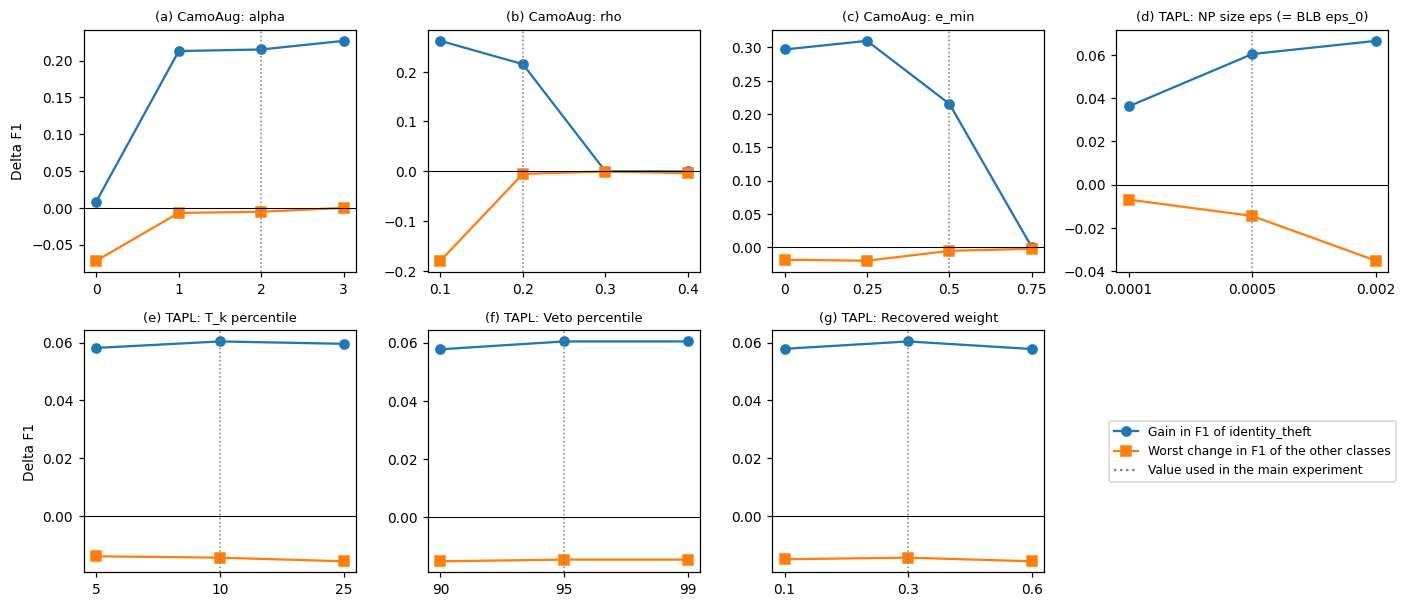

In [47]:
rows_a, rows_c = [], []
for sd in SEEDS["sensitivity"]:
    plain, KS, fb = build_static(S, sd)
    f1p = per_class_f1(S.yte, plain.predict_proba(S.Xte))
    f0 = fb["f0"]; Pf = f0.predict_proba(S.Xte); f1f = per_class_f1(S.yte, Pf)
    # CamoAug hyper-parameters (static), difference to A1
    for pname, grid in [("alpha", [0.0, 1.0, 2.0, 3.0]), ("rho", [0.1, 0.2, 0.3, 0.4]), ("e_min", [0.0, 0.25, 0.5, 0.75])]:
        for v in grid:
            kw = dict(CFG["final"]); kw[pname] = v
            fa = fb if v == CFG["final"][pname] else train_camoaug(S, sd, kw["alpha"], kw["rho"], kw["e_min"], plain, KS)
            f1c = per_class_f1(S.yte, fa["f0"].predict_proba(S.Xte))
            rows_a.append(dict(component="CamoAug", param=pname, value=v, seed=sd, default=v == CFG["final"][pname],
                               target_gain=f1c[TARGET] - f1p[TARGET],
                               worst_other=min(f1c[c] - f1p[c] for c in range(K) if c != TARGET)))
    # TAPL hyper-parameters (full method), difference to f0
    for pname, grid in [("rec_fpr", [1e-4, 5e-4, 2e-3]), ("conf_q", [5, 10, 25]), ("veto_pct", [90, 95, 99]),
                        ("w_recover", [0.1, 0.3, 0.6])]:
        for v in grid:
            p = dict(TAPL); p[pname] = v
            cal_ = calibrate_tapl(S, f0, p)
            f1r = per_class_f1(S.yte, apply_bias(run_tapl(S, f0, sd, cal_, params=p).P, cal_["bias"]))
            rows_c.append(dict(component="TAPL", param=pname, value=v, seed=sd, default=v == TAPL[pname],
                               target_gain=f1r[TARGET] - f1f[TARGET],
                               worst_other=min(f1r[c] - f1f[c] for c in range(K) if c != TARGET)))
    print(f"  sensitivity: seed {sd} done")
SENS = pd.DataFrame(rows_a + rows_c)
SENS.to_csv(out_path("sensitivity_per_seed.csv"), index=False)
SM = SENS.drop(columns="seed").groupby(["component", "param", "value"], as_index=False, sort=False).mean()

_lab = {"alpha": "alpha", "rho": "rho", "e_min": "e_min", "rec_fpr": "NP size eps (= BLB eps_0)",
        "conf_q": "T_k percentile", "veto_pct": "Veto percentile", "w_recover": "Recovered weight"}
_fmt = lambda v: f"{v:g}"
rows12 = []
for (comp, pname), g_ in SM.groupby(["component", "param"], sort=False):
    rows12.append(dict(component=comp, parameter=_lab[pname], values=" / ".join(_fmt(v) for v in g_["value"]),
                       gain_in_f1_target=" / ".join(fmt_signed(v) for v in g_["target_gain"]),
                       worst_change_other_classes=" / ".join(fmt_signed(v) for v in g_["worst_other"])))
T12 = pd.DataFrame(rows12)
save_table(T12, "table12_sensitivity")

panels = [("CamoAug", "alpha"), ("CamoAug", "rho"), ("CamoAug", "e_min"),
          ("TAPL", "rec_fpr"), ("TAPL", "conf_q"), ("TAPL", "veto_pct"), ("TAPL", "w_recover")]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
axes = axes.ravel()
for i, (comp, pname) in enumerate(panels):
    ax = axes[i]
    g_ = SM[(SM.component == comp) & (SM.param == pname)]
    x = np.arange(len(g_))
    ax.plot(x, g_["target_gain"], "o-", color="#1f77b4", label=f"Gain in F1 of {TARGET_CLS}")
    ax.plot(x, g_["worst_other"], "s-", color="#ff7f0e", label="Worst change in F1 of the other classes")
    dflt = [k for k, v in enumerate(g_["value"]) if v == (CFG["final"].get(pname) if comp == "CamoAug" else TAPL[pname])]
    for k in dflt:
        ax.axvline(k, color="grey", ls=":", lw=1)
    ax.axhline(0, color="k", lw=0.7)
    ax.set_xticks(x); ax.set_xticklabels([_fmt(v) for v in g_["value"]])
    ax.set_title(f"({chr(97 + i)}) {comp}: {_lab[pname]}", fontsize=8.5)
    if i % 4 == 0:
        ax.set_ylabel("Delta F1")
axes[-1].axis("off")
h, l = axes[0].get_legend_handles_labels()
axes[-1].legend(h + [plt.Line2D([], [], color="grey", ls=":")], l + ["Value used in the main experiment"], loc="center")
plt.tight_layout(); save_fig(fig, "figure7_sensitivity"); plt.show()

### Selection procedure for rho and e_min without the stream
The rule below uses only TRAIN and VALIDATION. It was written after the parameter values had been frozen and checks
whether the frozen pair can be reproduced without stream data. The frozen values are **not** replaced.

1. Grid rho in {0.1, 0.2, 0.3, 0.4} x e_min in {0, 0.25, 0.5, 0.75} (alpha = 2), each candidate trained on TRAIN only.
2. Generic camouflage on VALIDATION: the three strongest TRAIN markers of **every** fraud class are overwritten with
   values of random TRAIN `legit` rows.
3. **Safety** on clean VALIDATION: macro-F1 may not fall more than 0.01 below A1, and no class may fall by more than
   max(0.01, 1/n_c), where n_c is the number of VALIDATION rows of the class.
4. **Gain:** mean recall of the camouflaged VALIDATION rows (classes with at least 20 rows), minus A1.
5. The safe candidate with the largest gain is selected; candidates within 0.01 of it form a plateau (conservative
   choice: smallest rho, then largest e_min).

In [48]:
SEL_RHO = [0.1, 0.2, 0.3, 0.4]
SEL_EMIN = [0.0, 0.25, 0.5, 0.75]
M_SEL = 3                  # markers overwritten per class
MIN_ROWS = 20              # a class needs at least this many VALIDATION rows to enter the GAIN
PLATEAU_TOL = 0.01         # candidates within this distance of the best GAIN are treated as equivalent
SEL_SEEDS = SEEDS["selection"]
SEL_MAJOR = int(np.argmax(np.bincount(S.ytr)))
SEL_TOL = np.array([max(CFG["margin"], 1.0 / max(int((S.yva == c).sum()), 1)) for c in range(K)])
print("Per-class safety tolerance on VALIDATION:", {CLASSES[c]: round(float(SEL_TOL[c]), 4) for c in range(K)})


def camouflage_validation(S_, KS_, seed, m=M_SEL):
    """Generic simulator on VALIDATION: top-m TRAIN markers of each fraud class replaced by TRAIN legit values."""
    rng = np.random.default_rng(seed + 9000)
    legit_tr = np.where(S_.ytr == SEL_MAJOR)[0]
    Xc = S_.Xva.copy()
    for c in AUG_CLASSES:
        rows = np.where(S_.yva == c)[0]
        if len(rows) == 0:
            continue
        for j in np.argsort(-KS_[c])[:m]:
            Xc[rows, j] = S_.Xtr[rng.choice(legit_tr, len(rows)), j]
    return Xc


def recall_by_class(y, P, classes):
    pred = P.argmax(1)
    return np.array([float((pred[y == c] == c).mean()) if (y == c).sum() >= MIN_ROWS else np.nan for c in classes])


def run_selection_rho_emin():
    sel_rows = []
    for sd in SEL_SEEDS:
        plain, KS, _ = build_static(S, sd)
        Xcam = camouflage_validation(S, KS, sd)
        f1_plain = per_class_f1(S.yva, plain.predict_proba(S.Xva))
        rec_plain = recall_by_class(S.yva, plain.predict_proba(Xcam), AUG_CLASSES)
        for rho in SEL_RHO:
            for e_min in SEL_EMIN:
                fa = train_camoaug(S, sd, CFG["final"]["alpha"], rho, e_min, plain, KS)
                f1c = per_class_f1(S.yva, fa["f0"].predict_proba(S.Xva))
                rec = recall_by_class(S.yva, fa["f0"].predict_proba(Xcam), AUG_CLASSES)
                sel_rows.append(dict(
                    rho=rho, e_min=e_min, seed=sd, n_synthetic=fa["n_synthetic"],
                    clean_macro_diff=float(f1c.mean() - f1_plain.mean()),
                    clean_worst_diff=float(min(f1c[c] - f1_plain[c] for c in range(K))),
                clean_worst_slack=float(min(f1c[c] - f1_plain[c] + SEL_TOL[c] for c in range(K))),
                    gain_camo_recall=float(np.nanmean(rec - rec_plain)),
                    **{f"gain_{CLASSES[c]}": float(r - rp) for c, r, rp in zip(AUG_CLASSES, rec, rec_plain)}))
        print(f"  selection: seed {sd} done")

    SEL = pd.DataFrame(sel_rows).drop(columns="seed").groupby(["rho", "e_min"], as_index=False).mean()
    SEL["safe"] = (SEL["clean_macro_diff"] >= -CFG["margin"]) & (SEL["clean_worst_slack"] >= 0)
    cand = SEL[SEL["safe"]]
    if len(cand):
        best = cand["gain_camo_recall"].max()
        plateau = cand[cand["gain_camo_recall"] >= best - PLATEAU_TOL].sort_values(["rho", "e_min"], ascending=[True, False])
        chosen = plateau.iloc[0]
    else:
        plateau, chosen = cand, None
    SEL["in_plateau"] = SEL.set_index(["rho", "e_min"]).index.isin(plateau.set_index(["rho", "e_min"]).index) if len(cand) else False
    SEL["selected"] = False
    if chosen is not None:
        SEL.loc[(SEL["rho"] == chosen["rho"]) & (SEL["e_min"] == chosen["e_min"]), "selected"] = True
    SEL["frozen"] = (SEL["rho"] == CFG["final"]["rho"]) & (SEL["e_min"] == CFG["final"]["e_min"])
    SEL.to_csv(os.path.join(TAB_DIR, "results_selection_rho_emin.csv"), index=False)

    print("\nSelection procedure - candidates (mean over seeds; differences to A1 on VALIDATION)")
    print(f"SAFETY: clean macro-F1 >= -{CFG['margin']} and every class >= -max({CFG['margin']}, 1/n_c) "
          f"(clean_worst_slack >= 0) | GAIN: recall of camouflaged VALIDATION rows")
    print(SEL.round(4).to_string(index=False))
    print(f"\nSeeds: {SEL_SEEDS} | markers overwritten per class: {M_SEL} | classes in GAIN: "
          f"{[CLASSES[c] for c in AUG_CLASSES if (S.yva == c).sum() >= MIN_ROWS]}")
    fro = SEL[SEL["frozen"]].iloc[0]
    print(f"Frozen pair (rho={CFG['final']['rho']}, e_min={CFG['final']['e_min']}): safe={bool(fro['safe'])}, "
          f"gain={fro['gain_camo_recall']:.4f}")
    if chosen is None:
        print("No candidate satisfies the safety condition on VALIDATION.")
    else:
        print(f"Selected by the procedure: rho={chosen['rho']}, e_min={chosen['e_min']} "
              f"(gain={chosen['gain_camo_recall']:.4f}); candidates in the plateau: {len(plateau)}")
        print(f"Frozen pair equals the selected pair: "
              f"{(chosen['rho'], chosen['e_min']) == (CFG['final']['rho'], CFG['final']['e_min'])}; "
              f"frozen pair inside the plateau: {bool(fro['in_plateau'])}")
    print("The frozen values are not replaced; the main results are unchanged.")
    return SEL


SEL_TABLE = run_selection_rho_emin()

EXTRA["selection_n_safe"] = int(SEL_TABLE["safe"].sum())


Per-class safety tolerance on VALIDATION: {'legit': 0.01, 'identity_theft': 0.01, 'account_takeover': 0.01, 'card_testing': 0.0104, 'fraud_ring': 0.0135, 'synthetic_identity': 0.0217}
  selection: seed 42 done
  selection: seed 43 done
  selection: seed 44 done

Selection procedure - candidates (mean over seeds; differences to A1 on VALIDATION)
SAFETY: clean macro-F1 >= -0.01 and every class >= -max(0.01, 1/n_c) (clean_worst_slack >= 0) | GAIN: recall of camouflaged VALIDATION rows
   rho  e_min  n_synthetic  clean_macro_diff  clean_worst_diff  clean_worst_slack  gain_camo_recall  gain_identity_theft  gain_account_takeover  gain_card_testing  gain_fraud_ring  gain_synthetic_identity  safe  in_plateau  selected  frozen
0.1000 0.0000    3300.0000           -0.0843           -0.2542            -0.2442            0.3023               0.6396                 0.5075             0.0278           0.0180                   0.3188 False       False     False   False
0.1000 0.2500    3114.6667     

## Leakage audit

1. **Source lint:** the source of every method and calibration function is scanned for any access to the stream labels.
2. **Class-agnostic lint:** the TAPL functions and the pseudo-label comparators must not refer to a particular class.
   CamoAug refers to `AUG_CLASSES` on purpose (the largest class is not augmented).
3. **Label-randomisation test:** the April labels are replaced by random classes and every retraining and augmentation method
   (and the BLB-only variant) is re-run with the same seed. If a method used the stream labels, its predictions would
   change. A difference is re-checked with the original labels to separate leakage from non-determinism.

In [49]:
audited = [ks_power, gen_class, total_budget, alloc_fragility, fragility_scores, train_plain, fit_augmented, train_camoaug,
           smote_class, adasyn_weights, mixup_class, scarf_class, train_augmentation, _copy_categorical,
           apply_bias, fpr_per_class, calibrate_blb, calibrate_tapl, run_stream, naive_filter, make_fixmatch_filter,
           make_freematch_filter, make_tapl_filter, run_tapl, iw_weights, run_iw, run_ct, build_static]
pattern = re.compile(r"\byte\b|\by_te\b|\.yte\b")
lint = []
for fn in audited:
    src = inspect.getsource(fn)
    hits = [ln.strip() for ln in src.splitlines() if not ln.strip().startswith("#") and pattern.search(ln.split("#")[0])]
    lint.append(dict(function=fn.__name__, uses_stream_labels=bool(hits), lines=hits[:2]))
L = pd.DataFrame(lint)
print(L.to_string(index=False))
assert not L["uses_stream_labels"].any(), "A method accesses stream labels!"
print("\nSource lint passed: no method or calibration function touches the stream labels.")

agnostic = [calibrate_tapl, calibrate_blb, fpr_per_class, make_tapl_filter, run_tapl, run_stream, apply_bias,
            naive_filter, make_fixmatch_filter, make_freematch_filter]
cls_pat = r"\bMAJOR\b|\bAUG_CLASSES\b|\bTARGET\b|\bTARGET_CLS\b|" + "|".join(re.escape(f'"{c}"') for c in CLASSES)
L2 = pd.DataFrame([dict(function=fn.__name__,
                        refers_to_a_particular_class=bool(re.search(cls_pat, "\n".join(l.split("#")[0] for l in inspect.getsource(fn).splitlines()))))
                   for fn in agnostic])
print("\nClass-agnostic lint (TAPL and the pseudo-label comparators)")
print(L2.to_string(index=False))
assert not L2["refers_to_a_particular_class"].any(), "A class-agnostic function refers to a particular class!"
print("Class-agnostic lint passed.")

             function  uses_stream_labels lines
             ks_power               False    []
            gen_class               False    []
         total_budget               False    []
      alloc_fragility               False    []
     fragility_scores               False    []
          train_plain               False    []
        fit_augmented               False    []
        train_camoaug               False    []
          smote_class               False    []
       adasyn_weights               False    []
          mixup_class               False    []
          scarf_class               False    []
   train_augmentation               False    []
    _copy_categorical               False    []
           apply_bias               False    []
        fpr_per_class               False    []
        calibrate_blb               False    []
       calibrate_tapl               False    []
           run_stream               False    []
         naive_filter               Fals

In [50]:
def predictions_for_audit(S_, seed):
    """Re-run every retraining and augmentation method (and T7) on split S_; returns {method: predicted classes}."""
    plain, KS, fb = build_static(S_, seed)
    f0 = fb["f0"]; P_f0 = f0.predict_proba(S_.Xte); cal = calibrate_tapl(S_, f0)
    out = {M["A1"]: plain.predict_proba(S_.Xte).argmax(1), M["R0"]: P_f0.argmax(1),
           M["T7"]: apply_bias(P_f0, cal["bias"]).argmax(1)}
    for key, kind in [("A2", "SMOTE"), ("A3", "Mixup"), ("A4", "SCARF"), ("A5", "ADASYN")]:
        out[M[key]] = train_augmentation(S_, seed, kind)[0].predict_proba(S_.Xte).argmax(1)
    out[M["R1"]] = run_stream(S_, f0, seed, naive_filter).P.argmax(1)
    out[M["R2"]] = run_stream(S_, f0, seed, make_fixmatch_filter(CFG["fixmatch_tau"])).P.argmax(1)
    out[M["R3"]] = run_stream(S_, f0, seed, make_freematch_filter()).P.argmax(1)
    out[M["R4"]] = run_iw(S_, f0, seed).P.argmax(1)
    out[M["R5"]] = run_ct(S_, f0, seed, cal).P.argmax(1)
    out[M["R6"]] = apply_bias(run_tapl(S_, f0, seed, cal).P, cal["bias"]).argmax(1)
    return out


sd = SEEDS["leakage"][0]
rng = np.random.default_rng(12345)
S_sh = dataclasses.replace(S, yte=rng.integers(0, K, len(S.yte)))      # labels replaced by random classes
assert not np.array_equal(S_sh.yte, S.yte)
print(f"Randomised stream labels: {(S_sh.yte != S.yte).mean():.1%} of rows changed label")
new = predictions_for_audit(S_sh, sd)
rows = []
for nm, pred in new.items():
    old = PRED_STORE[(nm, sd)]
    rows.append(dict(method=nm, seed=sd, identical_predictions=bool(np.array_equal(old, pred)), n_different=int((old != pred).sum())))
AUDIT = pd.DataFrame(rows)
if not AUDIT["identical_predictions"].all():
    print("Some predictions differ; re-running with the ORIGINAL labels to check for non-determinism ...")
    again = predictions_for_audit(S, sd)
    AUDIT["differs_also_with_original_labels"] = [bool((PRED_STORE[(m, sd)] != again[m]).any()) for m in AUDIT["method"]]
    AUDIT["leakage"] = ~AUDIT["identical_predictions"] & ~AUDIT["differs_also_with_original_labels"]
else:
    AUDIT["leakage"] = False
save_table(AUDIT, "results_leakage_audit")
print(f"\nSource lint: {len(audited)} functions checked. Label-randomisation test:",
      "PASSED (no method is influenced by the stream labels)" if not AUDIT["leakage"].any() else "FAILED")

Randomised stream labels: 83.1% of rows changed label
[saved tables/results_leakage_audit.csv]
                     method  seed  identical_predictions  n_different  leakage
         A1 No augmentation    42                   True            0    False
     R0 CamoAug (static f0)    42                   True            0    False
T7 BLB only (no retraining)    42                   True            0    False
                   A2 SMOTE    42                   True            0    False
                   A3 Mixup    42                   True            0    False
        A4 SCARF-style swap    42                   True            0    False
                  A5 ADASYN    42                   True            0    False
     R1 Naive self-training    42                   True            0    False
          R2 FixMatch-style    42                   True            0    False
         R3 FreeMatch-style    42                   True            0    False
                      R4 IW    42   

## Outputs

### Check against the values reported in the manuscript
The manuscript values below are **historical reference values typed from the article**; they are not used by any
computation. Each is printed next to the value computed by this run. A difference larger than the tolerance is
flagged for inspection; neither side is changed.

In [51]:
MANUSCRIPT = [  # (quantity, manuscript value, value of this run)
    ("macro-F1 A1", 0.9111, mean_of(M["A1"], "macro_f1")),
    ("F1 identity_theft A1", 0.5824, mean_of(M["A1"], TGT)),
    ("macro-F1 R0", 0.9457, mean_of(M["R0"], "macro_f1")),
    ("F1 identity_theft R0", 0.7839, mean_of(M["R0"], TGT)),
    ("macro-F1 R1", 0.9256, mean_of(M["R1"], "macro_f1")),
    ("macro-F1 R2", 0.9162, mean_of(M["R2"], "macro_f1")),
    ("macro-F1 R3", 0.9305, mean_of(M["R3"], "macro_f1")),
    ("macro-F1 R4", 0.9160, mean_of(M["R4"], "macro_f1")),
    ("macro-F1 R5", 0.9132, mean_of(M["R5"], "macro_f1")),
    ("macro-F1 R6", 0.9540, mean_of(M["R6"], "macro_f1")),
    ("F1 identity_theft R6", 0.8560, mean_of(M["R6"], TGT)),
    ("MCC R6", 0.916, mean_of(M["R6"], "mcc")),
    ("ECE R6", 0.0021, mean_of(M["R6"], "ece")),
    ("identity_theft detected R6", 722.9, EXTRA["tp_target_R6"]),
    ("extra fraud detected R6 vs A1", 330.3, EXTRA["e2e_extra_fraud"]),
    ("camouflaged rows above theta, A1", 0.003, EXTRA["camo_visible_to_np_plain"]),
    ("camouflaged rows above theta, f0", 0.606, EXTRA["camo_visible_to_np_camoaug"]),
    ("TAPL gain on f0", 0.0574, EXTRA["tapl_gain_on_camoaug"]),
    ("recall camouflaged R6", 0.578, EXTRA["recall_camouflaged_R6"]),
    ("F1 identity_theft A4", 0.6297, mean_of(M["A4"], TGT)),
    ("F1 identity_theft C1", 0.6141, mean_of(M["C1"], TGT)),
    ("F1 identity_theft C5", 0.8793, mean_of(M["C5"], TGT)),
    ("F1 identity_theft T2", 0.7496, mean_of(M["T2"], TGT)),
    ("F1 identity_theft T3", 0.8195, mean_of(M["T3"], TGT)),
    ("S1 macro-F1 R6", 0.950, float(T11.set_index("method").loc[M["R6"], "S1 macro-F1"])),
    ("S2 macro-F1 R6", 0.918, float(T11.set_index("method").loc[M["R6"], "S2 macro-F1"])),
    ("Spearman severity vs TAPL gain", 0.90, EXTRA["rho_severity_tapl"]),
    ("camouflaged identity_theft rows", 476, EXTRA["camouflaged_target_rows"]),
]
CHK = pd.DataFrame(MANUSCRIPT, columns=["quantity", "manuscript_value_historical", "this_run"])
CHK["abs_diff"] = (CHK["this_run"] - CHK["manuscript_value_historical"]).abs()
CHK["tolerance"] = np.where(CHK["manuscript_value_historical"].abs() > 2, 0.5, 0.002)
CHK["status"] = np.where(CHK["abs_diff"] <= CHK["tolerance"], "match", "CHECK")
save_table(CHK.round(4), "check_manuscript_vs_this_run")
if QUICK_TEST:
    print("\nQUICK_TEST = True: differences are expected; these numbers must not be reported.")

[saved tables/check_manuscript_vs_this_run.csv]
                        quantity  manuscript_value_historical  this_run  abs_diff  tolerance status
                     macro-F1 A1                       0.9111    0.9111    0.0000     0.0020  match
            F1 identity_theft A1                       0.5824    0.5824    0.0000     0.0020  match
                     macro-F1 R0                       0.9457    0.9457    0.0000     0.0020  match
            F1 identity_theft R0                       0.7839    0.7839    0.0000     0.0020  match
                     macro-F1 R1                       0.9256    0.9256    0.0000     0.0020  match
                     macro-F1 R2                       0.9162    0.9162    0.0000     0.0020  match
                     macro-F1 R3                       0.9305    0.9305    0.0000     0.0020  match
                     macro-F1 R4                       0.9160    0.9160    0.0000     0.0020  match
                     macro-F1 R5                    

### Saved files and run summary

In [52]:
EXP_REGISTRY = pd.DataFrame([
    ("EXP-01", "Dataset, data quality, split", "-", "predictor groups, chronological split"),
    ("EXP-02", "Exploratory analysis and camouflage", "seed 0 for KS", "class distribution, KS power, drift, camouflage profile"),
    ("EXP-03", "Main experiment", str(SEEDS["main"]), "retraining comparison, augmentation, ablations, per-batch F1"),
    ("EXP-04", "Mechanism runs", str(SEEDS["mechanism"]), "mechanism evidence"),
    ("EXP-05", "Rolling windows", str(SEEDS["rolling"]), "drift severity"),
    ("EXP-06", "Simulated scenarios", str(SEEDS["scenarios"]), "simulated drift scenarios"),
    ("EXP-07", "Sensitivity", str(SEEDS["sensitivity"]), "one-at-a-time sensitivity"),
    ("EXP-08", "Selection procedure", str(SEEDS["selection"]), "parameter selection check"),
    ("EXP-09", "Leakage audit", str(SEEDS["leakage"]), "leakage audit"),
    ("EXP-10", "Day-block bootstrap, prior-shift baseline, NP false positive rate, pairwise augmentation tests",
     str(SEEDS_DONE), "data-level uncertainty and supporting tests"),
], columns=["id", "experiment", "seeds", "supports"])
save_table(EXP_REGISTRY, "experiment_registry")
print()
for d_ in (TAB_DIR, FIG_DIR):
    print(f"{os.path.relpath(d_, OUT_DIR)}/")
    for f_ in sorted(os.listdir(d_)):
        print(f"   {f_}  ({os.path.getsize(os.path.join(d_, f_)) / 1024:.0f} KB)")
print(f"\nTotal wall time: {(time.time() - NOTEBOOK_T0) / 60:.1f} min | QUICK_TEST = {QUICK_TEST} | environment: {ENV}")
try:
    import zipfile
    _zp = os.path.join(OUT_DIR, "camoaug_tapl_journal_outputs.zip")
    with zipfile.ZipFile(_zp, "w", zipfile.ZIP_DEFLATED) as zf:
        for d_ in (TAB_DIR, FIG_DIR):
            for f_ in os.listdir(d_):
                zf.write(os.path.join(d_, f_), os.path.join(os.path.basename(d_), f_))
        for f_ in ("env.json", "config.json"):
            zf.write(os.path.join(OUT_DIR, f_), f_)
    print(f"All tables and figures archived in {_zp}")
except Exception as e:
    print(f"Archive not created ({type(e).__name__}: {e})")

[saved tables/experiment_registry.csv]
    id                                                                                     experiment                                    seeds                                                     supports
EXP-01                                                                   Dataset, data quality, split                                        -                        predictor groups, chronological split
EXP-02                                                            Exploratory analysis and camouflage                            seed 0 for KS      class distribution, KS power, drift, camouflage profile
EXP-03                                                                                Main experiment [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] retraining comparison, augmentation, ablations, per-batch F1
EXP-04                                                                                 Mechanism runs                     [42, 43, 44, 45, 46]   